# Parte 1 — Filtros de imágenes
Preparación de cuatro imágenes y experimentos de los Módulos A–E

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import hashlib
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

%matplotlib inline

SEED = 42
MAX_LADO = 512
np.random.seed(SEED)

BASE_DIR = Path(".")
IMG_DIR = BASE_DIR / "Imagenes"

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
from IPython.display import display, Markdown

In [ ]:
import os
from pathlib import Path
from google.colab import drive, files

# Opción para montar Google Drive si tus imágenes están guardadas allí
MONTRAR_DRIVE = False # @param {type:"boolean"}

# Asegurar que existan los directorios base
BASE_DIR = Path(".")
IMG_DIR = BASE_DIR / "Imagenes"
IMG_DIR.mkdir(parents=True, exist_ok=True)

if MONTRAR_DRIVE:
    drive.mount('/content/drive')
    # Modifica esta ruta según dónde guardes la carpeta del proyecto en tu Drive
    RUTA_DRIVE_PROYECTO = "/content/drive/MyDrive/Proyecto_Procesamiento_Imagenes"
    if os.path.exists(RUTA_DRIVE_PROYECTO):
        os.chdir(RUTA_DRIVE_PROYECTO)
        BASE_DIR = Path(".")
        IMG_DIR = BASE_DIR / "Imagenes"
        print(f"Cambiado el directorio de trabajo a: {os.getcwd()}")
    else:
        print(f"Advertencia: No se encontró la ruta {RUTA_DRIVE_PROYECTO} en Google Drive.")
else:
    print("Google Drive no seleccionado. Usando almacenamiento de sesión local de Colab.")

# Nombres de las imágenes que se necesitan para la correcta ejecución del código
imagenes_requeridas = [
    "imagen_1_natural.jpg",
    "imagen_2_propia.jpg",
    "imagen_3_ladrillos.jpg",
    "imagen_4_hoja.jpg"
]

# Comprobar si faltan imágenes de forma local para dar la opción de subirlas manualmente
archivos_faltantes = [img for img in imagenes_requeridas if not (IMG_DIR / img).is_file()]

if archivos_faltantes:
    print(f"\nFaltan {len(archivos_faltantes)} imágenes indispensables en la carpeta '{IMG_DIR}': {archivos_faltantes}")
    subir_ahora = True # @param {type:"boolean"}
    if subir_ahora:
        print("\nSelecciona y sube las imágenes faltantes desde tu equipo local:")
        subidos = files.upload()
        for nombre_archivo, contenido in subidos.items():
            if nombre_archivo in imagenes_requeridas:
                destino = IMG_DIR / nombre_archivo
                destino.write_bytes(contenido)
                print(f"✓ Guardado correctamente: {destino.absolute()}")
            else:
                print(f"⚠ El archivo subido '{nombre_archivo}' no está en la lista de imágenes del proyecto y se ha omitido.")
else:
    print("\n✓ ¡Todas las imágenes requeridas ya están presentes en la carpeta!")

print(f"\nDirectorio de imágenes listo en: {IMG_DIR.absolute()}")

Google Drive no seleccionado. Usando almacenamiento de sesión local de Colab.

Faltan 4 imágenes indispensables en la carpeta 'Imagenes': ['imagen_1_natural.jpg', 'imagen_2_propia.jpg', 'imagen_3_ladrillos.jpg', 'imagen_4_hoja.jpg']

Selecciona y sube las imágenes faltantes desde tu equipo local:


Saving imagen_1_natural.jpg to imagen_1_natural.jpg
Saving imagen_2_propia.jpg to imagen_2_propia.jpg
Saving imagen_3_ladrillos.jpg to imagen_3_ladrillos.jpg
Saving imagen_4_hoja.jpg to imagen_4_hoja.jpg
✓ Guardado correctamente: /content/Imagenes/imagen_1_natural.jpg
✓ Guardado correctamente: /content/Imagenes/imagen_2_propia.jpg
✓ Guardado correctamente: /content/Imagenes/imagen_3_ladrillos.jpg
✓ Guardado correctamente: /content/Imagenes/imagen_4_hoja.jpg

Directorio de imágenes listo en: /content/Imagenes


In [ ]:
def redimensionar_lado_maximo(imagen, max_lado=512):
    """Devuelve una copia con lado mayor limitado, sin ampliar ni cambiar el original."""
    if not isinstance(imagen, np.ndarray) or imagen.ndim not in (2, 3):
        raise ValueError("La imagen debe ser un arreglo 2D o 3D.")
    if imagen.size == 0:
        raise ValueError("La imagen no puede estar vacía.")
    if isinstance(max_lado, (bool, np.bool_)) or not isinstance(max_lado, (int, np.integer)) or max_lado < 1:
        raise ValueError("max_lado debe ser un entero positivo.")

    alto, ancho = imagen.shape[:2]
    lado_mayor = max(alto, ancho)
    if lado_mayor <= max_lado:
        return imagen.copy()

    escala = max_lado / lado_mayor
    nuevo_ancho = max(1, round(ancho * escala))
    nuevo_alto = max(1, round(alto * escala))
    return cv2.resize(imagen, (nuevo_ancho, nuevo_alto), interpolation=cv2.INTER_AREA)

roles_imagenes = {
    "imagen_1_natural.jpg": "Escena urbana: imagen natural principal.",
    "imagen_2_propia.jpg": "Fotografía propia de un control sobre fondo azul.",
    "imagen_3_ladrillos.jpg": "Textura regular de ladrillos.",
    "imagen_4_hoja.jpg": "Textura orgánica de una hoja.",
}
rutas_imagenes = {nombre: IMG_DIR / nombre for nombre in roles_imagenes}

archivos_faltantes = [str(ruta) for ruta in rutas_imagenes.values() if not ruta.is_file()]
if archivos_faltantes:
    raise FileNotFoundError(
        "Faltan archivos de imagen; ejecutar desde la raíz del proyecto:\n"
        + "\n".join(archivos_faltantes)
    )

hashes_originales = {
    nombre: hashlib.sha256(ruta.read_bytes()).hexdigest()
    for nombre, ruta in rutas_imagenes.items()
}

imagenes = {}
filas_originales = []
for nombre, ruta in rutas_imagenes.items():
    original_bgr = cv2.imread(str(ruta), cv2.IMREAD_COLOR)
    if original_bgr is None:
        raise ValueError(f"OpenCV no pudo decodificar el archivo: {ruta}")
    original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
    original_gris = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2GRAY)
    imagenes[nombre] = {
        "ruta": ruta,
        "rol": roles_imagenes[nombre],
        "original": {"bgr": original_bgr, "rgb": original_rgb, "gris": original_gris},
    }
    alto, ancho = original_bgr.shape[:2]
    filas_originales.append({
        "archivo": nombre,
        "existe": ruta.is_file(),
        "ancho_original": ancho,
        "alto_original": alto,
        "canales": original_bgr.shape[2],
        "tipo_dato": str(original_bgr.dtype),
    })

resumen_originales = pd.DataFrame(filas_originales)

filas_trabajo = []
for nombre, datos in imagenes.items():
    trabajo_bgr = redimensionar_lado_maximo(datos["original"]["bgr"], MAX_LADO)
    datos["trabajo"] = {
        "bgr": trabajo_bgr,
        "rgb": cv2.cvtColor(trabajo_bgr, cv2.COLOR_BGR2RGB),
        "gris": cv2.cvtColor(trabajo_bgr, cv2.COLOR_BGR2GRAY),
    }
    alto_original, ancho_original = datos["original"]["bgr"].shape[:2]
    alto_trabajo, ancho_trabajo = trabajo_bgr.shape[:2]
    filas_trabajo.append({
        "archivo": nombre,
        "ancho_original": ancho_original,
        "alto_original": alto_original,
        "ancho_trabajo": ancho_trabajo,
        "alto_trabajo": alto_trabajo,
        "escala_nominal": min(1.0, MAX_LADO / max(alto_original, ancho_original)),
    })

resumen_trabajo = pd.DataFrame(filas_trabajo)

assert len(imagenes) == 4, "Deben cargarse las cuatro imágenes."
for nombre, datos in imagenes.items():
    original = datos["original"]
    trabajo = datos["trabajo"]
    assert np.array_equal(original["rgb"], original["bgr"][:, :, ::-1]), f"Conversión RGB incorrecta: {nombre}"
    assert np.array_equal(trabajo["rgb"], trabajo["bgr"][:, :, ::-1]), f"Conversión RGB de trabajo incorrecta: {nombre}"
    assert original["gris"].shape == original["bgr"].shape[:2]
    assert trabajo["gris"].shape == trabajo["bgr"].shape[:2]
    assert not np.shares_memory(original["bgr"], trabajo["bgr"]), f"La copia comparte memoria: {nombre}"

    alto, ancho = original["bgr"].shape[:2]
    alto_trabajo, ancho_trabajo = trabajo["bgr"].shape[:2]
    escala = min(1.0, MAX_LADO / max(alto, ancho))
    assert max(alto_trabajo, ancho_trabajo) <= MAX_LADO
    assert (ancho_trabajo, alto_trabajo) == (max(1, round(ancho * escala)), max(1, round(alto * escala)))
    hash_actual = hashlib.sha256(datos["ruta"].read_bytes()).hexdigest()
    assert hash_actual == hashes_originales[nombre], f"El archivo original cambió: {nombre}"


tabla_imagenes = pd.DataFrame([
    {"archivo": nombre,
     "original (ancho × alto)": f"{datos['original']['bgr'].shape[1]} × {datos['original']['bgr'].shape[0]}",
     "trabajo (ancho × alto)": f"{datos['trabajo']['bgr'].shape[1]} × {datos['trabajo']['bgr'].shape[0]}"}
    for nombre, datos in imagenes.items()
])
tabla_imagenes

,archivo,original (ancho × alto),trabajo (ancho × alto)
0,imagen_1_natural.jpg,2984 × 3984,383 × 512
1,imagen_2_propia.jpg,3000 × 4000,384 × 512
2,imagen_3_ladrillos.jpg,2268 × 4032,288 × 512
3,imagen_4_hoja.jpg,2340 × 4160,288 × 512


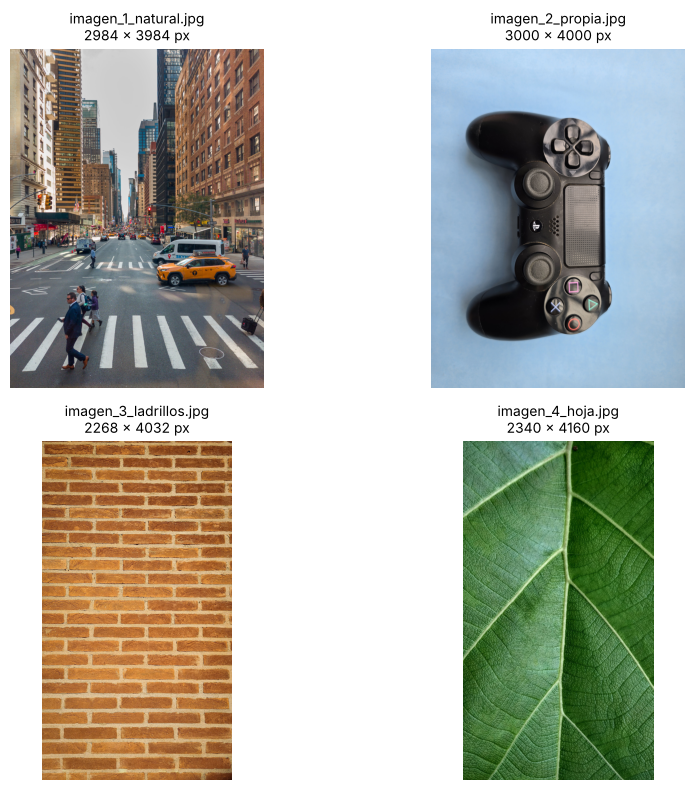

In [ ]:
figura_originales, ejes_originales = plt.subplots(2, 2, figsize=(10, 8))
titulos_originales = [
    f"{nombre}\n{datos['original']['rgb'].shape[1]} × {datos['original']['rgb'].shape[0]} px"
    for nombre, datos in imagenes.items()
]
for eje, datos, titulo in zip(ejes_originales.flat, imagenes.values(), titulos_originales):
    eje.imshow(datos["original"]["rgb"])
    eje.set_title(titulo, fontsize=10)
    eje.axis("off")
figura_originales.tight_layout()
plt.show()
plt.close(figura_originales)

In [ ]:
def mostrar_imagen(imagen, titulo="", tam_fig=(6, 4), eje=None):
    """Muestra gris o RGB/RGBA, oculta ejes y devuelve (figura, eje)."""
    datos = np.asarray(imagen)
    es_gris = datos.ndim == 2
    es_color = datos.ndim == 3 and datos.shape[2] in (3, 4)
    if datos.size == 0 or not (es_gris or es_color):
        raise ValueError("Se requiere una imagen gris 2D o RGB/RGBA con 3/4 canales.")

    crear_figura = eje is None
    if crear_figura:
        figura, eje = plt.subplots(figsize=tam_fig)
    else:
        figura = eje.figure

    if es_gris:
        limites = {"vmin": 0, "vmax": 255} if datos.dtype == np.uint8 else {}
        eje.imshow(datos, cmap="gray", **limites)
    else:
        eje.imshow(datos)
    eje.set_title(titulo)
    eje.axis("off")
    if crear_figura:
        figura.tight_layout()
        plt.show()
    return figura, eje


def mostrar_comparacion(imagen_a, imagen_b, titulo_a="Imagen A", titulo_b="Imagen B", tam_fig=(12, 5)):
    """Muestra dos imágenes con títulos independientes; devuelve (figura, ejes)."""
    figura, ejes = plt.subplots(1, 2, figsize=tam_fig)
    mostrar_imagen(imagen_a, titulo_a, eje=ejes[0])
    mostrar_imagen(imagen_b, titulo_b, eje=ejes[1])
    figura.tight_layout()
    plt.show()
    return figura, ejes


def mostrar_grid(imagenes, titulos=None, n_columnas=None, tam_fig=None):
    """Organiza imágenes mixtas en una cuadrícula y oculta paneles sobrantes."""
    lista_imagenes = list(imagenes)
    cantidad = len(lista_imagenes)
    if cantidad == 0:
        raise ValueError("La lista de imágenes no puede estar vacía.")
    lista_titulos = [""] * cantidad if titulos is None else list(titulos)
    if len(lista_titulos) != cantidad:
        raise ValueError("Debe haber un título por imagen.")
    if n_columnas is None:
        n_columnas = int(np.ceil(np.sqrt(cantidad)))
    if isinstance(n_columnas, (bool, np.bool_)) or not isinstance(n_columnas, (int, np.integer)) or n_columnas < 1:
        raise ValueError("n_columnas debe ser un entero positivo.")

    n_columnas = min(n_columnas, cantidad)
    n_filas = int(np.ceil(cantidad / n_columnas))
    if tam_fig is None:
        tam_fig = (5 * n_columnas, 4 * n_filas)
    figura, ejes = plt.subplots(n_filas, n_columnas, figsize=tam_fig, squeeze=False)
    for eje, imagen, titulo in zip(ejes.flat, lista_imagenes, lista_titulos):
        mostrar_imagen(imagen, titulo, eje=eje)
    for eje in list(ejes.flat)[cantidad:]:
        eje.axis("off")
    figura.tight_layout()
    plt.show()
    return figura, ejes

def normalizar_visualizacion(imagen):
    """Devuelve una copia float64 en [0, 1], exclusiva para visualización."""
    datos = np.asarray(imagen)
    if datos.size == 0 or datos.dtype.kind not in "buif":
        raise ValueError("Se requieren datos numéricos reales no vacíos.")
    datos = datos.astype(np.float64, copy=True)
    if not np.isfinite(datos).all():
        raise ValueError("La visualización no admite valores NaN o infinitos.")
    minimo, maximo = datos.min(), datos.max()
    if maximo == minimo:
        return np.zeros_like(datos)
    return (datos - minimo) / (maximo - minimo)


def calcular_metricas(imagen_referencia, imagen_evaluada, data_range=None):
    """Calcula PSNR y SSIM sin normalizar, recortar ni modificar las entradas."""
    referencia = np.asarray(imagen_referencia)
    evaluada = np.asarray(imagen_evaluada)
    if referencia.shape != evaluada.shape:
        raise ValueError("Las imágenes deben tener exactamente la misma forma.")
    if referencia.ndim not in (2, 3) or referencia.size == 0:
        raise ValueError("Se requieren imágenes no vacías, en gris 2D o RGB.")
    if referencia.ndim == 3 and referencia.shape[2] != 3:
        raise ValueError("Las imágenes de color deben tener tres canales RGB.")
    for datos in (referencia, evaluada):
        if datos.dtype.kind not in "buif" or not np.isfinite(datos).all():
            raise ValueError("Las imágenes deben contener datos numéricos reales y finitos.")
    lado_menor = min(referencia.shape[:2])
    if lado_menor < 3:
        raise ValueError("SSIM requiere al menos 3 píxeles en cada dimensión espacial.")

    if data_range is None:
        mismo_tipo = referencia.dtype == evaluada.dtype
        if mismo_tipo and referencia.dtype.kind in "ui":
            limites = np.iinfo(referencia.dtype)
            data_range = float(int(limites.max) - int(limites.min))
        elif mismo_tipo and referencia.dtype.kind == "b":
            data_range = 1.0
        elif (
            referencia.dtype.kind == evaluada.dtype.kind == "f"
            and referencia.min() >= 0 and referencia.max() <= 1
            and evaluada.min() >= 0 and evaluada.max() <= 1
        ):
            data_range = 1.0
        else:
            raise ValueError("Indica data_range explícitamente para estos tipos o rangos de datos.")
    if not np.isscalar(data_range) or isinstance(data_range, (bool, np.bool_)):
        raise ValueError("data_range debe ser un número positivo y finito.")
    data_range = float(data_range)
    if not np.isfinite(data_range) or data_range <= 0:
        raise ValueError("data_range debe ser un número positivo y finito.")

    # La conversión numérica no cambia el rango ni normaliza las intensidades.
    referencia = referencia.astype(np.float64, copy=False)
    evaluada = evaluada.astype(np.float64, copy=False)
    ventana = min(7, lado_menor)
    if ventana % 2 == 0:
        ventana -= 1
    valor_psnr = (
        float("inf") if np.array_equal(referencia, evaluada)
        else peak_signal_noise_ratio(referencia, evaluada, data_range=data_range)
    )
    valor_ssim = structural_similarity(
        referencia, evaluada, data_range=data_range,
        channel_axis=-1 if referencia.ndim == 3 else None,
        win_size=ventana,
    )
    return {"PSNR": float(valor_psnr), "SSIM": float(valor_ssim)}

## Módulo A
### A.1 — Convolución manual
Kernel asimétrico 3×3 normalizado; bordes CONSTANT, REPLICATE y REFLECT.
Se compara la convolución manual con `filter2D` usando el kernel volteado, errores y cinco mediciones de tiempo.

In [ ]:
imagenes_limpias_A = {
    nombre: imagenes[nombre]["trabajo"]["gris"]
    for nombre in ("imagen_1_natural.jpg", "imagen_2_propia.jpg")
}
huellas_limpias_A = {
    nombre: hashlib.sha256(imagen.tobytes()).hexdigest()
    for nombre, imagen in imagenes_limpias_A.items()
}
imagen_natural_A = imagenes_limpias_A["imagen_1_natural.jpg"]
imagen_natural_A_f64 = imagen_natural_A.astype(np.float64)


def medir_tiempos_A(operacion, repeticiones):
    """Mide solo la llamada de filtrado y devuelve el último resultado y los segundos."""
    duraciones = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        resultado = operacion()
        duraciones.append(time.perf_counter() - inicio)
    return resultado, np.asarray(duraciones, dtype=np.float64)


def mostrar_resultados_con_error_A(original, resultado_a, resultado_b, error, titulo_a, titulo_b):
    """Compara intensidades en [0,255] y muestra el error con su escala cuantitativa."""
    figura, ejes = plt.subplots(2, 2, figsize=(10, 8))
    for eje, datos, titulo in zip(
        ejes.flat, (original, resultado_a, resultado_b), ("Original", titulo_a, titulo_b)
    ):
        mostrar_imagen(datos, titulo, eje=eje)
        eje.images[0].set_clim(0, 255)
    eje_error = ejes[1, 1]
    mapa = eje_error.imshow(error, cmap="magma", vmin=0, vmax=max(float(error.max()), 1e-12))
    eje_error.set_title(f"Error absoluto · máximo {error.max():.3e}")
    eje_error.axis("off")
    figura.colorbar(mapa, ax=eje_error, shrink=0.8, label="Intensidad")
    figura.tight_layout()
    plt.show()
    plt.close(figura)

def convolucion_manual(imagen, kernel, border_type=cv2.BORDER_REFLECT):
    """Convolución 2D centrada, con exactamente dos ciclos sobre la imagen."""
    datos = np.asarray(imagen, dtype=np.float64)
    pesos = np.asarray(kernel, dtype=np.float64)
    if datos.ndim != 2 or datos.size == 0 or not np.isfinite(datos).all():
        raise ValueError("La imagen debe ser gris 2D, no vacía y finita.")
    if pesos.ndim != 2 or pesos.size == 0 or any(lado % 2 == 0 for lado in pesos.shape):
        raise ValueError("El kernel debe ser 2D, no vacío y con ambas dimensiones impares.")
    if not np.isfinite(pesos).all():
        raise ValueError("El kernel debe contener valores finitos.")
    if border_type not in (cv2.BORDER_CONSTANT, cv2.BORDER_REPLICATE, cv2.BORDER_REFLECT):
        raise ValueError("Borde admitido: CONSTANT, REPLICATE o REFLECT.")

    alto_kernel, ancho_kernel = pesos.shape
    radio_y, radio_x = alto_kernel // 2, ancho_kernel // 2
    extendida = cv2.copyMakeBorder(datos, radio_y, radio_y, radio_x, radio_x, border_type, value=0)
    kernel_volteado = pesos[::-1, ::-1]
    salida = np.empty(datos.shape, dtype=np.float64)
    for y in range(datos.shape[0]):
        for x in range(datos.shape[1]):
            vecindario = extendida[y:y + alto_kernel, x:x + ancho_kernel]
            salida[y, x] = np.sum(vecindario * kernel_volteado)
    return salida


kernel_convolucion = np.array([[0, 1, 0], [0, 2, 1], [0, 0, 0]], dtype=np.float64) / 4
kernel_correlacion_A = kernel_convolucion[::-1, ::-1].copy()
tipos_borde_A = {
    "CONSTANT (0)": cv2.BORDER_CONSTANT,
    "REPLICATE": cv2.BORDER_REPLICATE,
    "REFLECT": cv2.BORDER_REFLECT,
}
comparaciones_convolucion_A = {}
filas_convolucion_A = []
for nombre_borde, tipo_borde in tipos_borde_A.items():
    manual, tiempos_manual = medir_tiempos_A(
        lambda: convolucion_manual(imagen_natural_A_f64, kernel_convolucion, tipo_borde), 5
    )
    opencv, tiempos_opencv = medir_tiempos_A(
        lambda: cv2.filter2D(imagen_natural_A_f64, cv2.CV_64F, kernel_correlacion_A, borderType=tipo_borde), 5
    )
    error = np.abs(manual - opencv)
    comparaciones_convolucion_A[nombre_borde] = {"manual": manual, "opencv": opencv, "error": error}
    filas_convolucion_A.append({
        "borde": nombre_borde, "error_maximo": error.max(), "error_medio": error.mean(),
        "manual_promedio_ms": 1000 * tiempos_manual.mean(),
        "manual_std_ms": 1000 * tiempos_manual.std(ddof=1),
        "opencv_promedio_ms": 1000 * tiempos_opencv.mean(),
        "opencv_std_ms": 1000 * tiempos_opencv.std(ddof=1),
        "aceleracion_opencv": tiempos_manual.mean() / tiempos_opencv.mean(),
        "repeticiones": 5,
    })
tabla_convolucion_A = pd.DataFrame(filas_convolucion_A)
tabla_convolucion_A[["borde", "error_maximo", "error_medio", "manual_promedio_ms", "opencv_promedio_ms"]].round(4)

,borde,error_maximo,error_medio,manual_promedio_ms,opencv_promedio_ms
0,CONSTANT (0),0.0,0.0,567.7913,0.3222
1,REPLICATE,0.0,0.0,574.7414,0.2776
2,REFLECT,0.0,0.0,533.0408,0.2772


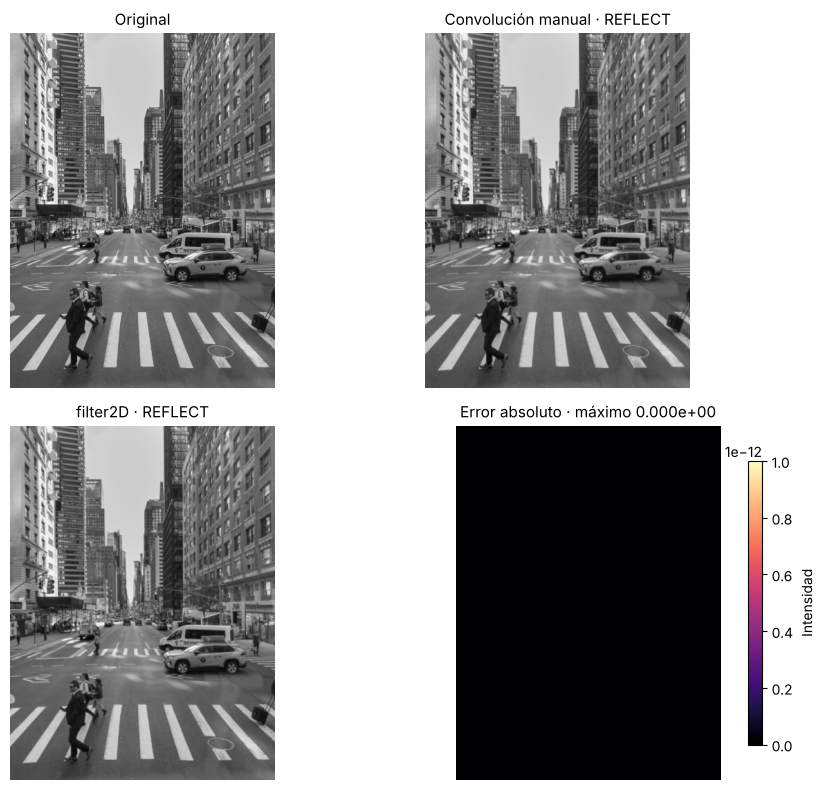

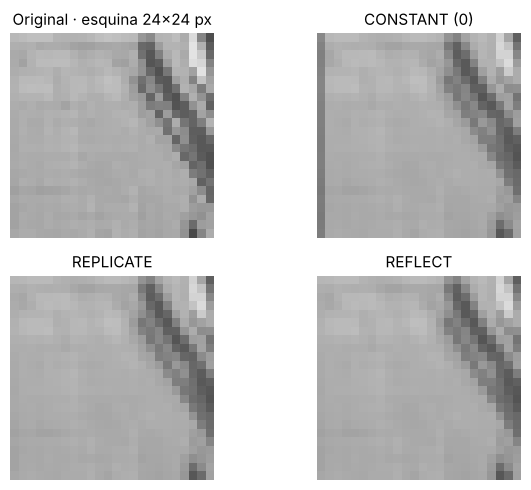

In [ ]:
datos_reflect = comparaciones_convolucion_A["REFLECT"]
mostrar_resultados_con_error_A(
    imagen_natural_A, datos_reflect["manual"], datos_reflect["opencv"], datos_reflect["error"],
    "Convolución manual · REFLECT", "filter2D · REFLECT",
)

# Un recorte de 24×24 px permite distinguir el efecto del padding en la esquina superior izquierda.
figura_esquina, ejes_esquina = plt.subplots(2, 2, figsize=(7, 5))
datos_esquina = [("Original · esquina 24×24 px", imagen_natural_A)] + [
    (nombre, datos["manual"]) for nombre, datos in comparaciones_convolucion_A.items()
]
for eje, (titulo, datos) in zip(ejes_esquina.flat, datos_esquina):
    mostrar_imagen(datos[:24, :24], titulo, eje=eje)
    eje.images[0].set_clim(0, 255)
figura_esquina.tight_layout()
plt.show()
plt.close(figura_esquina)

Los errores máximo y medio son cero en los tres bordes: ambas implementaciones coinciden.
CONSTANT oscurece la esquina; REPLICATE y REFLECT coinciden para este kernel de radio 1. `filter2D` reduce el tiempo de ejecución.

### A.2 — Modelos de ruido
En ambas imágenes: gaussiano σ=10 y 25, sal y pimienta 5% y 15%, y speckle σ=0.10.
Se muestran las imágenes y sus histogramas con la misma generación reproducible.

In [ ]:
def validar_gris_uint8_A(imagen):
    datos = np.asarray(imagen)
    if datos.ndim != 2 or datos.size == 0 or datos.dtype != np.uint8:
        raise ValueError("Se requiere una imagen gris 2D no vacía de tipo uint8.")
    return datos


def agregar_ruido_gaussiano(imagen, sigma=10, rng=None):
    """Añade ruido N(0,sigma²), sin modificar la imagen de entrada."""
    datos = validar_gris_uint8_A(imagen)
    if not np.isfinite(sigma) or sigma < 0:
        raise ValueError("sigma debe ser no negativo y finito.")
    rng = np.random.default_rng(SEED) if rng is None else rng
    ruido = rng.normal(0, sigma, datos.shape)
    return np.rint(np.clip(datos.astype(np.float64) + ruido, 0, 255)).astype(np.uint8)


def agregar_ruido_sal_pimienta(imagen, cantidad=0.05, rng=None):
    """Asigna extremos a una fracción de píxeles únicos, aproximadamente mitad de cada tipo."""
    datos = validar_gris_uint8_A(imagen)
    if not np.isfinite(cantidad) or not 0 <= cantidad <= 1:
        raise ValueError("cantidad debe estar entre 0 y 1.")
    rng = np.random.default_rng(SEED) if rng is None else rng
    salida = datos.copy()
    numero = round(cantidad * datos.size)
    indices = rng.choice(datos.size, size=numero, replace=False)
    numero_sal = numero // 2
    salida.flat[indices[:numero_sal]] = 255
    salida.flat[indices[numero_sal:]] = 0
    return salida


def agregar_ruido_speckle(imagen, sigma_speckle=0.10, rng=None):
    """Ruido multiplicativo en [0,1], seguido de regreso a unidades de 8 bits."""
    datos = validar_gris_uint8_A(imagen)
    if not np.isfinite(sigma_speckle) or sigma_speckle < 0:
        raise ValueError("sigma_speckle debe ser no negativo y finito.")
    rng = np.random.default_rng(SEED) if rng is None else rng
    normalizada = datos.astype(np.float64) / 255
    ruido = rng.normal(0, sigma_speckle, datos.shape)
    resultado = normalizada + normalizada * ruido
    return np.rint(255 * np.clip(resultado, 0, 1)).astype(np.uint8)


def generar_casos_ruido_A(imagenes_limpias):
    """Genera los diez casos con un único flujo aleatorio reproducible."""
    rng = np.random.default_rng(SEED)
    resultados = {}
    for nombre, limpia in imagenes_limpias.items():
        resultados[nombre] = {
            "Gaussiano σ=10": agregar_ruido_gaussiano(limpia, 10, rng),
            "Gaussiano σ=25": agregar_ruido_gaussiano(limpia, 25, rng),
            "Sal y pimienta 5%": agregar_ruido_sal_pimienta(limpia, 0.05, rng),
            "Sal y pimienta 15%": agregar_ruido_sal_pimienta(limpia, 0.15, rng),
            "Speckle σ=0.10": agregar_ruido_speckle(limpia, 0.10, rng),
        }
    return resultados


imagenes_ruidosas_A = generar_casos_ruido_A(imagenes_limpias_A)
estadisticas_ruido_A = pd.DataFrame([
    {
        "imagen": nombre, "ruido": nombre_ruido,
        "media_intensidad": ruidosa.mean(),
        "RMSE_ruido": np.sqrt(np.mean((ruidosa.astype(np.float64) - imagenes_limpias_A[nombre]) ** 2)),
        "porcentaje_extremos": 100 * np.mean((ruidosa == 0) | (ruidosa == 255)),
    }
    for nombre, casos in imagenes_ruidosas_A.items() for nombre_ruido, ruidosa in casos.items()
])

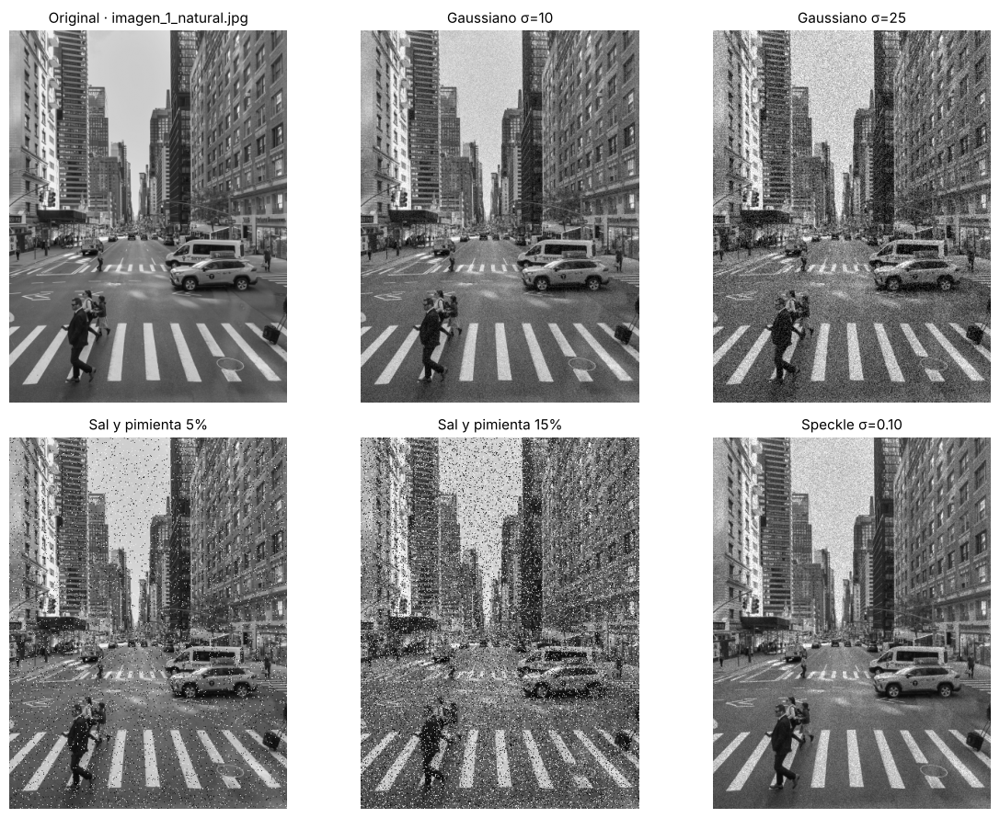

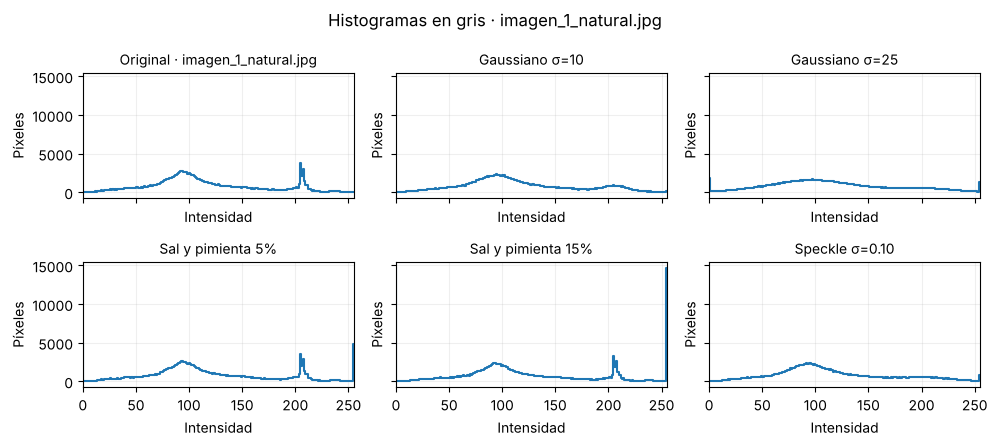

**Escena natural:** σ=25 altera más las intensidades que σ=10; sal y pimienta concentra píxeles en 0 y 255. El speckle varía con el brillo local.

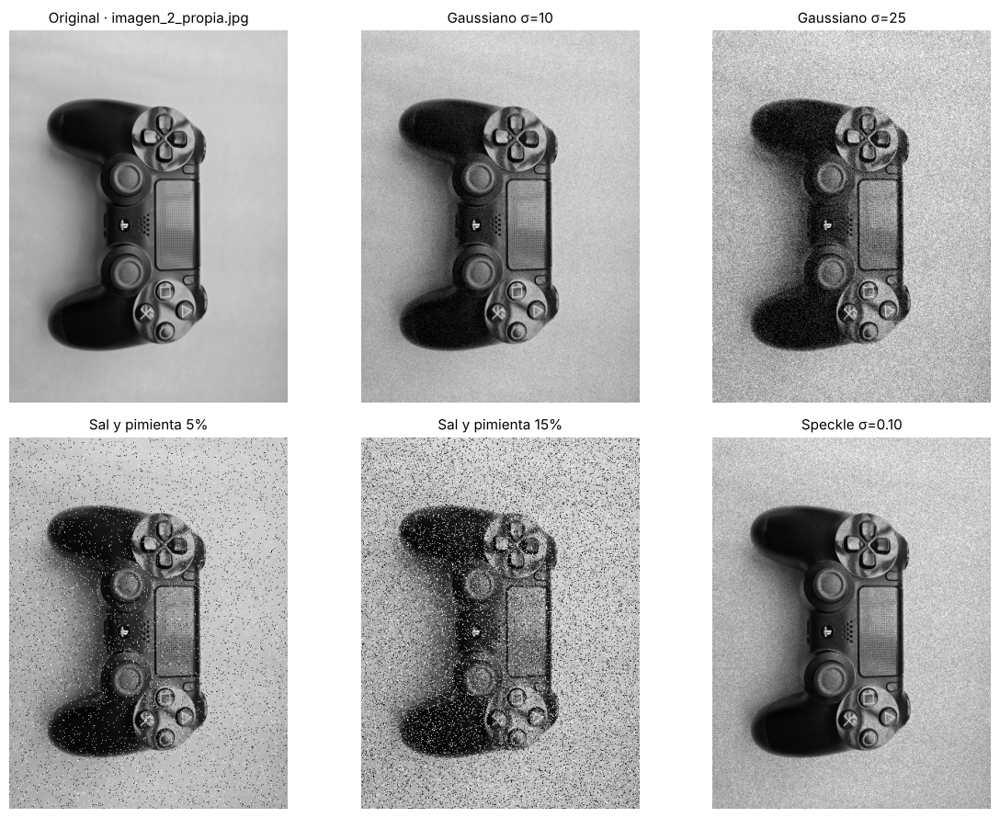

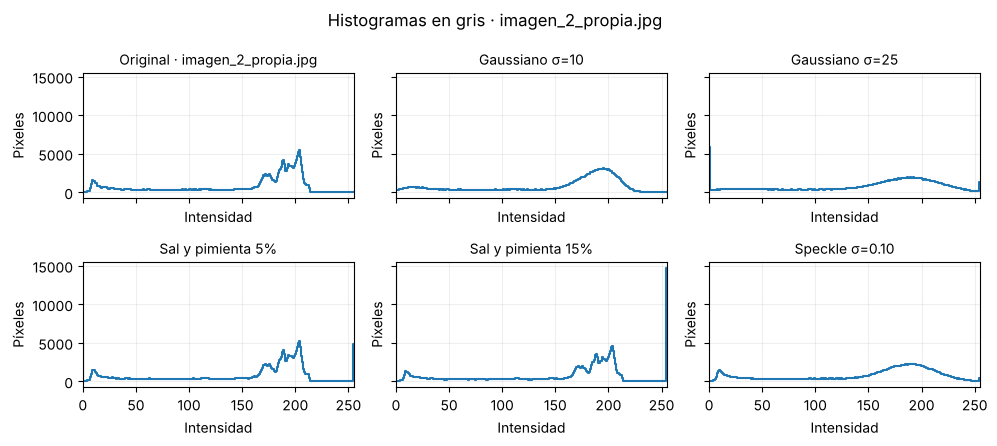

**Fotografía propia:** los impulsos destacan sobre las zonas uniformes; aumentar su proporción de 5% a 15% refuerza los picos del histograma en los extremos.

In [ ]:
observaciones_ruido_A = {
    "imagen_1_natural.jpg": "**Escena natural:** σ=25 altera más las intensidades que σ=10; sal y pimienta concentra píxeles en 0 y 255. El speckle varía con el brillo local.",
    "imagen_2_propia.jpg": "**Fotografía propia:** los impulsos destacan sobre las zonas uniformes; aumentar su proporción de 5% a 15% refuerza los picos del histograma en los extremos.",
}
for nombre, casos in imagenes_ruidosas_A.items():
    datos = [imagenes_limpias_A[nombre]] + list(casos.values())
    titulos = [f"Original · {nombre}"] + list(casos)
    figura, _ = mostrar_grid(datos, titulos, n_columnas=3, tam_fig=(12, 9))
    plt.close(figura)

    figura, ejes = plt.subplots(2, 3, figsize=(10, 4.5), sharex=True, sharey=True)
    for eje, imagen, titulo in zip(ejes.flat, datos, titulos):
        conteos = np.bincount(imagen.ravel(), minlength=256)
        eje.step(np.arange(256), conteos, where="mid")
        eje.set_xlim(0, 255)
        eje.set_title(titulo, fontsize=10)
        eje.set_xlabel("Intensidad")
        eje.set_ylabel("Píxeles")
        eje.grid(alpha=0.2)
    figura.suptitle(f"Histogramas en gris · {nombre}")
    figura.tight_layout()
    plt.show()
    plt.close(figura)
    display(Markdown(observaciones_ruido_A[nombre]))

### A.3 — Batalla de filtros
Se conservan 26 configuraciones de ocho familias: 260 restauraciones y diez referencias sin filtrar.
La selección usa máximo SSIM y desempata por PSNR dentro de una tolerancia de 10⁻⁶.
Los promedios por familia usan su mejor configuración en cada caso; la selección global fija una configuración para los diez casos.

In [ ]:
kernel_ponderado_A = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float64) / 16


def filtrar_A(imagen, filtro, parametros):
    """Aplica una configuración de restauración en gris y devuelve una nueva matriz."""
    datos = validar_gris_uint8_A(imagen)
    if filtro == "Media":
        k = parametros["k"]
        return cv2.boxFilter(datos, cv2.CV_64F, (k, k), normalize=True, borderType=cv2.BORDER_REFLECT)
    if filtro == "Promedio ponderado":
        kernel = np.asarray(parametros["kernel"], dtype=np.float64)
        return cv2.filter2D(datos, cv2.CV_64F, kernel, borderType=cv2.BORDER_REFLECT)
    if filtro == "Gaussiano":
        k = 2 * int(np.ceil(3 * parametros["sigma"])) + 1
        return cv2.GaussianBlur(datos.astype(np.float64), (k, k), parametros["sigma"], borderType=cv2.BORDER_REFLECT)
    if filtro == "Mediana":
        return cv2.medianBlur(datos, parametros["k"])
    if filtro in ("Mínimo", "Máximo"):
        k = parametros["k"]
        ventana = np.ones((k, k), dtype=np.uint8)
        operador = cv2.erode if filtro == "Mínimo" else cv2.dilate
        return operador(datos, ventana, borderType=cv2.BORDER_REFLECT)
    if filtro == "Bilateral":
        return cv2.bilateralFilter(datos, parametros["d"], parametros["sigmaColor"], parametros["sigmaSpace"], borderType=cv2.BORDER_REFLECT)
    if filtro == "Non-Local Means":
        return cv2.fastNlMeansDenoising(datos, None, h=parametros["h"], templateWindowSize=parametros["templateWindowSize"], searchWindowSize=parametros["searchWindowSize"])
    raise ValueError(f"Familia de filtro no reconocida: {filtro}")


configuraciones_filtros_A = []
for k in (3, 5, 9, 15):
    configuraciones_filtros_A.append({"filtro": "Media", "parametros": {"k": k}, "etiqueta": f"k={k}, normalize=True"})
configuraciones_filtros_A.append({"filtro": "Promedio ponderado", "parametros": {"kernel": kernel_ponderado_A.tolist()}, "etiqueta": "[1,2,1;2,4,2;1,2,1]/16"})
for sigma in (0.5, 1, 2, 4):
    k = 2 * int(np.ceil(3 * sigma)) + 1
    configuraciones_filtros_A.append({"filtro": "Gaussiano", "parametros": {"sigma": sigma}, "etiqueta": f"σ={sigma}, k={k}"})
for filtro, tamanos in (("Mediana", (3, 5, 7)), ("Mínimo", (3, 5)), ("Máximo", (3, 5))):
    for k in tamanos:
        configuraciones_filtros_A.append({"filtro": filtro, "parametros": {"k": k}, "etiqueta": f"k={k}"})
for d, sigma_color, sigma_space in ((5,75,75), (9,75,75), (15,75,75), (9,25,75), (9,150,75), (9,75,25), (9,75,150)):
    configuraciones_filtros_A.append({"filtro": "Bilateral", "parametros": {"d": d, "sigmaColor": sigma_color, "sigmaSpace": sigma_space}, "etiqueta": f"d={d}, σColor={sigma_color}, σSpace={sigma_space}"})
for h in (5, 10, 20):
    configuraciones_filtros_A.append({"filtro": "Non-Local Means", "parametros": {"h": h, "templateWindowSize": 7, "searchWindowSize": 21}, "etiqueta": f"h={h}, plantilla=7, búsqueda=21"})

configuracion_por_etiqueta_A = {
    (c["filtro"], c["etiqueta"]): c["parametros"] for c in configuraciones_filtros_A
}
filas_metricas_A = []
for nombre, casos in imagenes_ruidosas_A.items():
    limpia = imagenes_limpias_A[nombre]
    for nombre_ruido, ruidosa in casos.items():
        referencia_ruidosa = calcular_metricas(limpia, ruidosa, data_range=255)
        filas_metricas_A.append({
            "imagen": nombre, "ruido": nombre_ruido, "filtro": "Sin filtrar", "parametros": "—",
            **referencia_ruidosa,
            "PSNR_ruidosa": referencia_ruidosa["PSNR"], "SSIM_ruidosa": referencia_ruidosa["SSIM"],
            "delta_PSNR": 0.0, "delta_SSIM": 0.0,
        })
        for configuracion in configuraciones_filtros_A:
            filtrada = filtrar_A(ruidosa, configuracion["filtro"], configuracion["parametros"])
            puntuacion = calcular_metricas(limpia, filtrada, data_range=255)
            filas_metricas_A.append({
                "imagen": nombre, "ruido": nombre_ruido, "filtro": configuracion["filtro"], "parametros": configuracion["etiqueta"],
                **puntuacion,
                "PSNR_ruidosa": referencia_ruidosa["PSNR"], "SSIM_ruidosa": referencia_ruidosa["SSIM"],
                "delta_PSNR": puntuacion["PSNR"] - referencia_ruidosa["PSNR"],
                "delta_SSIM": puntuacion["SSIM"] - referencia_ruidosa["SSIM"],
            })
resultados_metricas_A = pd.DataFrame(filas_metricas_A)
print(f"260 restauraciones + 10 referencias; resultados_metricas_A: {resultados_metricas_A.shape}")
resultados_metricas_A.head()[["imagen", "ruido", "filtro", "parametros", "PSNR", "SSIM"]].round(4)

260 restauraciones + 10 referencias; resultados_metricas_A: (270, 10)


,imagen,ruido,filtro,parametros,PSNR,SSIM
0,imagen_1_natural.jpg,Gaussiano σ=10,Sin filtrar,—,28.1130,0.7688
1,imagen_1_natural.jpg,Gaussiano σ=10,Media,"k=3, normalize=True",25.7539,0.7964
2,imagen_1_natural.jpg,Gaussiano σ=10,Media,"k=5, normalize=True",23.0662,0.6705
3,imagen_1_natural.jpg,Gaussiano σ=10,Media,"k=9, normalize=True",20.7819,0.4930
4,imagen_1_natural.jpg,Gaussiano σ=10,Media,"k=15, normalize=True",19.2690,0.3834


In [ ]:
def elegir_fila_A(tabla, columna_ssim="SSIM", columna_psnr="PSNR", tolerancia_ssim=1e-6):
    """Máximo SSIM, con desempate por PSNR dentro de la tolerancia indicada."""
    candidatas = tabla[tabla[columna_ssim] >= tabla[columna_ssim].max() - tolerancia_ssim]
    return candidatas.sort_values([columna_psnr, columna_ssim, "filtro", "parametros"], ascending=[False, False, True, True]).iloc[0]


filtradas_A = resultados_metricas_A[resultados_metricas_A["filtro"] != "Sin filtrar"]
mejores_por_familia_A = pd.DataFrame([
    elegir_fila_A(grupo).to_dict()
    for _, grupo in filtradas_A.groupby(["imagen", "ruido", "filtro"], sort=False)
])
resumen_A = pd.DataFrame([
    elegir_fila_A(grupo).to_dict()
    for _, grupo in mejores_por_familia_A.groupby(["imagen", "ruido"], sort=False)
]).rename(columns={"filtro": "filtro_ganador", "parametros": "parametros_ganadores"})

# Solo se conservan las ocho imágenes seleccionadas por caso, no todas las salidas evaluadas.
mejores_resultados_A = {}
for nombre, casos in imagenes_ruidosas_A.items():
    mejores_resultados_A[nombre] = {}
    for nombre_ruido, ruidosa in casos.items():
        seleccion = mejores_por_familia_A[
            (mejores_por_familia_A["imagen"] == nombre) & (mejores_por_familia_A["ruido"] == nombre_ruido)
        ]
        lista_seleccion = []
        for _, fila in seleccion.iterrows():
            parametros = configuracion_por_etiqueta_A[(fila["filtro"], fila["parametros"])]
            salida = filtrar_A(ruidosa, fila["filtro"], parametros)
            mejores_resultados_A[nombre].setdefault(nombre_ruido, {})[fila["filtro"]] = salida
            etiqueta = fila["parametros"].replace(", σSpace=", "\nσSpace=").replace(", plantilla=7, búsqueda=21", "\nplantilla=7, búsqueda=21")
            lista_seleccion.append((salida, f"{fila['filtro']}\n{etiqueta}\nSSIM={fila['SSIM']:.4f}"))
resumen_A[["imagen", "ruido", "filtro_ganador", "parametros_ganadores", "PSNR", "SSIM"]].round(4)

,imagen,ruido,filtro_ganador,parametros_ganadores,PSNR,SSIM
0,imagen_1_natural.jpg,Gaussiano σ=10,Non-Local Means,"h=10, plantilla=7, búsqueda=21",30.9633,0.9164
1,imagen_1_natural.jpg,Gaussiano σ=25,Non-Local Means,"h=20, plantilla=7, búsqueda=21",25.2679,0.7822
2,imagen_1_natural.jpg,Sal y pimienta 5%,Mediana,k=3,26.7187,0.8585
3,imagen_1_natural.jpg,Sal y pimienta 15%,Mediana,k=3,25.4250,0.8303
4,imagen_1_natural.jpg,Speckle σ=0.10,Bilateral,"d=9, σColor=25, σSpace=75",28.8984,0.8461
5,imagen_2_propia.jpg,Gaussiano σ=10,Non-Local Means,"h=10, plantilla=7, búsqueda=21",37.3894,0.9638
6,imagen_2_propia.jpg,Gaussiano σ=25,Non-Local Means,"h=20, plantilla=7, búsqueda=21",31.1584,0.8592
7,imagen_2_propia.jpg,Sal y pimienta 5%,Mediana,k=3,34.8886,0.9649
8,imagen_2_propia.jpg,Sal y pimienta 15%,Mediana,k=3,32.0603,0.9493
9,imagen_2_propia.jpg,Speckle σ=0.10,Non-Local Means,"h=20, plantilla=7, búsqueda=21",34.8654,0.9360


In [ ]:
rendimiento_familias_A = mejores_por_familia_A.groupby("filtro", sort=False).agg(
    SSIM_adaptado=("SSIM", "mean"), PSNR_adaptado=("PSNR", "mean")
).reset_index()
rendimiento_configuraciones_A = filtradas_A.groupby(["filtro", "parametros"], sort=False).agg(
    SSIM_promedio=("SSIM", "mean"), PSNR_promedio=("PSNR", "mean"), casos=("SSIM", "size")
).reset_index()
rendimiento_global_familias_A = pd.DataFrame([
    elegir_fila_A(grupo, "SSIM_promedio", "PSNR_promedio").to_dict()
    for _, grupo in rendimiento_configuraciones_A.groupby("filtro", sort=False)
])
mejor_fila_global_A = elegir_fila_A(rendimiento_global_familias_A, "SSIM_promedio", "PSNR_promedio")
mejor_config_global_A = {
    "filtro": mejor_fila_global_A["filtro"],
    "parametros": dict(configuracion_por_etiqueta_A[(mejor_fila_global_A["filtro"], mejor_fila_global_A["parametros"])]),
    "SSIM_promedio": float(mejor_fila_global_A["SSIM_promedio"]),
    "PSNR_promedio": float(mejor_fila_global_A["PSNR_promedio"]),
    "casos": int(mejor_fila_global_A["casos"]),
}
tabla_rendimiento_familias_A = rendimiento_familias_A.merge(rendimiento_global_familias_A, on="filtro").sort_values("SSIM_adaptado", ascending=False)
tabla_rendimiento_familias_A[["filtro", "SSIM_adaptado", "PSNR_adaptado"]].round(4)

,filtro,SSIM_adaptado,PSNR_adaptado
3,Mediana,0.8354,28.1477
2,Gaussiano,0.7821,26.2647
6,Bilateral,0.7542,27.5369
0,Media,0.7494,25.1138
7,Non-Local Means,0.6791,25.6574
1,Promedio ponderado,0.6361,26.2957
5,Máximo,0.4022,13.3308
4,Mínimo,0.3599,13.8530


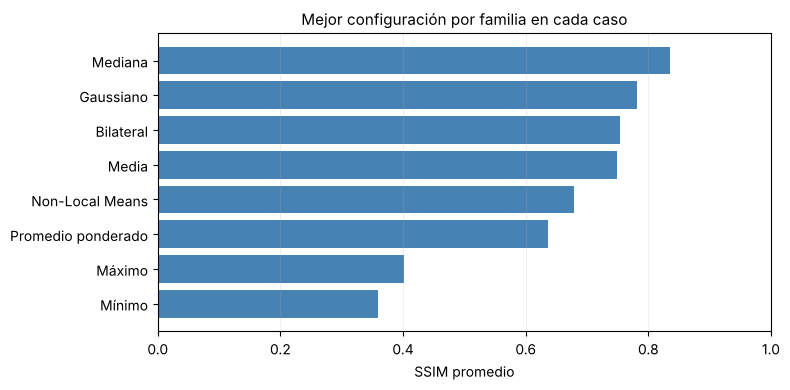

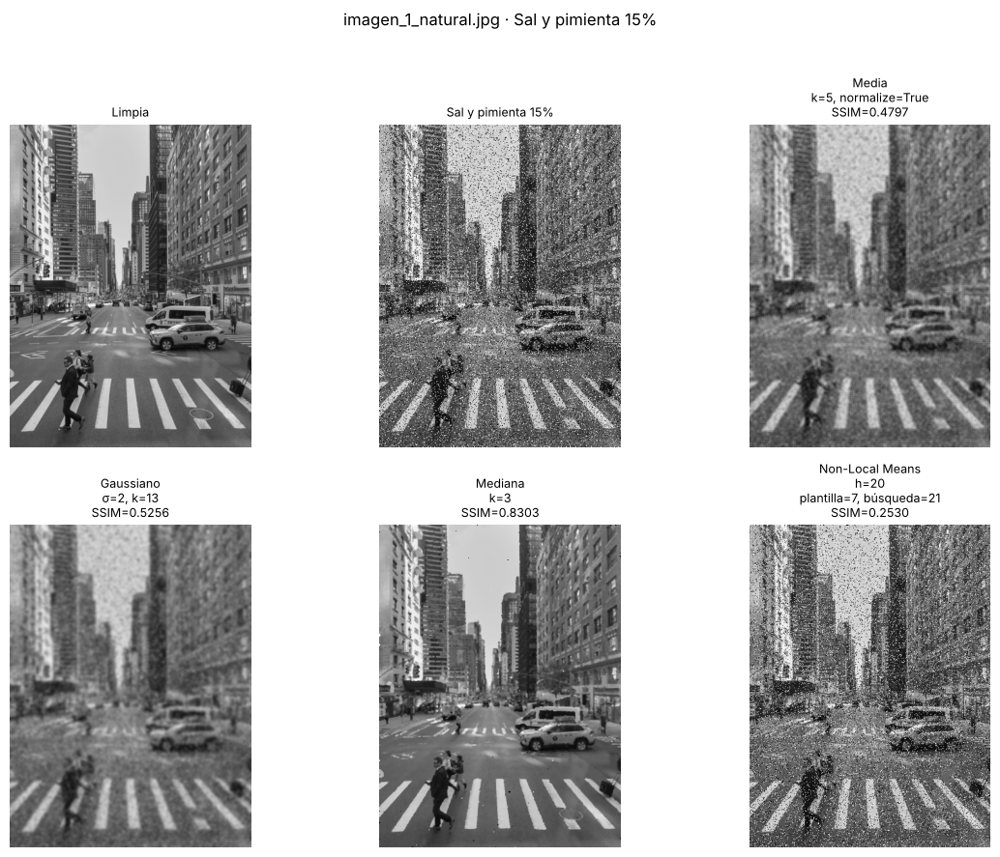

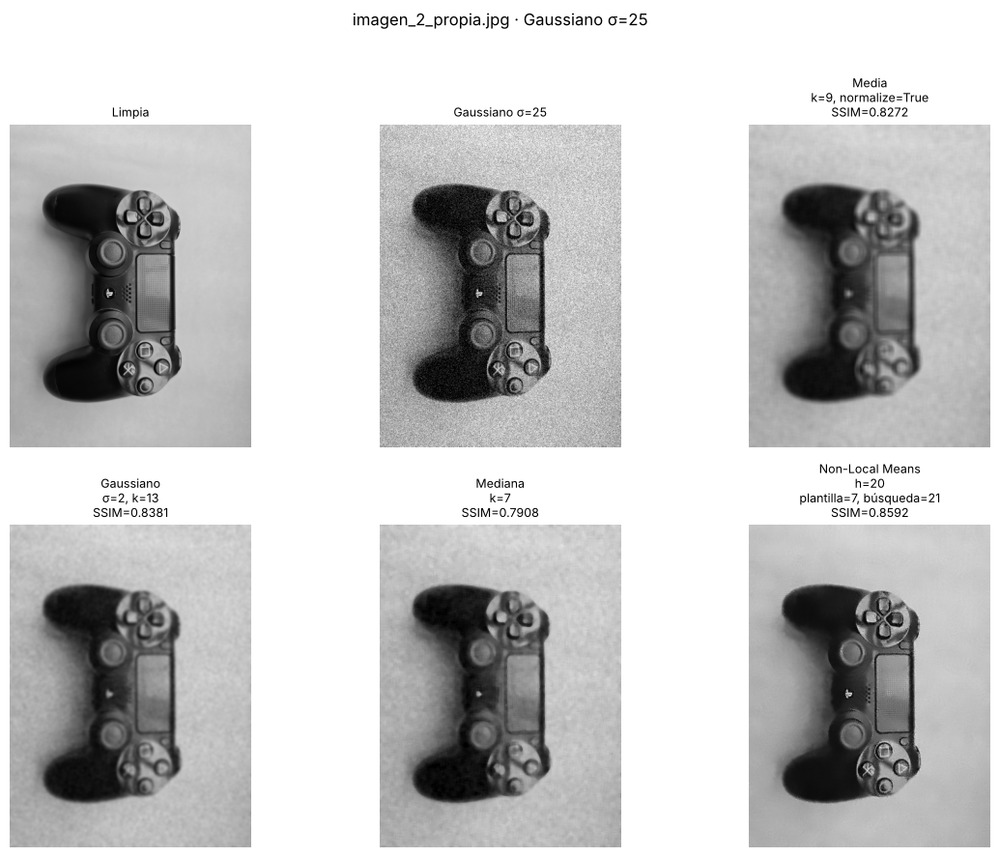

In [ ]:
orden_ruidos_A = list(next(iter(imagenes_ruidosas_A.values())))
ssim_por_ruido_A = mejores_por_familia_A.pivot_table(index="filtro", columns="ruido", values="SSIM", aggfunc="mean").reindex(
    index=tabla_rendimiento_familias_A["filtro"], columns=orden_ruidos_A
)

figura, eje = plt.subplots(figsize=(8, 4))
eje.barh(tabla_rendimiento_familias_A["filtro"], tabla_rendimiento_familias_A["SSIM_adaptado"], color="steelblue")
eje.invert_yaxis()
eje.set(xlim=(0, 1), xlabel="SSIM promedio", title="Mejor configuración por familia en cada caso")
eje.grid(axis="x", alpha=0.2)
figura.tight_layout()
plt.show()
plt.close(figura)

casos_visuales_A = [("imagen_1_natural.jpg", "Sal y pimienta 15%"),
                    ("imagen_2_propia.jpg", "Gaussiano σ=25")]
familias_visuales_A = ("Media", "Gaussiano", "Mediana", "Non-Local Means")
for nombre, nombre_ruido in casos_visuales_A:
    pares = [(imagenes_limpias_A[nombre], "Limpia"),
             (imagenes_ruidosas_A[nombre][nombre_ruido], nombre_ruido)]
    for familia in familias_visuales_A:
        fila = mejores_por_familia_A[
            (mejores_por_familia_A["imagen"] == nombre)
            & (mejores_por_familia_A["ruido"] == nombre_ruido)
            & (mejores_por_familia_A["filtro"] == familia)
        ].iloc[0]
        etiqueta = fila["parametros"].replace(", plantilla=7, búsqueda=21", "\nplantilla=7, búsqueda=21")
        pares.append((mejores_resultados_A[nombre][nombre_ruido][familia],
                      f"{familia}\n{etiqueta}\nSSIM={fila['SSIM']:.4f}"))
    figura, ejes = plt.subplots(2, 3, figsize=(12, 9))
    for eje, (datos, titulo) in zip(ejes.flat, pares):
        mostrar_imagen(datos, titulo, eje=eje)
        eje.images[0].set_clim(0, 255)
        eje.title.set_fontsize(9)
    figura.suptitle(f"{nombre} · {nombre_ruido}", fontsize=12)
    figura.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    plt.close(figura)

Non-Local Means gana los cuatro casos gaussianos y la mediana los cuatro de sal y pimienta.
Para speckle gana bilateral en la escena natural y Non-Local Means en la fotografía propia.
Los diez ganadores mejoran PSNR y SSIM frente al ruido; las matrices ilustran dos casos de la tabla.

### A.4 — Separabilidad del gaussiano
Kernel 1D de 31 muestras, σ=5; kernel 2D mediante `g1d @ g1d.T`.
Se comparan `filter2D` y `sepFilter2D` con borde REFLECT, errores y veinte mediciones por método.

In [ ]:
kernel_size_A = 31
sigma_separabilidad_A = 5
g1d = cv2.getGaussianKernel(kernel_size_A, sigma_separabilidad_A, cv2.CV_64F)
g2d = g1d @ g1d.T
coordenadas_A = np.arange(kernel_size_A, dtype=np.float64) - kernel_size_A // 2
xx_A, yy_A = np.meshgrid(coordenadas_A, coordenadas_A)
gaussiano_independiente_A = np.exp(-(xx_A**2 + yy_A**2) / (2 * sigma_separabilidad_A**2))
gaussiano_independiente_A /= gaussiano_independiente_A.sum()
error_kernel_A = np.max(np.abs(g2d - gaussiano_independiente_A))

tabla_kernel_A = pd.DataFrame([{
    "forma_1D": str(g1d.shape), "forma_2D": str(g2d.shape),
    "suma_1D": g1d.sum(), "suma_2D": g2d.sum(),
    "error_maximo_kernel_independiente": error_kernel_A,
}])

resultado_2d_A, tiempos_2d_A = medir_tiempos_A(
    lambda: cv2.filter2D(imagen_natural_A_f64, cv2.CV_64F, g2d, borderType=cv2.BORDER_REFLECT), 20
)
resultado_separable_A, tiempos_separables_A = medir_tiempos_A(
    lambda: cv2.sepFilter2D(imagen_natural_A_f64, cv2.CV_64F, g1d, g1d, borderType=cv2.BORDER_REFLECT), 20
)
error_separabilidad_A = np.abs(resultado_2d_A - resultado_separable_A)
tabla_separabilidad_A = pd.DataFrame([{
    "error_maximo": error_separabilidad_A.max(), "error_medio": error_separabilidad_A.mean(),
    "filter2D_promedio_ms": 1000 * tiempos_2d_A.mean(), "filter2D_std_ms": 1000 * tiempos_2d_A.std(ddof=1),
    "sepFilter2D_promedio_ms": 1000 * tiempos_separables_A.mean(), "sepFilter2D_std_ms": 1000 * tiempos_separables_A.std(ddof=1),
    "aceleracion_separable": tiempos_2d_A.mean() / tiempos_separables_A.mean(), "repeticiones": 20,
}])
tabla_separabilidad_A[["error_maximo", "error_medio", "filter2D_promedio_ms", "sepFilter2D_promedio_ms", "aceleracion_separable"]]

,error_maximo,error_medio,filter2D_promedio_ms,sepFilter2D_promedio_ms,aceleracion_separable
0,1.989520e-13,2.420824e-14,3.314397,1.946782,1.7025


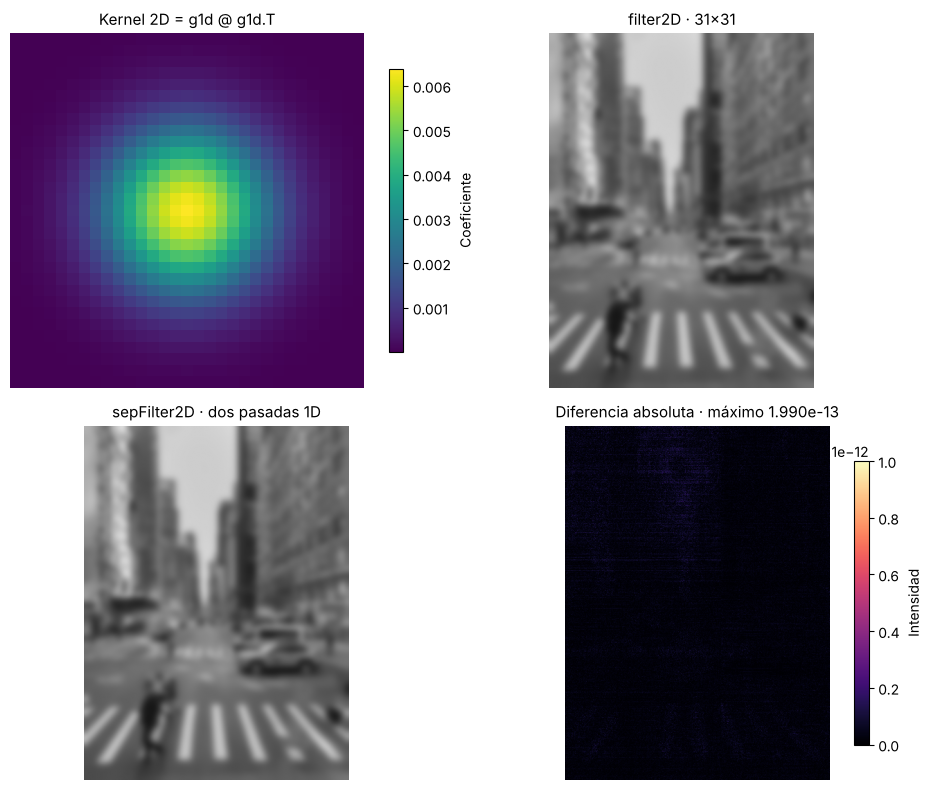

In [ ]:
figura, ejes = plt.subplots(2, 2, figsize=(10, 8))
mapa_kernel = ejes[0, 0].imshow(g2d, cmap="viridis")
ejes[0, 0].set_title("Kernel 2D = g1d @ g1d.T")
ejes[0, 0].axis("off")
figura.colorbar(mapa_kernel, ax=ejes[0, 0], shrink=0.8, label="Coeficiente")
for eje, salida, titulo in [(ejes[0, 1], resultado_2d_A, "filter2D · 31×31"),
                            (ejes[1, 0], resultado_separable_A, "sepFilter2D · dos pasadas 1D")]:
    mostrar_imagen(salida, titulo, eje=eje)
    eje.images[0].set_clim(0, 255)
mapa_error = ejes[1, 1].imshow(error_separabilidad_A, cmap="magma", vmin=0,
                              vmax=max(float(error_separabilidad_A.max()), 1e-12))
ejes[1, 1].set_title(f"Diferencia absoluta · máximo {error_separabilidad_A.max():.3e}")
ejes[1, 1].axis("off")
figura.colorbar(mapa_error, ax=ejes[1, 1], shrink=0.8, label="Intensidad")
figura.tight_layout()
plt.show()
plt.close(figura)

El producto externo coincide con el gaussiano 2D calculado independientemente.
Las salidas difieren solo por redondeo numérico (error máximo ≈2×10⁻¹³); la tabla muestra el tiempo y la aceleración medidos al ejecutar.

### Pregunta 1.1 — Media y mediana ante impulsos
La media incorpora los outliers 0 y 255 al promedio y los extiende a sus vecinos; la mediana toma el valor central ordenado y resiste impulsos aislados. Con sal y pimienta al 15% en la fotografía propia, mediana 3×3 obtiene PSNR=32.0603 dB y SSIM=0.9493, frente a PSNR=22.4154 dB y SSIM=0.7569 de la mejor media (15×15). Por eso la mediana conserva mejor la estructura en este tipo de ruido.

### Pregunta 1.2 — Box filter normalizado
Se compara el box 5×5 con y sin normalizar en ambas imágenes; se visualiza la escena natural.

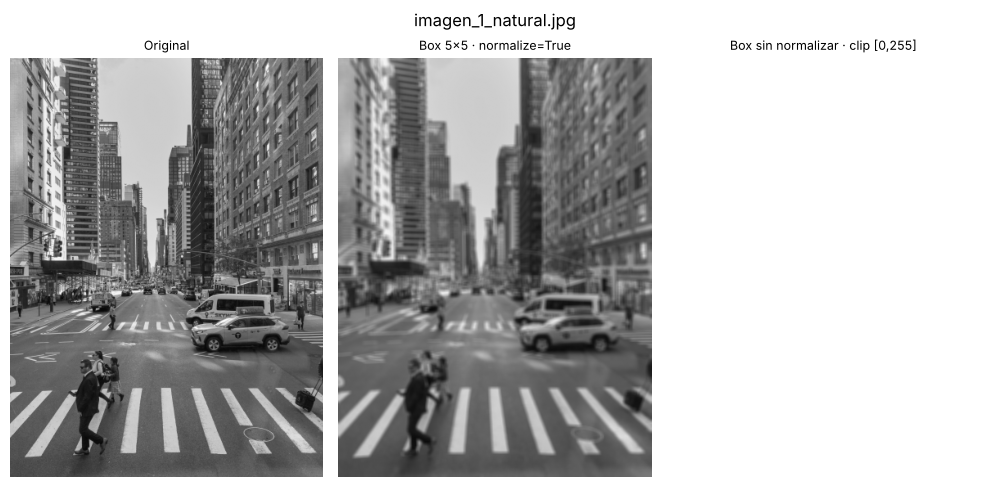

,imagen,suma_kernel_normalizado,suma_kernel_no_normalizado,media_original,media_box_normalizado,media_box_no_normalizado
0,imagen_1_natural.jpg,1.0,25.0,115.2011,115.2011,2880.0266
1,imagen_2_propia.jpg,1.0,25.0,150.8452,150.8452,3771.1291


In [ ]:
filas_normalizacion_A = []
for nombre, limpia in imagenes_limpias_A.items():
    datos = limpia.astype(np.float64)
    normalizado = cv2.boxFilter(datos, cv2.CV_64F, (5, 5), normalize=True, borderType=cv2.BORDER_REFLECT)
    no_normalizado = cv2.boxFilter(datos, cv2.CV_64F, (5, 5), normalize=False, borderType=cv2.BORDER_REFLECT)
    filas_normalizacion_A.append({
        "imagen": nombre, "suma_kernel_normalizado": np.ones((5, 5)).sum() / 25,
        "suma_kernel_no_normalizado": np.ones((5, 5)).sum(),
        "media_original": datos.mean(), "media_box_normalizado": normalizado.mean(),
        "media_box_no_normalizado": no_normalizado.mean(),
        "razon_medias_no_normalizado": no_normalizado.mean() / datos.mean(),
        "porcentaje_mayor_255": 100 * np.mean(no_normalizado > 255),
    })
    if nombre == "imagen_1_natural.jpg":
        figura, ejes = plt.subplots(1, 3, figsize=(10, 5))
        for eje, salida, titulo in zip(ejes, (datos, normalizado, np.clip(no_normalizado, 0, 255)),
                                      ("Original", "Box 5×5 · normalize=True", "Box sin normalizar · clip [0,255]")):
            mostrar_imagen(salida, titulo, eje=eje)
            eje.images[0].set_clim(0, 255)
            eje.title.set_fontsize(9)
        figura.suptitle(nombre)
        figura.tight_layout()
        plt.show()
        plt.close(figura)
tabla_normalizacion_A = pd.DataFrame(filas_normalizacion_A)
tabla_normalizacion_A[["imagen", "suma_kernel_normalizado", "suma_kernel_no_normalizado",
                       "media_original", "media_box_normalizado", "media_box_no_normalizado"]].round(4)

Normalizar divide la suma de 25 píxeles por 25: el kernel suma 1 y conserva el brillo medio. Sin normalizar, suma 25 y multiplica la media por 25 (115.2011→2880.0266 en la escena natural). Los cálculos conservan `float64`; el recorte a [0,255] se usa solo para mostrar la saturación.

### Pregunta 1.3 — Filtro bilateral
`sigmaSpace` controla la influencia de la distancia espacial y `sigmaColor` la tolerancia a diferencias de intensidad. Al limitar la mezcla entre intensidades distintas, el bilateral suaviza dentro de las regiones y conserva mejor sus bordes. Para gaussiano σ=10, con d=9 y sigmaSpace=75, subir sigmaColor de 25 a 150 reduce el SSIM medio de 0.9153 a 0.7611: mezclar más intensidades puede borrar estructura.

### Conclusión del Módulo A
La selección con PSNR/SSIM favorece Non-Local Means para ruido gaussiano y mediana para sal y pimienta. En speckle depende de la imagen: bilateral en la natural y Non-Local Means en la propia.

La mejor configuración fija de los diez casos queda en `mejor_config_global_A`: mediana 3×3, PSNR medio 28.5169 dB y SSIM medio 0.7789. La separabilidad reproduce el filtrado 2D con menor trabajo aritmético; los tiempos medidos permiten comprobar su beneficio en este equipo.

In [ ]:
assert resultados_metricas_A.shape == (270, 10)
assert len(configuraciones_filtros_A) == 26
assert len(mejores_por_familia_A) == 80 and len(resumen_A) == 10
assert (rendimiento_configuraciones_A["casos"] == 10).all()
assert set(mejores_por_familia_A["filtro"]) == {"Media", "Promedio ponderado", "Gaussiano", "Mediana", "Mínimo", "Máximo", "Bilateral", "Non-Local Means"}
assert resultados_metricas_A.groupby(["imagen", "ruido"]).size().eq(27).all()
assert resultados_metricas_A[["PSNR", "SSIM"]].apply(np.isfinite).all().all()
assert tabla_convolucion_A["error_maximo"].max() < 1e-10
assert g1d.shape == (31, 1) and g2d.shape == (31, 31)
assert np.isclose(g1d.sum(), 1) and np.isclose(g2d.sum(), 1)
assert error_kernel_A < 1e-12 and error_separabilidad_A.max() < 1e-8
assert len(tiempos_2d_A) == len(tiempos_separables_A) == 20
assert set(mejor_config_global_A) >= {"filtro", "parametros", "SSIM_promedio", "PSNR_promedio"}
ruido_verificacion_A = generar_casos_ruido_A(imagenes_limpias_A)
for nombre, casos in imagenes_ruidosas_A.items():
    assert len(casos) == 5
    assert hashlib.sha256(imagenes_limpias_A[nombre].tobytes()).hexdigest() == huellas_limpias_A[nombre]
    for tipo, ruidosa in casos.items():
        assert np.array_equal(ruidosa, ruido_verificacion_A[nombre][tipo])
        assert not np.shares_memory(ruidosa, imagenes_limpias_A[nombre])
        assert ruidosa.shape == imagenes_limpias_A[nombre].shape and ruidosa.dtype == np.uint8
for nombre, ruta_imagen in rutas_imagenes.items():
    assert hashlib.sha256(ruta_imagen.read_bytes()).hexdigest() == hashes_originales[nombre]
del ruido_verificacion_A
print("Validación completa: 260 restauraciones, 10 referencias y originales intactos.")

Validación completa: 260 restauraciones, 10 referencias y originales intactos.


## Módulo B — Realce y detección de bordes
Imágenes de trabajo: `imagen_1_natural.jpg` (escena urbana) e `imagen_2_propia.jpg` (control sobre fondo azul), ambas en gris `uint8` y con lado máximo de 512 px (las de la preparación). Todos los cálculos de derivadas se hacen en `float64` y sin recortar; el recorte solo se aplica al mostrar.

In [ ]:
# Figuras de los Módulos B–E: JPEG a 75 dpi para que el notebook con salidas guardadas pese poco
plt.rcParams["figure.dpi"] = 75
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg")

img_nat_B = imagenes["imagen_1_natural.jpg"]["trabajo"]["gris"]
img_prop_B = imagenes["imagen_2_propia.jpg"]["trabajo"]["gris"]
imagenes_B = {"Natural": img_nat_B, "Propia": img_prop_B}


def mostrar_firmado_B(eje, datos, titulo, percentil=99):
    """Muestra una respuesta con signo (derivadas) centrada en 0 y recortada solo para visualizar."""
    limite = np.percentile(np.abs(datos), percentil) or 1.0
    eje.imshow(datos, cmap="gray", vmin=-limite, vmax=limite)
    eje.set_title(titulo, fontsize=9)
    eje.axis("off")


def mostrar_magnitud_B(eje, datos, titulo, percentil=99):
    limite = np.percentile(datos, percentil) or 1.0
    eje.imshow(datos, cmap="gray", vmin=0, vmax=limite)
    eje.set_title(titulo, fontsize=9)
    eje.axis("off")


kernels_gradiente_B = {
    "Roberts": (np.array([[1, 0], [0, -1]], np.float64), np.array([[0, 1], [-1, 0]], np.float64)),
    "Prewitt": (np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float64),
                np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], np.float64)),
}


def gradiente_B(gris, metodo, ksize=3):
    """Devuelve Gx, Gy, magnitud y ángulo (grados en [0, 360)) en float64."""
    f = gris.astype(np.float64)
    if metodo in kernels_gradiente_B:
        kx, ky = kernels_gradiente_B[metodo]
        gx = cv2.filter2D(f, cv2.CV_64F, kx, borderType=cv2.BORDER_REPLICATE)
        gy = cv2.filter2D(f, cv2.CV_64F, ky, borderType=cv2.BORDER_REPLICATE)
    elif metodo == "Sobel":
        gx = cv2.Sobel(f, cv2.CV_64F, 1, 0, ksize=ksize, borderType=cv2.BORDER_REPLICATE)
        gy = cv2.Sobel(f, cv2.CV_64F, 0, 1, ksize=ksize, borderType=cv2.BORDER_REPLICATE)
    elif metodo == "Scharr":
        gx = cv2.Scharr(f, cv2.CV_64F, 1, 0, borderType=cv2.BORDER_REPLICATE)
        gy = cv2.Scharr(f, cv2.CV_64F, 0, 1, borderType=cv2.BORDER_REPLICATE)
    else:
        raise ValueError(f"Operador desconocido: {metodo}")
    return gx, gy, np.hypot(gx, gy), np.degrees(np.arctan2(gy, gx)) % 360


def mapa_hsv_gradiente_B(magnitud, angulo, percentil=99):
    """Matiz = ángulo del gradiente, saturación = 1, brillo = magnitud (recortada al percentil)."""
    brillo = np.clip(magnitud / (np.percentile(magnitud, percentil) or 1.0), 0, 1)
    hsv = np.dstack([angulo.astype(np.float32), np.ones_like(brillo, np.float32), brillo.astype(np.float32)])
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

### B.1 — Operadores de gradiente
Roberts (2×2), Prewitt (3×3), Sobel (3×3) y Scharr (3×3). Cada columna es un operador; las filas son $G_x$, $G_y$, la magnitud $|\nabla f|=\sqrt{G_x^2+G_y^2}$ y la dirección en HSV (matiz = ángulo $\theta=\mathrm{atan2}(G_y,G_x)$, brillo = magnitud). `cv2.filter2D`, `cv2.Sobel` y `cv2.Scharr` calculan correlación, por lo que el signo de $G$ depende de la convención del kernel; la magnitud no.

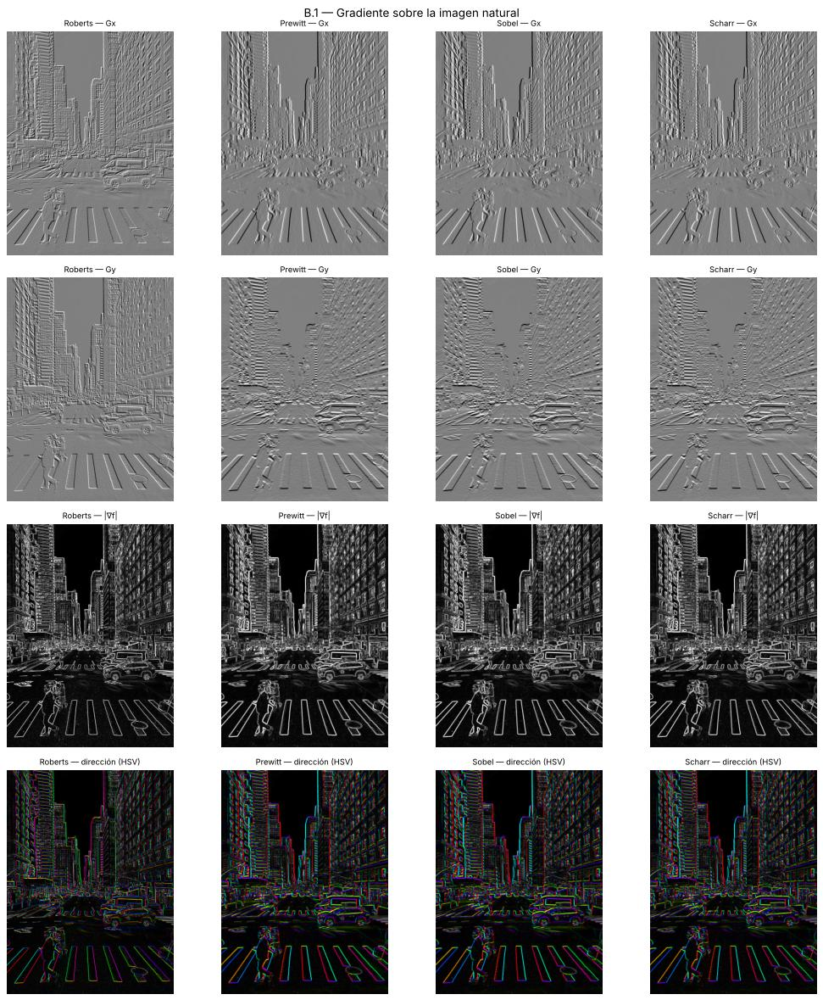

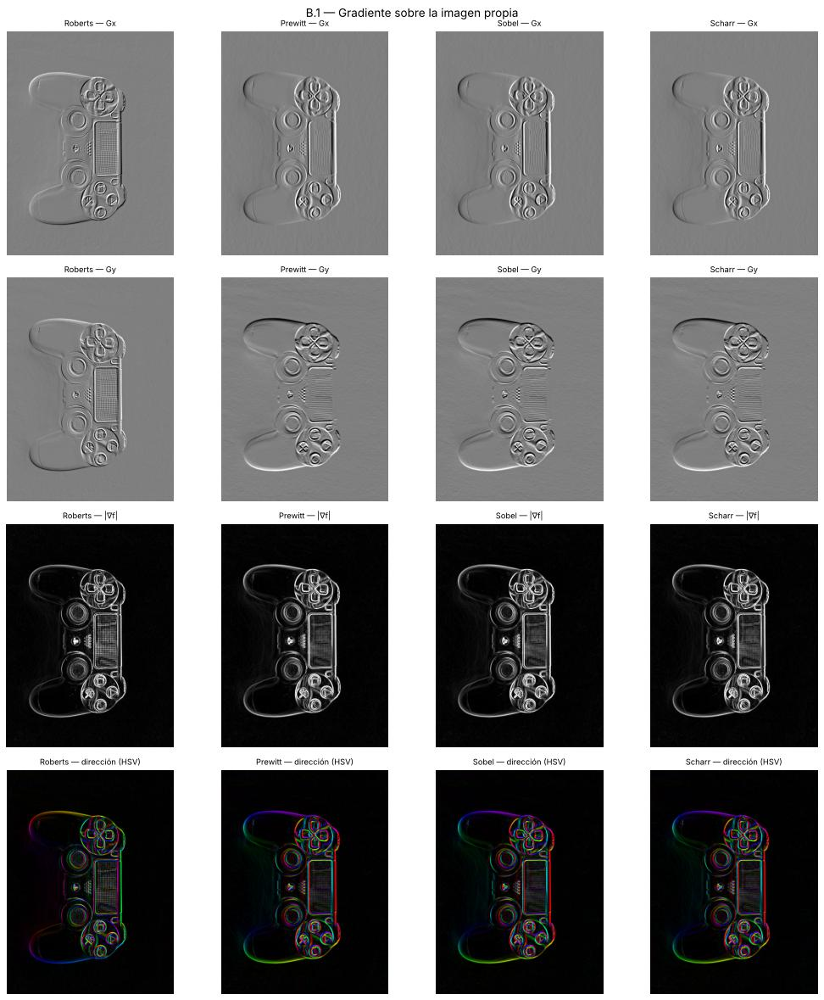

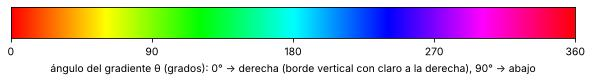

In [ ]:
operadores_B = ["Roberts", "Prewitt", "Sobel", "Scharr"]
gradientes_B = {(nom, op): gradiente_B(gris, op) for nom, gris in imagenes_B.items() for op in operadores_B}

for nom, gris in imagenes_B.items():
    fig, ejes = plt.subplots(4, 4, figsize=(14, 12 if gris.shape[0] <= gris.shape[1] else 16))
    for j, op in enumerate(operadores_B):
        gx, gy, mag, ang = gradientes_B[(nom, op)]
        mostrar_firmado_B(ejes[0, j], gx, f"{op} — Gx")
        mostrar_firmado_B(ejes[1, j], gy, f"{op} — Gy")
        mostrar_magnitud_B(ejes[2, j], mag, f"{op} — |∇f|")
        ejes[3, j].imshow(mapa_hsv_gradiente_B(mag, ang))
        ejes[3, j].set_title(f"{op} — dirección (HSV)", fontsize=9)
        ejes[3, j].axis("off")
    fig.suptitle(f"B.1 — Gradiente sobre la imagen {nom.lower()}", fontsize=13)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# Rueda de color: qué ángulo representa cada matiz
ang_rueda = np.linspace(0, 360, 256, endpoint=False)
rueda = mapa_hsv_gradiente_B(np.ones((1, 256)), ang_rueda[None, :], percentil=100)
fig, eje = plt.subplots(figsize=(8, 1.2))
eje.imshow(np.repeat(rueda, 20, axis=0), extent=[0, 360, 0, 1], aspect="auto")
eje.set_xticks([0, 90, 180, 270, 360]); eje.set_yticks([])
eje.set_xlabel("ángulo del gradiente θ (grados): 0° → derecha (borde vertical con claro a la derecha), 90° → abajo")
fig.tight_layout(); plt.show(); plt.close(fig)

**Por qué `cv2.CV_64F` y no `cv2.CV_8U`.** Una derivada tiene valores negativos (paso de claro a oscuro) y magnitudes que superan 255. Con `CV_8U` OpenCV *satura*: todo lo negativo pasa a 0 y todo lo mayor de 255 pasa a 255. Se pierde la mitad de los bordes (los de signo contrario) y la magnitud y el ángulo calculados después ya no son correctos. La celda siguiente lo cuantifica.

,imagen,% Gx negativo (se pierde en CV_8U),% |Gx| > 255 (se satura),Gx máx real,Gx mín real,% magnitud subestimada >10%,error medio de magnitud
0,Natural,47.12,5.79,756.0,-733.0,60.40,46.83
1,Propia,51.77,1.52,757.0,-903.0,66.49,14.85


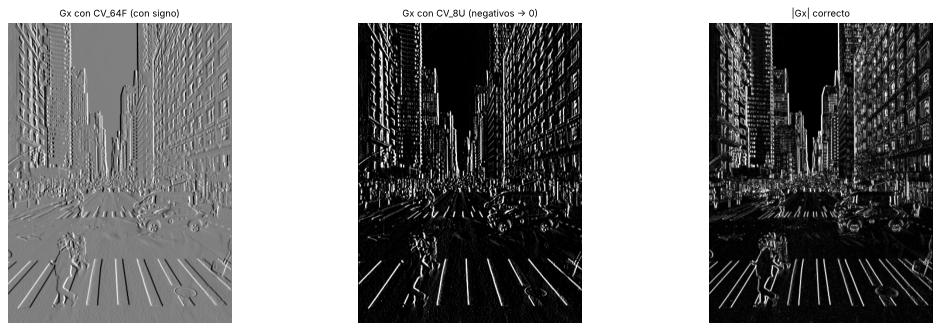

In [ ]:
filas_cv8u_B = []
for nom, gris in imagenes_B.items():
    gx64 = cv2.Sobel(gris.astype(np.float64), cv2.CV_64F, 1, 0, ksize=3, borderType=cv2.BORDER_REPLICATE)
    gx8 = cv2.Sobel(gris, cv2.CV_8U, 1, 0, ksize=3, borderType=cv2.BORDER_REPLICATE)
    gy64 = cv2.Sobel(gris.astype(np.float64), cv2.CV_64F, 0, 1, ksize=3, borderType=cv2.BORDER_REPLICATE)
    gy8 = cv2.Sobel(gris, cv2.CV_8U, 0, 1, ksize=3, borderType=cv2.BORDER_REPLICATE)
    mag64 = np.hypot(gx64, gy64)
    mag8 = np.hypot(gx8.astype(np.float64), gy8.astype(np.float64))
    filas_cv8u_B.append({
        "imagen": nom,
        "% Gx negativo (se pierde en CV_8U)": 100 * np.mean(gx64 < 0),
        "% |Gx| > 255 (se satura)": 100 * np.mean(np.abs(gx64) > 255),
        "Gx máx real": gx64.max(), "Gx mín real": gx64.min(),
        "% magnitud subestimada >10%": 100 * np.mean(mag8 < 0.9 * mag64),
        "error medio de magnitud": np.mean(np.abs(mag64 - mag8)),
    })
tabla_cv8u_B = pd.DataFrame(filas_cv8u_B).round(2)
display(tabla_cv8u_B)

gris = img_nat_B
gx64 = cv2.Sobel(gris.astype(np.float64), cv2.CV_64F, 1, 0, ksize=3)
gx8 = cv2.Sobel(gris, cv2.CV_8U, 1, 0, ksize=3)
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
mostrar_firmado_B(ejes[0], gx64, "Gx con CV_64F (con signo)")
ejes[1].imshow(gx8, cmap="gray", vmin=0, vmax=255); ejes[1].set_title("Gx con CV_8U (negativos → 0)", fontsize=9); ejes[1].axis("off")
mostrar_magnitud_B(ejes[2], np.abs(gx64), "|Gx| correcto")
fig.tight_layout(); plt.show(); plt.close(fig)

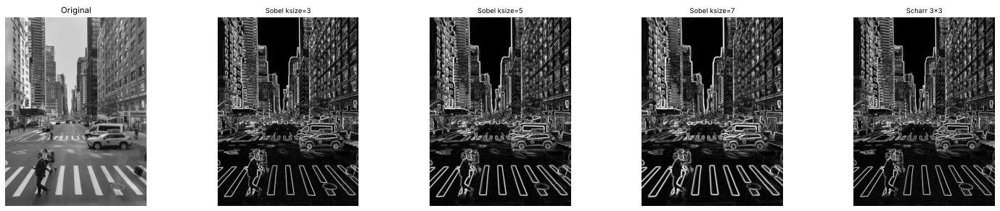

In [ ]:
# Sobel con ksize = 3, 5, 7 y comparación con Scharr: un kernel mayor suaviza más pero engruesa el borde
fig, ejes = plt.subplots(1, 5, figsize=(20, 4))
mostrar_imagen(img_nat_B, "Original", eje=ejes[0])
for eje, k in zip(ejes[1:4], (3, 5, 7)):
    _, _, mag, _ = gradiente_B(img_nat_B, "Sobel", ksize=k)
    mostrar_magnitud_B(eje, mag, f"Sobel ksize={k}")
_, _, mag_sch, _ = gradiente_B(img_nat_B, "Scharr")
mostrar_magnitud_B(ejes[4], mag_sch, "Scharr 3×3")
fig.tight_layout(); plt.show(); plt.close(fig)

### B.2 — Segunda derivada: Laplaciano, LoG y DoG
Laplaciano de 4 vecinos $\begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix}$ y de 8 vecinos $\begin{bmatrix}1&1&1\\1&-8&1\\1&1&1\end{bmatrix}$, aplicados directamente y después de un suavizado Gaussiano (LoG, σ = 2). La DoG usa σ₁ = 2 y σ₂ = 1.6·σ₁ = 3.2. La fila inferior repite todo sobre la imagen con ruido gaussiano σ = 10 para ver cómo reacciona cada operador al ruido.

Error máximo kernel 4-vecinos vs cv2.Laplacian(ksize=1): 0.00e+00


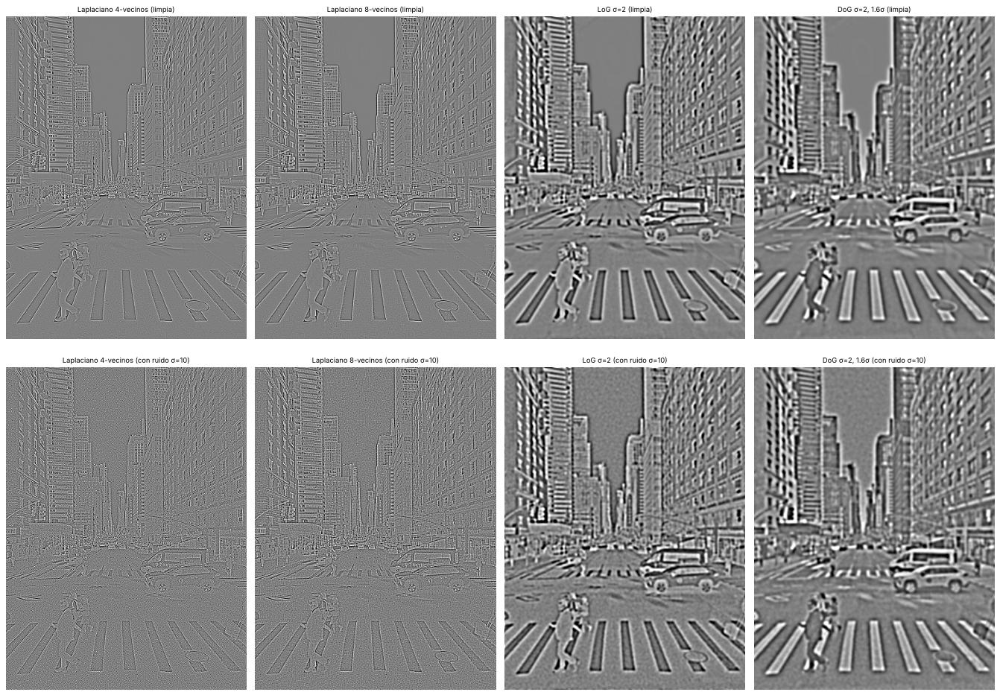

In [ ]:
k_lap4_B = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float64)
k_lap8_B = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], np.float64)
SIGMA_LOG_B = 2.0
RAZON_DOG_B = 1.6


def laplaciano_B(gris, kernel):
    return cv2.filter2D(gris.astype(np.float64), cv2.CV_64F, kernel, borderType=cv2.BORDER_REPLICATE)


def log_B(gris, sigma=SIGMA_LOG_B, kernel=k_lap4_B):
    suave = cv2.GaussianBlur(gris.astype(np.float64), (0, 0), sigma, borderType=cv2.BORDER_REPLICATE)
    return cv2.filter2D(suave, cv2.CV_64F, kernel, borderType=cv2.BORDER_REPLICATE)


def dog_B(gris, sigma=SIGMA_LOG_B, razon=RAZON_DOG_B):
    f = gris.astype(np.float64)
    g1 = cv2.GaussianBlur(f, (0, 0), sigma, borderType=cv2.BORDER_REPLICATE)
    g2 = cv2.GaussianBlur(f, (0, 0), razon * sigma, borderType=cv2.BORDER_REPLICATE)
    return g1 - g2


# Verificación: el kernel de 4 vecinos coincide con cv2.Laplacian(ksize=1)
err_lap_cv2_B = np.abs(laplaciano_B(img_nat_B, k_lap4_B) - cv2.Laplacian(img_nat_B.astype(np.float64), cv2.CV_64F, ksize=1, borderType=cv2.BORDER_REPLICATE)).max()
print(f"Error máximo kernel 4-vecinos vs cv2.Laplacian(ksize=1): {err_lap_cv2_B:.2e}")

rng_B = np.random.default_rng(SEED)
img_nat_ruido_B = agregar_ruido_gaussiano(img_nat_B, 10, rng_B)

fig, ejes = plt.subplots(2, 4, figsize=(18, 9 if img_nat_B.shape[0] <= img_nat_B.shape[1] else 13))
for fila, (etiqueta, gris) in enumerate((("limpia", img_nat_B), ("con ruido σ=10", img_nat_ruido_B))):
    mostrar_firmado_B(ejes[fila, 0], laplaciano_B(gris, k_lap4_B), f"Laplaciano 4-vecinos ({etiqueta})")
    mostrar_firmado_B(ejes[fila, 1], laplaciano_B(gris, k_lap8_B), f"Laplaciano 8-vecinos ({etiqueta})")
    mostrar_firmado_B(ejes[fila, 2], log_B(gris), f"LoG σ={SIGMA_LOG_B:g} ({etiqueta})")
    mostrar_firmado_B(ejes[fila, 3], dog_B(gris), f"DoG σ={SIGMA_LOG_B:g}, {RAZON_DOG_B}σ ({etiqueta})")
fig.tight_layout(); plt.show(); plt.close(fig)

In [ ]:
# DoG ≈ −(k−1)·σ²·LoG: se verifica con una regresión lineal y la correlación entre ambos mapas
log_map = log_B(img_nat_B)
dog_map = dog_B(img_nat_B)
pendiente_B = float(np.dot(log_map.ravel(), dog_map.ravel()) / np.dot(log_map.ravel(), log_map.ravel()))
teorica_B = -(RAZON_DOG_B - 1) * SIGMA_LOG_B ** 2
correlacion_log_dog_B = float(np.corrcoef(log_map.ravel(), dog_map.ravel())[0, 1])
print(f"pendiente DoG/LoG medida = {pendiente_B:.3f}   teórica −(k−1)σ² = {teorica_B:.3f}   correlación = {correlacion_log_dog_B:.4f}")

# Sensibilidad al ruido: relación entre la desviación estándar de la respuesta limpia y la del error que introduce el ruido
def snr_respuesta_B(funcion, limpia, ruidosa):
    r0, r1 = funcion(limpia), funcion(ruidosa)
    return float(np.std(r0) / np.std(r1 - r0))

funciones_snr_B = {
    "Intensidad (sin derivar)": lambda x: x.astype(np.float64),
    "Sobel Gx": lambda x: gradiente_B(x, "Sobel")[0],
    "|∇f| Sobel": lambda x: gradiente_B(x, "Sobel")[2],
    "Laplaciano 4-vecinos": lambda x: laplaciano_B(x, k_lap4_B),
    "Laplaciano 8-vecinos": lambda x: laplaciano_B(x, k_lap8_B),
    "LoG σ=2": lambda x: log_B(x),
    "DoG σ=2 / 3.2": lambda x: dog_B(x),
}
tabla_snr_B = pd.DataFrame(
    [{"operador": nombre, "SNR de la respuesta (σ_ruido=10)": snr_respuesta_B(fn, img_nat_B, img_nat_ruido_B)}
     for nombre, fn in funciones_snr_B.items()]).round(2)
display(tabla_snr_B)

pendiente DoG/LoG medida = -1.888   teórica −(k−1)σ² = -2.400   correlación = -0.9566


,operador,SNR de la respuesta (σ_ruido=10)
0,Intensidad (sin derivar),5.06
1,Sobel Gx,3.21
2,|∇f| Sobel,3.45
3,Laplaciano 4-vecinos,1.02
4,Laplaciano 8-vecinos,1.35
5,LoG σ=2,6.84
6,DoG σ=2 / 3.2,8.98


### B.3 — Canny paso a paso
Matriz de resultados: filas = σ del suavizado Gaussiano previo (1, 2, 3); columnas = pares de umbrales de histéresis (20/60, 50/150, 100/200). El suavizado se aplica explícitamente con `GaussianBlur` antes de `cv2.Canny`, para controlar σ. Después se propone una regla automática basada en la mediana: $T_{bajo}=\max(0,(1-s)\,m)$ y $T_{alto}=\min(255,(1+s)\,m)$, con $m$ la mediana de la imagen suavizada y $s=0.33$.

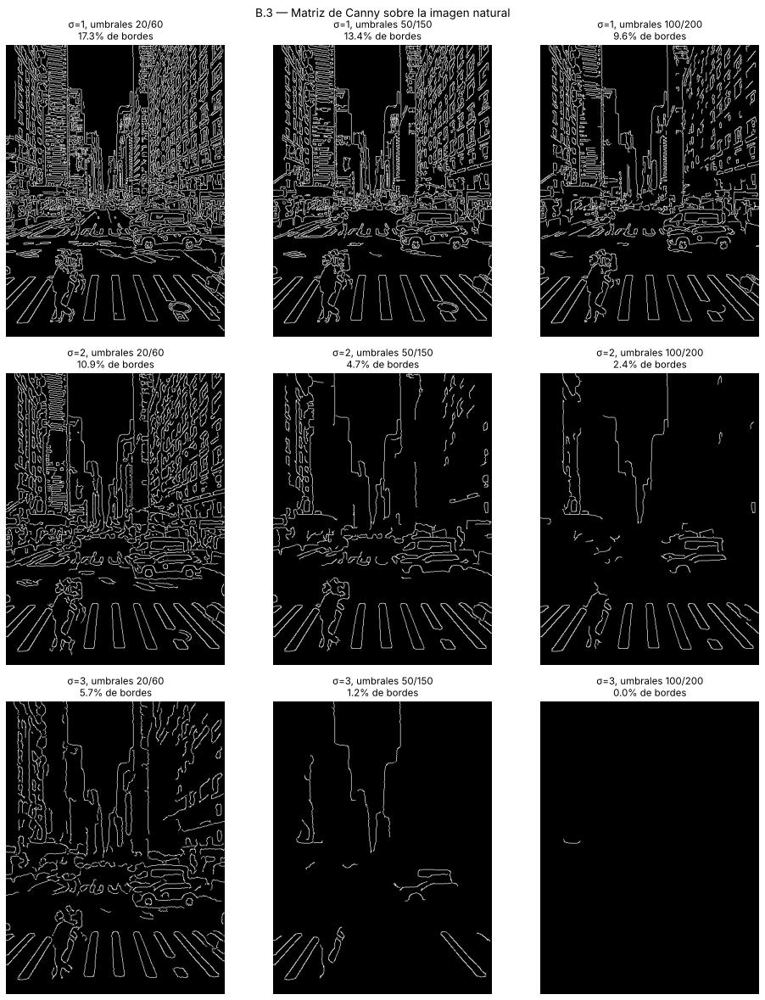

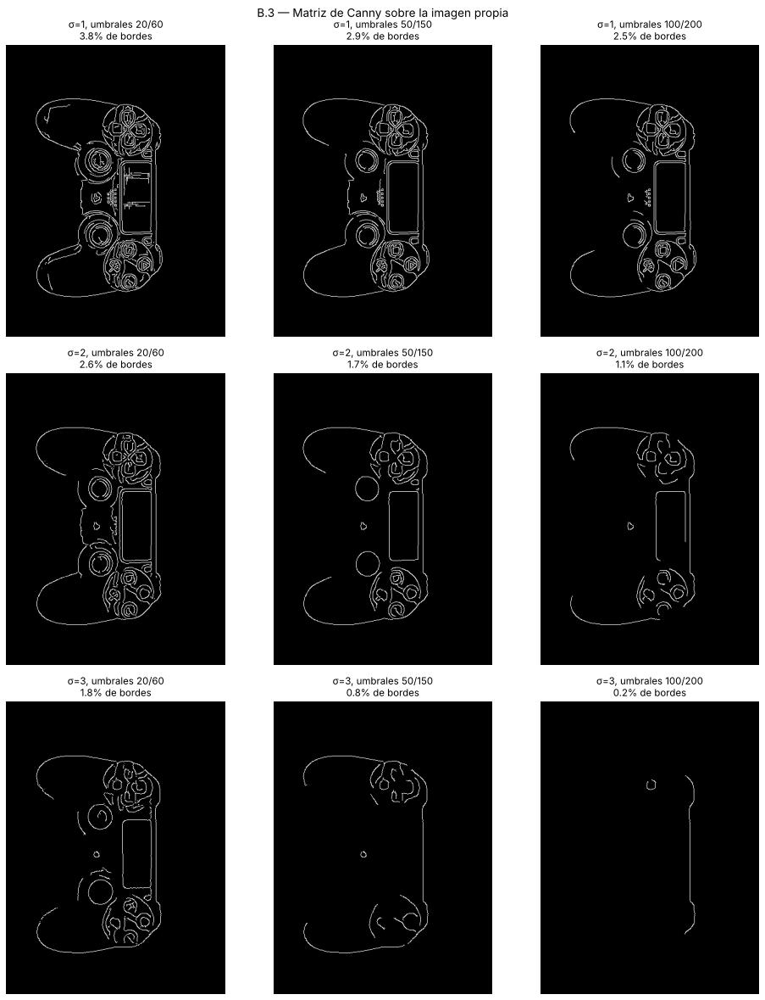

umbrales   100/200  20/60  50/150
imagen  σ                        
Natural 1     9.65  17.27   13.42
        2     2.36  10.88    4.67
        3     0.02   5.70    1.23
Propia  1     2.46   3.82    2.94
        2     1.15   2.61    1.74
        3     0.18   1.77    0.81

In [ ]:
def canny_B(gris, sigma, bajo, alto):
    suave = cv2.GaussianBlur(gris, (0, 0), sigma)
    return cv2.Canny(suave, bajo, alto)


def umbrales_auto_B(gris, sigma, s=0.33):
    mediana = float(np.median(cv2.GaussianBlur(gris, (0, 0), sigma)))
    return int(max(0, (1 - s) * mediana)), int(min(255, (1 + s) * mediana))


sigmas_canny_B = (1, 2, 3)
pares_canny_B = ((20, 60), (50, 150), (100, 200))

filas_canny_B = []
for nom, gris in imagenes_B.items():
    fig, ejes = plt.subplots(3, 3, figsize=(13, 10 if gris.shape[0] <= gris.shape[1] else 16))
    for i, sg in enumerate(sigmas_canny_B):
        for j, (lo, hi) in enumerate(pares_canny_B):
            borde = canny_B(gris, sg, lo, hi)
            mostrar_imagen(borde, f"σ={sg}, umbrales {lo}/{hi}\n{100 * np.mean(borde > 0):.1f}% de bordes", eje=ejes[i, j])
            filas_canny_B.append({"imagen": nom, "σ": sg, "umbrales": f"{lo}/{hi}", "% píxeles borde": 100 * np.mean(borde > 0)})
    fig.suptitle(f"B.3 — Matriz de Canny sobre la imagen {nom.lower()}", fontsize=13)
    fig.tight_layout(); plt.show(); plt.close(fig)
tabla_canny_B = pd.DataFrame(filas_canny_B).round(2)
display(tabla_canny_B.pivot_table(index=["imagen", "σ"], columns="umbrales", values="% píxeles borde"))

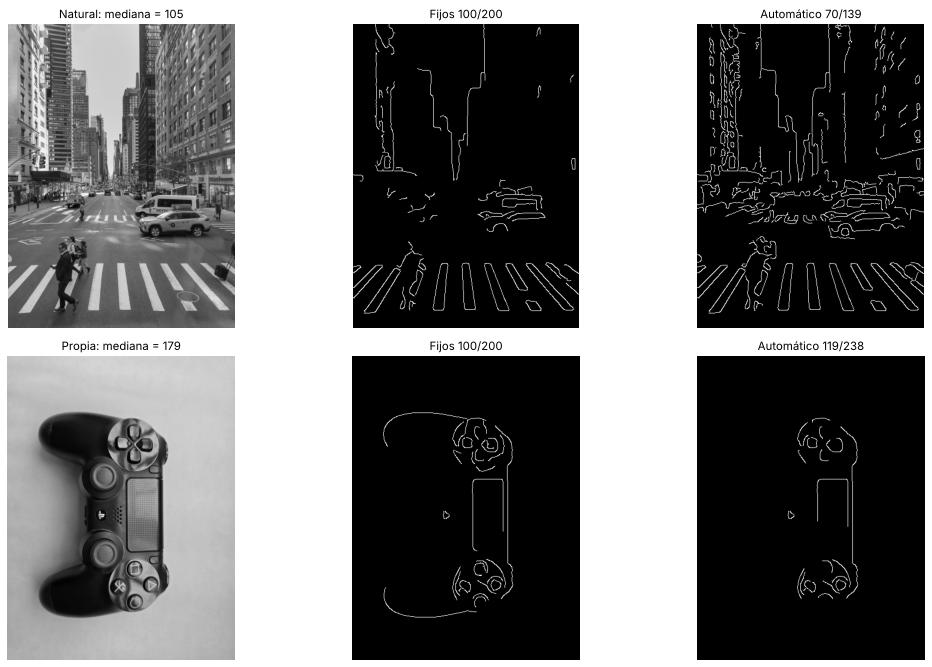

,imagen,mediana,umbral bajo,umbral alto,% bordes fijos 100/200,% bordes automático
0,Natural,103.0,70,139,2.36,4.88
1,Propia,181.0,119,238,1.15,0.72


In [ ]:
# Regla automática (mediana) frente a umbrales fijos, con σ = 2
fig, ejes = plt.subplots(2, 3, figsize=(15, 9))
filas_auto_B = []
for fila, (nom, gris) in enumerate(imagenes_B.items()):
    lo, hi = umbrales_auto_B(gris, 2)
    mostrar_imagen(gris, f"{nom}: mediana = {np.median(cv2.GaussianBlur(gris, (0, 0), 2)):.0f}", eje=ejes[fila, 0])
    mostrar_imagen(canny_B(gris, 2, 100, 200), "Fijos 100/200", eje=ejes[fila, 1])
    borde_auto = canny_B(gris, 2, lo, hi)
    mostrar_imagen(borde_auto, f"Automático {lo}/{hi}", eje=ejes[fila, 2])
    filas_auto_B.append({"imagen": nom, "mediana": float(np.median(gris)), "umbral bajo": lo, "umbral alto": hi,
                         "% bordes fijos 100/200": 100 * np.mean(canny_B(gris, 2, 100, 200) > 0),
                         "% bordes automático": 100 * np.mean(borde_auto > 0)})
fig.tight_layout(); plt.show(); plt.close(fig)
display(pd.DataFrame(filas_auto_B).round(2))

### B.4 — Realce de nitidez: unsharp masking y high-boost
$g = f + k\,(f - f_{suav})$ con $f_{suav}$ Gaussiano de σ = 2. Con $k = 1$ es *unsharp masking*; con $k > 1$, *high-boost*. Equivale a `cv2.addWeighted(f, 1+k, f_suav, -k, 0)`, que se usa como comprobación. El perfil de intensidad a través de un borde fuerte muestra los halos (sobreimpulso y subimpulso).

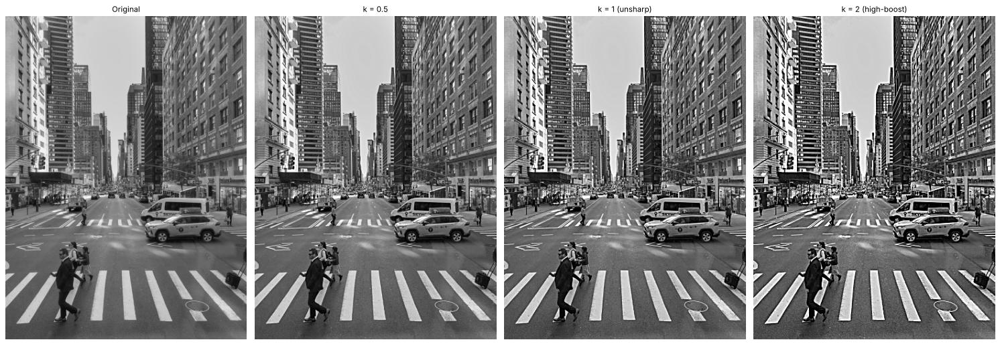

,k,% píxeles saturados (<0 o >255),mínimo sin recortar,máximo sin recortar,SSIM vs original
0,0.5,0.679,-19.241,300.682,0.954
1,1.0,2.967,-54.483,357.962,0.873
2,2.0,9.801,-143.997,480.924,0.729


In [ ]:
SIGMA_UNSHARP_B = 2.0
valores_k_B = (0.5, 1, 2)


def unsharp_B(gris, sigma=SIGMA_UNSHARP_B, k=1.0):
    """Devuelve g sin recortar (float64), para poder medir el sobreimpulso antes de saturar."""
    f = gris.astype(np.float64)
    suave = cv2.GaussianBlur(f, (0, 0), sigma, borderType=cv2.BORDER_REPLICATE)
    return f + k * (f - suave)


# Comprobación frente a cv2.addWeighted
f64 = img_nat_B.astype(np.float64)
suave64 = cv2.GaussianBlur(f64, (0, 0), SIGMA_UNSHARP_B, borderType=cv2.BORDER_REPLICATE)
for k in valores_k_B:
    assert np.abs(unsharp_B(img_nat_B, k=k) - cv2.addWeighted(f64, 1 + k, suave64, -k, 0)).max() < 1e-9

fig, ejes = plt.subplots(1, 4, figsize=(20, 5 if img_nat_B.shape[0] <= img_nat_B.shape[1] else 7))
mostrar_imagen(img_nat_B, "Original", eje=ejes[0])
filas_unsharp_B = []
for eje, k in zip(ejes[1:], valores_k_B):
    g = unsharp_B(img_nat_B, k=k)
    mostrar_imagen(np.clip(g, 0, 255).astype(np.uint8), f"k = {k:g}" + (" (unsharp)" if k == 1 else " (high-boost)" if k > 1 else ""), eje=eje)
    filas_unsharp_B.append({"k": k, "% píxeles saturados (<0 o >255)": 100 * np.mean((g < 0) | (g > 255)),
                            "mínimo sin recortar": g.min(), "máximo sin recortar": g.max(),
                            "SSIM vs original": calcular_metricas(img_nat_B, np.clip(g, 0, 255).astype(np.uint8))["SSIM"]})
fig.tight_layout(); plt.show(); plt.close(fig)
display(pd.DataFrame(filas_unsharp_B).round(3))

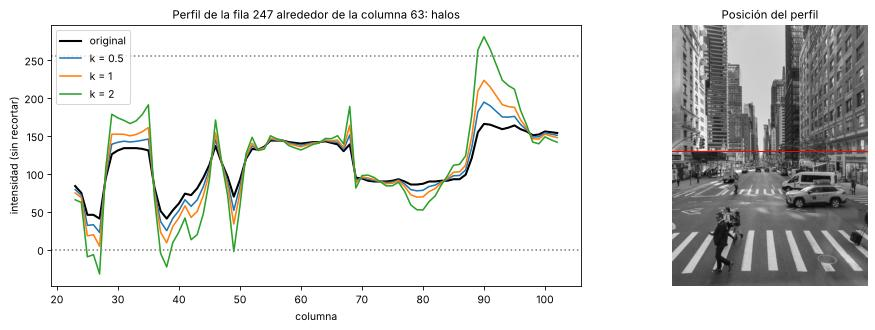

,k,sobreimpulso máx (niveles),subimpulso máx (niveles)
0,0.5,28.75,-18.25
1,1.0,57.50,-36.50
2,2.0,115.00,-73.00


In [ ]:
# Perfil horizontal a través del borde de mayor gradiente (con σ=2 para no elegir ruido)
_, _, mag_ref_B, _ = gradiente_B(cv2.GaussianBlur(img_nat_B, (0, 0), 2), "Sobel")
margen = 40
mag_interior = mag_ref_B.copy()
mag_interior[:, :margen] = 0; mag_interior[:, -margen:] = 0
fila_p, col_p = np.unravel_index(np.argmax(mag_interior), mag_interior.shape)
cols = np.arange(col_p - margen, col_p + margen)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].plot(cols, img_nat_B[fila_p, cols], "k-", lw=2, label="original")
for k in valores_k_B:
    ejes[0].plot(cols, unsharp_B(img_nat_B, k=k)[fila_p, cols], label=f"k = {k:g}")
ejes[0].axhline(0, color="gray", ls=":"); ejes[0].axhline(255, color="gray", ls=":")
ejes[0].set_title(f"Perfil de la fila {fila_p} alrededor de la columna {col_p}: halos"); ejes[0].set_xlabel("columna"); ejes[0].set_ylabel("intensidad (sin recortar)")
ejes[0].legend()
mostrar_imagen(img_nat_B, "Posición del perfil", eje=ejes[1])
ejes[1].axhline(fila_p, color="red", lw=1)
fig.tight_layout(); plt.show(); plt.close(fig)

perfil_orig = img_nat_B[fila_p, cols].astype(np.float64)
filas_halo_B = []
for k in valores_k_B:
    p = unsharp_B(img_nat_B, k=k)[fila_p, cols]
    filas_halo_B.append({"k": k, "sobreimpulso máx (niveles)": float((p - perfil_orig).max()),
                         "subimpulso máx (niveles)": float((p - perfil_orig).min())})
display(pd.DataFrame(filas_halo_B).round(2))

### Pregunta 1.4 — Ruido y derivadas
Derivar es restar vecinos. El ruido es una variación de alta frecuencia, independiente de un píxel al siguiente, así que al restar dos vecinos el ruido no se cancela sino que se suma en varianza, mientras que la señal (que cambia lentamente) sí se cancela en las zonas suaves. En frecuencia, la primera derivada multiplica el espectro por $|\omega|$ y la segunda por $|\omega|^2$: amplifican justo la banda donde vive el ruido.

El Laplaciano es más sensible que Sobel por dos razones. Primera, es una derivada de segundo orden (ganancia $|\omega|^2$). Segunda, tiene menos suavizado interno: Sobel promedia con pesos (1, 2, 1) en la dirección perpendicular, el Laplaciano no. Para ruido independiente de desviación σ, la desviación en la salida es σ·√(Σh²): Sobel $G_x$ → √12 ≈ 3.5σ, Laplaciano de 4 vecinos → √20 ≈ 4.5σ, de 8 vecinos → √72 ≈ 8.5σ.

La tabla de B.2 lo confirma con ruido gaussiano σ = 10: la relación señal/error de la respuesta cae de 5.1 (la intensidad sin derivar) a 3.2 con Sobel y a 1.0 con el Laplaciano de 4 vecinos. El **LoG** lo resuelve porque primero aplica un Gaussiano, que atenúa exponencialmente las altas frecuencias, y solo después deriva: con σ = 2 la relación sube a 6.8 (y a 9.0 con la DoG equivalente). El precio es que los bordes salen más gruesos y se pierde detalle fino.

### Pregunta 1.5 — Histéresis en Canny
Con un solo umbral hay un compromiso sin salida: si es alto, los contornos reales cuyo gradiente baja por tramos quedan *cortados*; si es bajo, aparecen bordes falsos de ruido. Canny usa dos umbrales:

- **Supresión de no-máximos.** Antes de umbralizar, conserva solo los píxeles que son máximo local de la magnitud *a lo largo de la dirección del gradiente*. Así los bordes anchos del gradiente se adelgazan a 1 píxel y el umbral solo decide entre candidatos ya delgados.
- **Histéresis.** Los píxeles con magnitud > $T_{alto}$ son bordes seguros; los que están entre $T_{bajo}$ y $T_{alto}$ se conservan **solo si están conectados** (8-vecindad) a un borde seguro; los que están bajo $T_{bajo}$ se descartan. Un contorno continuo cuyo gradiente oscila alrededor del umbral se conserva completo, y el ruido aislado de intensidad intermedia desaparece. Se suele usar $T_{alto}/T_{bajo}$ entre 2 y 3.

Lo observado en B.3: sobre la imagen natural con σ = 1 los umbrales 20/60 marcan el 17.3 % de los píxeles y 100/200 el 9.7 %; con σ = 3 y 100/200 casi no queda nada (0.02 %). Es decir, los umbrales fijos dependen de σ y del contraste de la imagen. La regla automática por la mediana ($T_{bajo}=0.67\,m$, $T_{alto}=1.33\,m$) da 70/139 en la imagen natural (4.9 % de bordes) y 119/238 en la propia, cuyo fondo es muy claro (mediana 181), con solo 0.7 %. Es un buen punto de partida, pero en imágenes con fondo muy claro u oscuro conviene afinar el factor $s$.

### Conclusión del Módulo B
- Para el gradiente, `cv2.CV_64F` es obligatorio: con `CV_8U` se pierde el ≈47 % de las respuestas $G_x$ (las negativas) y se subestima más de un 10 % la magnitud en ≈60 % de los píxeles de la imagen natural.
- Sobel y Scharr dan mapas casi idénticos a simple vista; Prewitt, que no pondera el centro, da bordes ligeramente más ruidosos. Roberts (2×2 diagonal) usa muy pocos píxeles y su ángulo queda rotado 45° respecto a los demás operadores. Para el HOG de la Parte 2 sirve Sobel o Scharr con suavizado previo.
- DoG ≈ −(k−1)σ²·LoG: la pendiente medida entre ambos mapas fue −1.89 frente a −2.40 teórico, con correlación de −0.96 en valor con signo (|r| = 0.96). La DoG es una aproximación barata del LoG.
- En el realce, $k=1$ ya produce halos de ≈57 niveles de sobreimpulso en el borde más fuerte y satura el 3 % de los píxeles; con $k=2$ son 115 niveles y el 9.8 %. Para preparar imágenes para clasificación, $k \leq 1$.

## Módulo C — Transformaciones de intensidad
Transformaciones puntuales $s=T(r)$ con $r\in[0,255]$, implementadas como tablas de búsqueda (`cv2.LUT`): negativo $s=255-r$, logarítmica $s=c\log(1+r)$ con $c=255/\log 256$ y gamma $s=255\,(r/255)^\gamma$, con $\gamma\in\{0.3,0.5,1.5,2.5\}$.

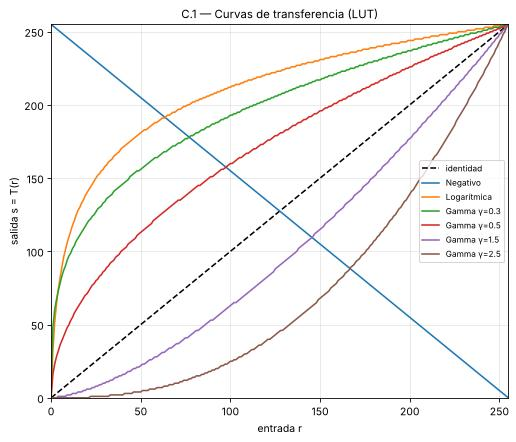

In [ ]:
r_C = np.arange(256, dtype=np.float64)
c_log_C = 255 / np.log(256)
gammas_C = (0.3, 0.5, 1.5, 2.5)

funciones_T_C = {"Negativo": lambda r: 255 - r, "Logarítmica": lambda r: c_log_C * np.log1p(r)}
for g in gammas_C:
    funciones_T_C[f"Gamma γ={g:g}"] = (lambda r, g=g: 255 * (r / 255) ** g)

luts_C = {nombre: np.clip(np.rint(fn(r_C)), 0, 255).astype(np.uint8) for nombre, fn in funciones_T_C.items()}

# La LUT debe coincidir con la fórmula aplicada directamente píxel a píxel
for nombre, fn in funciones_T_C.items():
    directo = np.clip(np.rint(fn(img_nat_B.astype(np.float64))), 0, 255).astype(np.uint8)
    assert np.array_equal(cv2.LUT(img_nat_B, luts_C[nombre]), directo), nombre

fig, eje = plt.subplots(figsize=(7, 6))
eje.plot(r_C, r_C, "k--", label="identidad")
for nombre, lut in luts_C.items():
    eje.plot(r_C, lut, label=nombre)
eje.set_xlabel("entrada r"); eje.set_ylabel("salida s = T(r)"); eje.set_title("C.1 — Curvas de transferencia (LUT)")
eje.set_xlim(0, 255); eje.set_ylim(0, 255); eje.grid(alpha=0.3); eje.legend(fontsize=8)
fig.tight_layout(); plt.show(); plt.close(fig)

### C.1 — Imagen subexpuesta y sobreexpuesta
Para controlar el experimento se parte de la imagen natural y se simulan dos exposiciones: **subexpuesta** $s=0.3\,r$ (todo comprimido hacia negro) y **sobreexpuesta** $s=255-0.3\,(255-r)$ (comprimido hacia blanco). Cada transformación se aplica con `cv2.LUT`. La entropía del histograma y la desviación estándar miden cuánta información de contraste queda disponible.

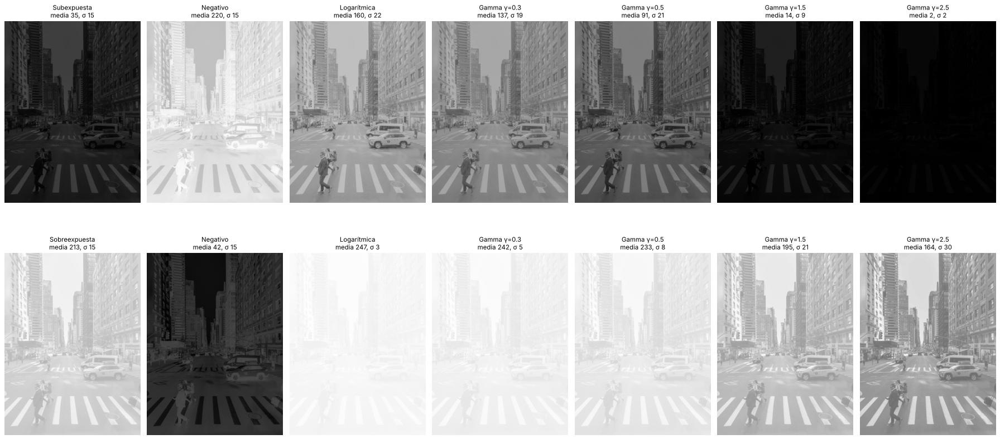

,exposición,transformación,media,desv. estándar,entropía (bits)
0,Subexpuesta,Sin corregir,34.56,15.22,5.66
1,Subexpuesta,Negativo,220.44,15.22,5.66
2,Subexpuesta,Logarítmica,159.55,21.99,5.56
3,Subexpuesta,Gamma γ=0.3,136.96,19.42,5.60
4,Subexpuesta,Gamma γ=0.5,91.45,21.08,5.65
5,Subexpuesta,Gamma γ=1.5,13.62,8.86,4.68
6,Subexpuesta,Gamma γ=2.5,2.34,2.46,2.67
7,Sobreexpuesta,Sin corregir,213.06,15.22,5.68
8,Sobreexpuesta,Negativo,41.94,15.22,5.68
9,Sobreexpuesta,Logarítmica,246.64,3.20,3.54


,exposición,transformación,media,desv. estándar,entropía (bits)
13,Sobreexpuesta,Gamma γ=2.5,164.25,29.99,5.68
2,Subexpuesta,Logarítmica,159.55,21.99,5.56


In [ ]:
def entropia_C(gris):
    p = np.bincount(gris.ravel(), minlength=256) / gris.size
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


sub_C = np.rint(0.3 * img_nat_B.astype(np.float64)).astype(np.uint8)
sobre_C = np.rint(255 - 0.3 * (255 - img_nat_B.astype(np.float64))).astype(np.uint8)
exposiciones_C = {"Subexpuesta": sub_C, "Sobreexpuesta": sobre_C}

filas_C = []
fig, ejes = plt.subplots(2, 7, figsize=(24, 8 if img_nat_B.shape[0] <= img_nat_B.shape[1] else 12))
for i, (nom_exp, base) in enumerate(exposiciones_C.items()):
    mostrar_imagen(base, f"{nom_exp}\nmedia {base.mean():.0f}, σ {base.std():.0f}", eje=ejes[i, 0])
    filas_C.append({"exposición": nom_exp, "transformación": "Sin corregir", "media": base.mean(), "desv. estándar": base.std(), "entropía (bits)": entropia_C(base)})
    for j, (nom_t, lut) in enumerate(luts_C.items(), start=1):
        res = cv2.LUT(base, lut)
        mostrar_imagen(res, f"{nom_t}\nmedia {res.mean():.0f}, σ {res.std():.0f}", eje=ejes[i, j])
        filas_C.append({"exposición": nom_exp, "transformación": nom_t, "media": res.mean(), "desv. estándar": res.std(), "entropía (bits)": entropia_C(res)})
fig.tight_layout(); plt.show(); plt.close(fig)

tabla_C = pd.DataFrame(filas_C).round(2)
display(tabla_C)
mejores_C = tabla_C[tabla_C.transformación != "Sin corregir"].sort_values("desv. estándar", ascending=False).groupby("exposición").head(1)
display(mejores_C)

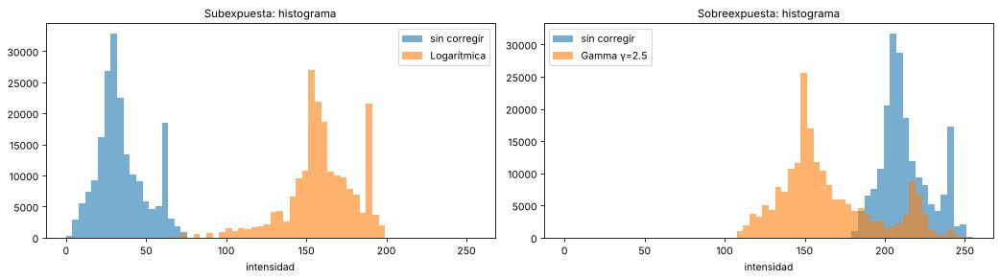

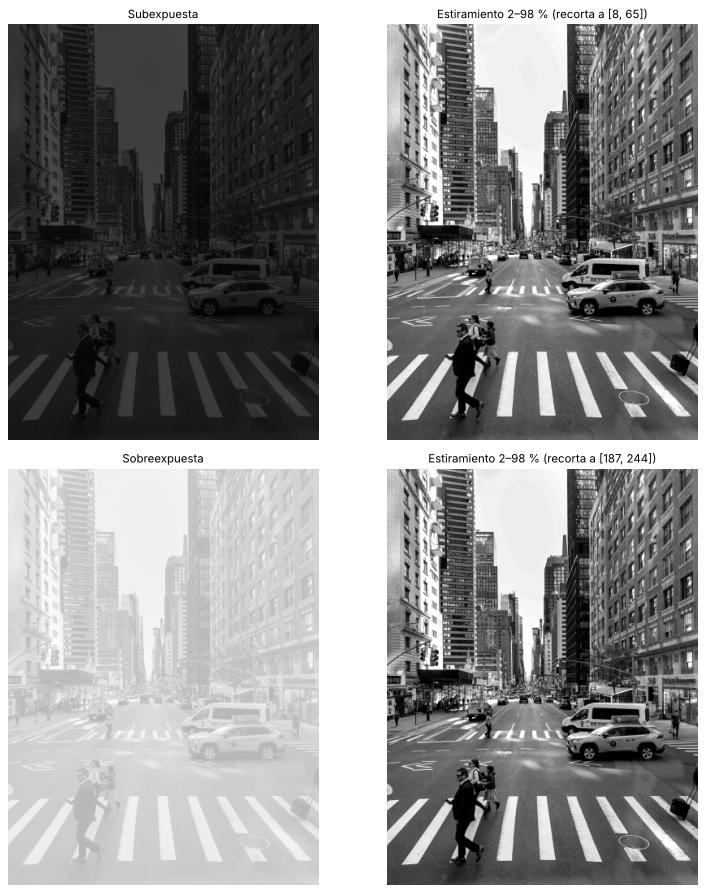

,exposición,desv. estándar antes,desv. estándar después,entropía antes,entropía después
0,Subexpuesta,15.22,66.95,5.66,5.53
1,Sobreexpuesta,15.22,66.97,5.68,5.55


In [ ]:
# Histogramas: imagen sin corregir frente a la mejor transformación de cada exposición
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for eje, (nom_exp, base) in zip(ejes, exposiciones_C.items()):
    mejor_nombre = mejores_C[mejores_C.exposición == nom_exp].iloc[0]["transformación"]
    eje.hist(base.ravel(), bins=64, range=(0, 255), alpha=0.6, label="sin corregir")
    eje.hist(cv2.LUT(base, luts_C[mejor_nombre]).ravel(), bins=64, range=(0, 255), alpha=0.6, label=mejor_nombre)
    eje.set_title(f"{nom_exp}: histograma"); eje.set_xlabel("intensidad"); eje.legend()
fig.tight_layout(); plt.show(); plt.close(fig)

# Estiramiento de contraste por percentiles 2–98 (catálogo): cv2.normalize tras recortar
def estiramiento_C(gris, p_bajo=2, p_alto=98):
    lo, hi = np.percentile(gris, [p_bajo, p_alto])
    recortada = np.clip(gris, lo, hi).astype(np.float32)
    return cv2.normalize(recortada, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8), lo, hi

fig, ejes = plt.subplots(2, 2, figsize=(11, 8 if img_nat_B.shape[0] <= img_nat_B.shape[1] else 12))
filas_estir_C = []
for i, (nom_exp, base) in enumerate(exposiciones_C.items()):
    est, lo, hi = estiramiento_C(base)
    mostrar_imagen(base, f"{nom_exp}", eje=ejes[i, 0])
    mostrar_imagen(est, f"Estiramiento 2–98 % (recorta a [{lo:.0f}, {hi:.0f}])", eje=ejes[i, 1])
    filas_estir_C.append({"exposición": nom_exp, "desv. estándar antes": base.std(), "desv. estándar después": est.std(),
                          "entropía antes": entropia_C(base), "entropía después": entropia_C(est)})
fig.tight_layout(); plt.show(); plt.close(fig)
display(pd.DataFrame(filas_estir_C).round(2))

### C.2 — Visualización del espectro: lineal frente a logarítmica
La magnitud de la FFT de una imagen natural concentra casi toda su energía en el componente DC y en las frecuencias más bajas, así que mostrada sin escalar solo se ve un punto brillante. La transformación logarítmica $\log(1+|F|)$ comprime ese rango y deja ver la estructura del espectro. Esta será la forma estándar de mostrarlo en el Módulo D.

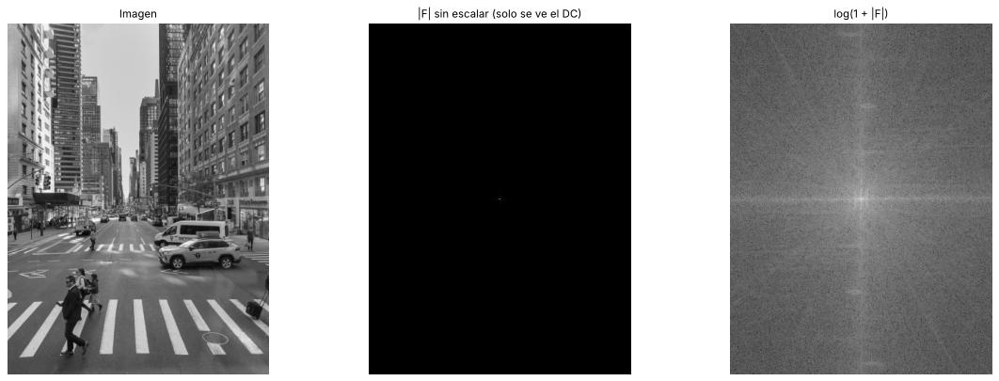

,|F| máx / mediana,rango dinámico (dB),% píxeles ≥ 1 % del máx en escala lineal,% píxeles ≥ 1 % del máx en escala log
0,5439.91,126.17,0.1,100.0


In [ ]:
F_C = np.fft.fftshift(np.fft.fft2(img_nat_B.astype(np.float64)))
mag_C = np.abs(F_C)
lineal_C = normalizar_visualizacion(mag_C)
log_C = normalizar_visualizacion(np.log1p(mag_C))

fig, ejes = plt.subplots(1, 3, figsize=(16, 5.5))
mostrar_imagen(img_nat_B, "Imagen", eje=ejes[0])
ejes[1].imshow(lineal_C, cmap="gray"); ejes[1].set_title("|F| sin escalar (solo se ve el DC)"); ejes[1].axis("off")
ejes[2].imshow(log_C, cmap="gray"); ejes[2].set_title("log(1 + |F|)"); ejes[2].axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)

resumen_espectro_C = pd.DataFrame([{
    "|F| máx / mediana": mag_C.max() / np.median(mag_C),
    "rango dinámico (dB)": 20 * np.log10(mag_C.max() / mag_C[mag_C > 0].min()),
    "% píxeles ≥ 1 % del máx en escala lineal": 100 * np.mean(lineal_C >= 0.01),
    "% píxeles ≥ 1 % del máx en escala log": 100 * np.mean(log_C >= 0.01),
}]).round(2)
display(resumen_espectro_C)

### Pregunta 1.6 — Rango dinámico
La magnitud de la FFT de una imagen natural abarca un rango enorme: el DC y las frecuencias más bajas son miles de veces mayores que las altas. En la imagen natural, $|F|_{máx}$ es ≈5 400 veces la mediana (≈126 dB entre el máximo y el mínimo). Una pantalla de 8 bits no puede mostrar esa escala de forma lineal: solo el 0.1 % de los píxeles del espectro supera el 1 % del máximo, y se ve un punto blanco sobre fondo negro. $\log(1+|F|)$ comprime ese rango, de modo que el 100 % de los coeficientes queda en un nivel visible y se aprecian las direcciones y la distribución de energía.

Se benefician de la misma transformación las imágenes con rango dinámico muy grande en las que importan tanto los valores bajos como los altos: astronómicas (estrellas brillantes junto a nebulosas tenues), radiografías y tomografías con zonas muy densas y muy tenues, imágenes de radar/SAR y espectrogramas. La log expande los valores oscuros y comprime los claros.

### Conclusión del Módulo C
- En la imagen subexpuesta, la que más contraste devuelve (por desviación estándar) es la transformación logarítmica (σ de 15.2 a 22.0), seguida de gamma = 0.5 (21.1) y 0.3 (19.4); en la sobreexpuesta, gamma = 2.5 (σ de 15.2 a 30.0). Los gamma del lado contrario (1.5 y 2.5 sobre la subexpuesta; 0.3 y 0.5 sobre la sobreexpuesta) empeoran la imagen.
- Gamma < 1 ilumina sombras y gamma > 1 oscurece luces. La log es un caso extremo (≈ gamma 0.3–0.5 con una curva mucho más empinada cerca del negro) y puede lavar la imagen si no está muy oscura.
- El estiramiento por percentiles 2–98 % lleva ambas imágenes a σ ≈ 67 con una pérdida pequeña de entropía (5.7 → 5.5 bits), porque recorta el 4 % de los píxeles extremos. En la Parte 2 es la corrección de exposición más simple y robusta, y se calcula por imagen.
- El negativo no cambia el contraste (σ idéntica): solo invierte el sentido.

## Módulo D — Filtrado en el dominio de la frecuencia
Se trabaja sobre un recorte cuadrado central de la imagen natural (lado múltiplo de 10, para que un seno de 0.1 ciclos/píxel caiga exactamente en un bin de la FFT y no haya fuga espectral en D.3). Como la FFT asume una imagen periódica, el filtrado en frecuencia equivale a una convolución *circular*; esto se tendrá en cuenta en D.4. D₀ se mide en píxeles del plano de frecuencias, con el origen en el centro del espectro desplazado.

In [ ]:
lado_D = (min(img_nat_B.shape) // 10) * 10
f0_D = (img_nat_B.shape[0] - lado_D) // 2
c0_D = (img_nat_B.shape[1] - lado_D) // 2
img_D = img_nat_B[f0_D:f0_D + lado_D, c0_D:c0_D + lado_D].copy()
N_D = lado_D
print(f"Recorte cuadrado de {N_D}×{N_D} px")

U_D, V_D = np.meshgrid(np.arange(N_D) - N_D // 2, np.arange(N_D) - N_D // 2, indexing="ij")
DIST_D = np.hypot(U_D, V_D)


def espectro_D(gris):
    return np.fft.fftshift(np.fft.fft2(gris.astype(np.float64)))


def filtrar_frecuencia_D(gris, H):
    G = espectro_D(gris) * H
    return np.real(np.fft.ifft2(np.fft.ifftshift(G))), G


def mascara_pb_D(tipo, D0, n=2):
    if tipo == "Ideal":
        return (DIST_D <= D0).astype(np.float64)
    if tipo == "Butterworth":
        return 1.0 / (1.0 + (DIST_D / D0) ** (2 * n))
    if tipo == "Gaussiano":
        return np.exp(-(DIST_D ** 2) / (2 * D0 ** 2))
    raise ValueError(tipo)


def a_uint8_D(x):
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)


def log_espectro_D(F):
    return normalizar_visualizacion(np.log1p(np.abs(F)))

Recorte cuadrado de 380×380 px


### D.1 — Espectro de Fourier: magnitud, fase y reconstrucciones
Se muestra la magnitud (escala log) y la fase de la FFT centrada. Luego se reconstruye la imagen (a) solo con la magnitud (fase = 0) y (b) solo con la fase (magnitud = 1). Para cuantificar cuál conserva más estructura se calcula la correlación de cada reconstrucción con la imagen original y con su mapa de bordes (magnitud de Sobel).

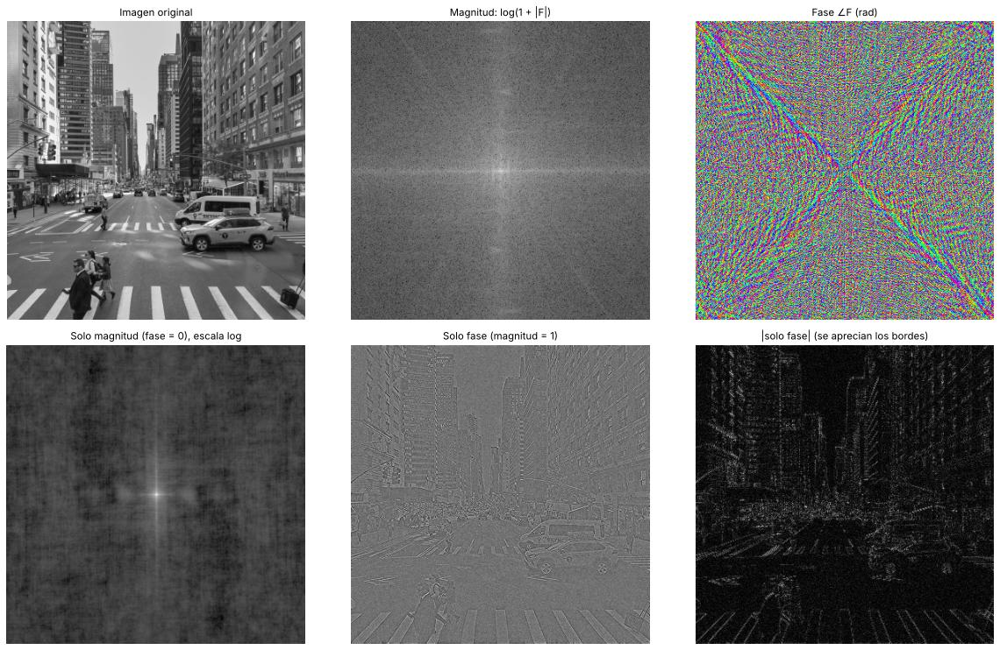

,reconstrucción,correlación con la imagen,correlación con el mapa de bordes
0,Solo magnitud,0.017,0.026
1,Solo fase,0.381,0.380


In [ ]:
F_D = espectro_D(img_D)
magnitud_D, fase_D = np.abs(F_D), np.angle(F_D)

solo_mag_D = np.real(np.fft.ifft2(np.fft.ifftshift(magnitud_D)))
solo_fase_D = np.real(np.fft.ifft2(np.fft.ifftshift(np.exp(1j * fase_D))))
solo_mag_vis_D = np.fft.fftshift(solo_mag_D)  # el origen queda en la esquina; se centra solo para mostrar

fig, ejes = plt.subplots(2, 3, figsize=(16, 10))
mostrar_imagen(img_D, "Imagen original", eje=ejes[0, 0])
ejes[0, 1].imshow(log_espectro_D(F_D), cmap="gray"); ejes[0, 1].set_title("Magnitud: log(1 + |F|)"); ejes[0, 1].axis("off")
ejes[0, 2].imshow(fase_D, cmap="hsv", vmin=-np.pi, vmax=np.pi); ejes[0, 2].set_title("Fase ∠F (rad)"); ejes[0, 2].axis("off")
ejes[1, 0].imshow(normalizar_visualizacion(np.log1p(np.abs(solo_mag_vis_D))), cmap="gray"); ejes[1, 0].set_title("Solo magnitud (fase = 0), escala log"); ejes[1, 0].axis("off")
ejes[1, 1].imshow(normalizar_visualizacion(solo_fase_D), cmap="gray"); ejes[1, 1].set_title("Solo fase (magnitud = 1)"); ejes[1, 1].axis("off")
ejes[1, 2].imshow(normalizar_visualizacion(np.abs(solo_fase_D)), cmap="gray"); ejes[1, 2].set_title("|solo fase| (se aprecian los bordes)"); ejes[1, 2].axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)

_, _, sobel_D, _ = gradiente_B(img_D, "Sobel")
def corr_D(a, b): return float(np.corrcoef(a.ravel(), b.ravel())[0, 1])
tabla_mag_fase_D = pd.DataFrame([
    {"reconstrucción": "Solo magnitud", "correlación con la imagen": corr_D(solo_mag_vis_D, img_D),
     "correlación con el mapa de bordes": corr_D(np.abs(solo_mag_vis_D), sobel_D)},
    {"reconstrucción": "Solo fase", "correlación con la imagen": corr_D(solo_fase_D, img_D),
     "correlación con el mapa de bordes": corr_D(np.abs(solo_fase_D), sobel_D)},
]).round(3)
display(tabla_mag_fase_D)

### D.2 — Paso bajo y paso alto: Ideal, Butterworth (n = 1, 2, 4) y Gaussiano
Primero, para D₀ = 30, se muestra la máscara $H(u,v)$, el espectro filtrado y el resultado (paso bajo y paso alto $H_{PA}=1-H_{PB}$). Después se barre D₀ = 10, 30, 60. El *ringing* se cuantifica con el sobreimpulso y subimpulso de un escalón ideal filtrado (en % del salto de 255 niveles) y con el lóbulo negativo de la respuesta al impulso $h=\mathcal{F}^{-1}\{H\}$.

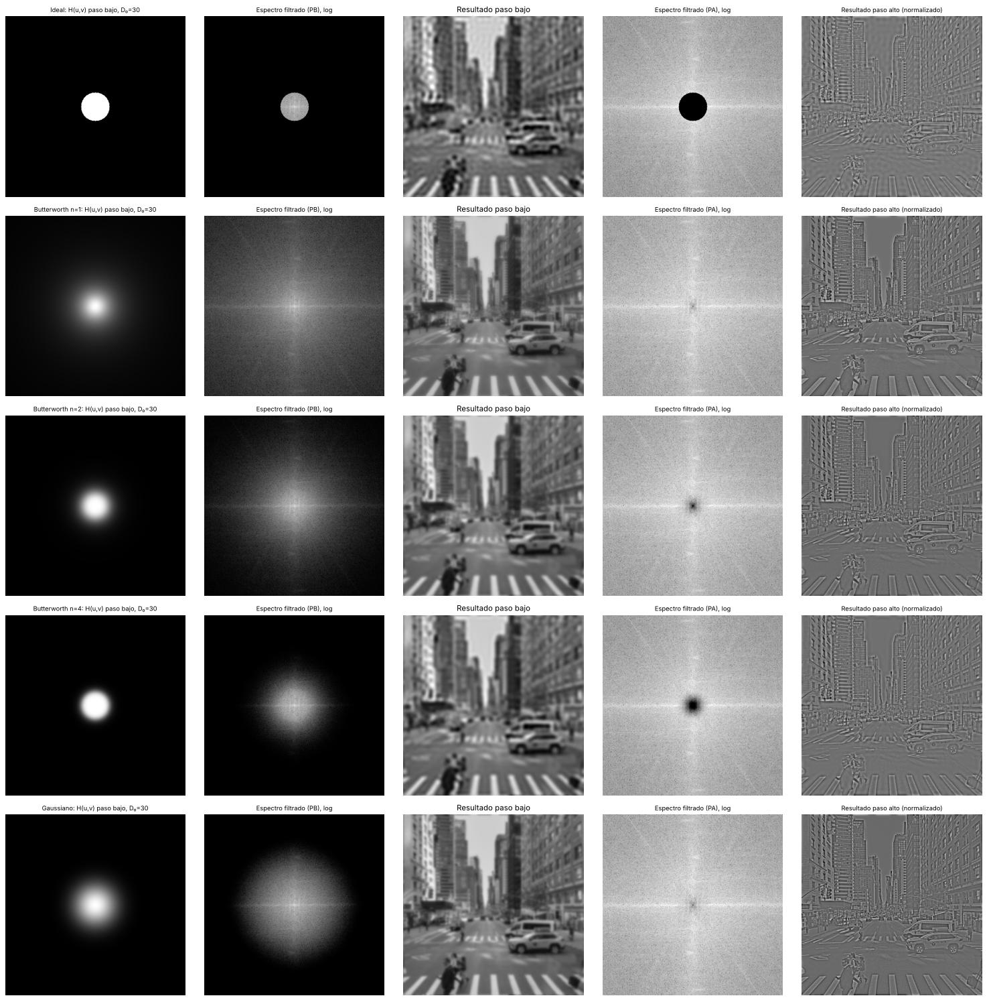

In [ ]:
filtros_D = {"Ideal": ("Ideal", 0), "Butterworth n=1": ("Butterworth", 1), "Butterworth n=2": ("Butterworth", 2),
             "Butterworth n=4": ("Butterworth", 4), "Gaussiano": ("Gaussiano", 0)}
D0_lista_D = (10, 30, 60)

def H_pb_D(nombre, D0):
    tipo, n = filtros_D[nombre]
    return mascara_pb_D(tipo, D0, n or 2)

D0_demo = 30
fig, ejes = plt.subplots(5, 5, figsize=(20, 20))
for i, nombre in enumerate(filtros_D):
    H = H_pb_D(nombre, D0_demo)
    res_pb, G_pb = filtrar_frecuencia_D(img_D, H)
    res_pa, G_pa = filtrar_frecuencia_D(img_D, 1 - H)
    ejes[i, 0].imshow(H, cmap="gray", vmin=0, vmax=1); ejes[i, 0].set_title(f"{nombre}: H(u,v) paso bajo, D₀={D0_demo}", fontsize=9)
    ejes[i, 1].imshow(log_espectro_D(G_pb), cmap="gray"); ejes[i, 1].set_title("Espectro filtrado (PB), log", fontsize=9)
    mostrar_imagen(a_uint8_D(res_pb), "Resultado paso bajo", eje=ejes[i, 2])
    ejes[i, 3].imshow(log_espectro_D(G_pa), cmap="gray"); ejes[i, 3].set_title("Espectro filtrado (PA), log", fontsize=9)
    ejes[i, 4].imshow(normalizar_visualizacion(res_pa), cmap="gray"); ejes[i, 4].set_title("Resultado paso alto (normalizado)", fontsize=9)
    for j in (0, 1, 3, 4): ejes[i, j].axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)

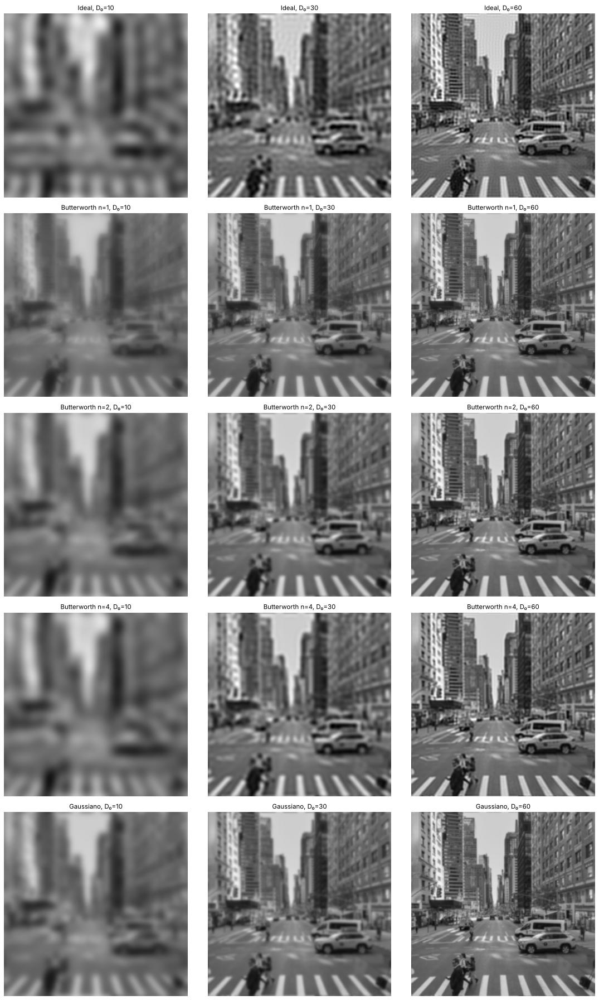

,filtro,D0,PSNR,SSIM,ringing: sobreimpulso en escalón (% del salto),ringing: subimpulso en escalón (% del salto)
0,Ideal,10,17.440,0.282,9.093,9.093
1,Ideal,30,20.585,0.461,9.032,9.032
2,Ideal,60,23.551,0.707,8.763,8.763
3,Butterworth n=1,10,18.583,0.384,-0.000,-0.000
4,Butterworth n=1,30,22.038,0.632,0.000,0.000
5,Butterworth n=1,60,25.288,0.819,0.006,0.006
6,Butterworth n=2,10,18.071,0.321,3.349,3.349
7,Butterworth n=2,30,21.414,0.554,3.370,3.370
8,Butterworth n=2,60,24.682,0.785,3.441,3.441
9,Butterworth n=4,10,17.813,0.301,6.804,6.804


In [ ]:
# Barrido D0 = 10, 30, 60 en paso bajo: imágenes y métricas
escalon_D = np.zeros((N_D, N_D)); escalon_D[:, N_D // 2:] = 255
fig, ejes = plt.subplots(5, 3, figsize=(15, 24))
filas_D2 = []
for i, nombre in enumerate(filtros_D):
    for j, D0 in enumerate(D0_lista_D):
        res, _ = filtrar_frecuencia_D(img_D, H_pb_D(nombre, D0))
        rec = a_uint8_D(res)
        mostrar_imagen(rec, f"{nombre}, D₀={D0}", eje=ejes[i, j])
        m = calcular_metricas(img_D, rec)
        esc, _ = filtrar_frecuencia_D(escalon_D, H_pb_D(nombre, D0))
        filas_D2.append({"filtro": nombre, "D0": D0, "PSNR": m["PSNR"], "SSIM": m["SSIM"],
                         "ringing: sobreimpulso en escalón (% del salto)": 100 * (esc.max() - 255) / 255,
                         "ringing: subimpulso en escalón (% del salto)": 100 * (0 - esc.min()) / 255})
fig.tight_layout(); plt.show(); plt.close(fig)
tabla_D2 = pd.DataFrame(filas_D2).round(3)
display(tabla_D2)

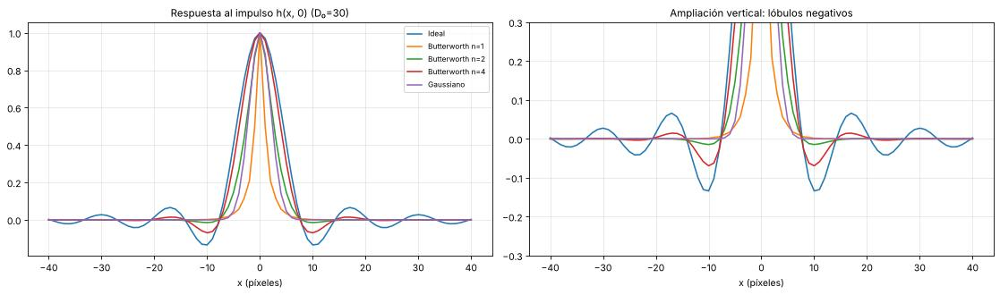

,filtro,mín h / máx h,# cruces por cero en el perfil
0,Ideal,-0.1346,12
1,Butterworth n=1,-0.0001,50
2,Butterworth n=2,-0.0145,22
3,Butterworth n=4,-0.0696,10
4,Gaussiano,-0.0000,0


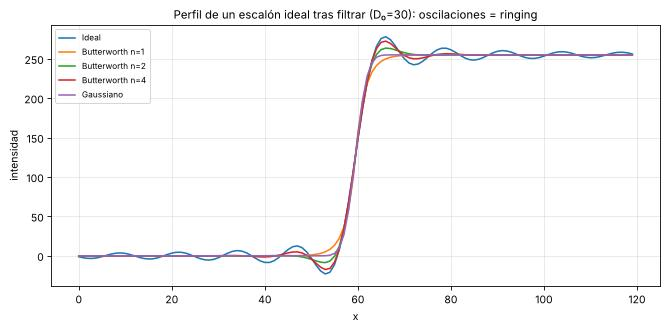

In [ ]:
# Respuesta al impulso espacial h = IFFT{H} (D0 = 30): un lóbulo negativo en h es la causa del ringing
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
filas_h_D = []
for nombre in filtros_D:
    h = np.real(np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(H_pb_D(nombre, 30)))))
    centro = N_D // 2
    perfil = h[centro, centro - 40:centro + 41] / h.max()
    x = np.arange(-40, 41)
    ejes[0].plot(x, perfil, label=nombre)
    ejes[1].plot(x, perfil, label=nombre)
    filas_h_D.append({"filtro": nombre, "mín h / máx h": float(h.min() / h.max()),
                      "# cruces por cero en el perfil": int(np.sum(np.diff(np.sign(perfil[np.abs(perfil) > 1e-6])) != 0))})
ejes[0].set_title("Respuesta al impulso h(x, 0) (D₀=30)"); ejes[0].set_xlabel("x (píxeles)"); ejes[0].legend(fontsize=8); ejes[0].grid(alpha=0.3)
ejes[1].set_ylim(-0.3, 0.3); ejes[1].set_title("Ampliación vertical: lóbulos negativos"); ejes[1].set_xlabel("x (píxeles)"); ejes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show(); plt.close(fig)
display(pd.DataFrame(filas_h_D).round(4))

# Ringing visible: un escalón claro/oscuro filtrado con cada filtro (D0 = 30)
fig, eje = plt.subplots(figsize=(9, 4.5))
for nombre in filtros_D:
    res, _ = filtrar_frecuencia_D(escalon_D, H_pb_D(nombre, 30))
    eje.plot(res[N_D // 2, N_D // 2 - 60:N_D // 2 + 60], label=nombre)
eje.set_title("Perfil de un escalón ideal tras filtrar (D₀=30): oscilaciones = ringing"); eje.set_xlabel("x"); eje.set_ylabel("intensidad"); eje.legend(fontsize=8); eje.grid(alpha=0.3)
fig.tight_layout(); plt.show(); plt.close(fig)

### D.3 — Eliminación de ruido periódico con filtro notch
Se suma a la imagen el patrón $20\sin(2\pi\cdot0.1\,x)$ (bandas verticales de periodo 10 px). En el espectro aparece como un par de picos simétricos en $(0,\pm0.1N)$. Se localizan automáticamente (máximo del espectro fuera de una vecindad del DC) y se eliminan con un notch Butterworth de rechazo (n = 2, radio 4 px) en ambos picos. El resultado se compara con el mejor filtro espacial de cada familia del Módulo A (media, Gaussiano, mediana, bilateral y Non-Local Means), elegido por SSIM entre varios parámetros.

Pico detectado (u, v) = (0, -38) y su simétrico (0, 38); esperado (0, ±38)


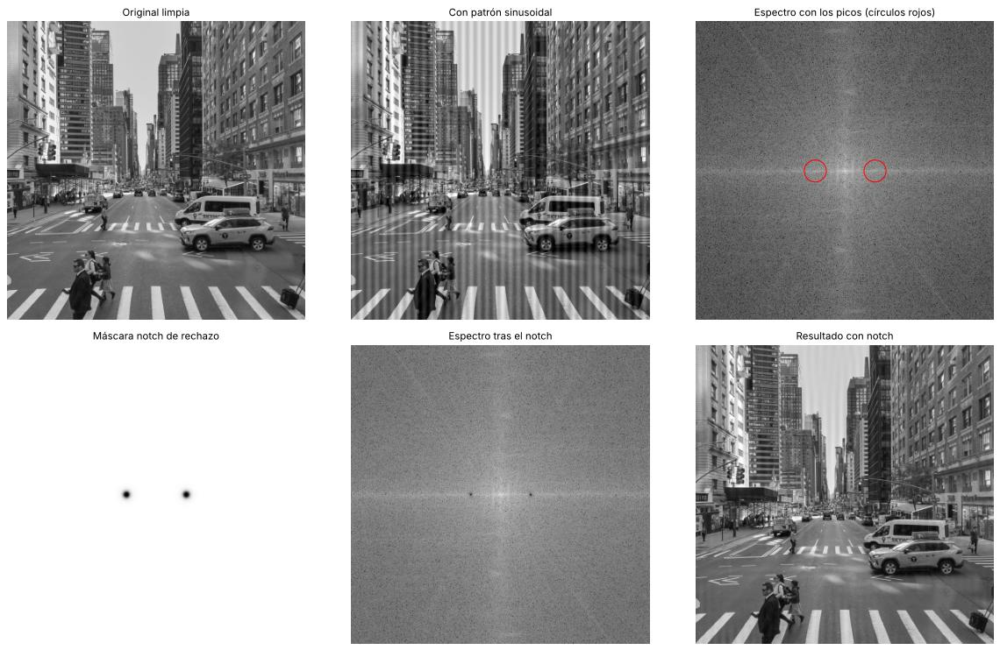

In [ ]:
x_D = np.arange(N_D)[None, :]
patron_D = 20 * np.sin(2 * np.pi * 0.1 * x_D)
ruidosa_D = img_D.astype(np.float64) + patron_D
ruidosa_u8_D = a_uint8_D(ruidosa_D)

Fr_D = espectro_D(ruidosa_D)
mag_r_D = np.abs(Fr_D)
excluir_D = DIST_D < 8
cand = np.where(excluir_D, 0, mag_r_D)
ip, jp = np.unravel_index(np.argmax(cand), cand.shape)
pico1_D = (int(ip - N_D // 2), int(jp - N_D // 2))
pico2_D = (-pico1_D[0], -pico1_D[1])
print(f"Pico detectado (u, v) = {pico1_D} y su simétrico {pico2_D}; esperado (0, ±{int(0.1 * N_D)})")


def notch_rechazo_D(picos, radio=4, n=2):
    H = np.ones((N_D, N_D))
    for (pu, pv) in picos:
        d = np.hypot(U_D - pu, V_D - pv)
        H *= 1.0 / (1.0 + (radio / np.maximum(d, 1e-9)) ** (2 * n))
    return H

H_notch_D = notch_rechazo_D([pico1_D, pico2_D])
res_notch_D, G_notch_D = filtrar_frecuencia_D(ruidosa_D, H_notch_D)
res_notch_u8_D = a_uint8_D(res_notch_D)

fig, ejes = plt.subplots(2, 3, figsize=(16, 10))
mostrar_imagen(img_D, "Original limpia", eje=ejes[0, 0])
mostrar_imagen(ruidosa_u8_D, "Con patrón sinusoidal", eje=ejes[0, 1])
ejes[0, 2].imshow(log_espectro_D(Fr_D), cmap="gray")
for p in (pico1_D, pico2_D):
    ejes[0, 2].add_patch(plt.Circle((p[1] + N_D // 2, p[0] + N_D // 2), 14, fill=False, color="red"))
ejes[0, 2].set_title("Espectro con los picos (círculos rojos)"); ejes[0, 2].axis("off")
ejes[1, 0].imshow(H_notch_D, cmap="gray", vmin=0, vmax=1); ejes[1, 0].set_title("Máscara notch de rechazo"); ejes[1, 0].axis("off")
ejes[1, 1].imshow(log_espectro_D(G_notch_D), cmap="gray"); ejes[1, 1].set_title("Espectro tras el notch"); ejes[1, 1].axis("off")
mostrar_imagen(res_notch_u8_D, "Resultado con notch", eje=ejes[1, 2])
fig.tight_layout(); plt.show(); plt.close(fig)

,método,parámetros,PSNR,SSIM
0,Sin filtrar (con patrón),-,25.0903,0.7239
1,Notch (frecuencia),"Butterworth n=2, r=4",34.7753,0.9725
2,Media (espacial),k=3,22.8554,0.5932
3,Gaussiano (espacial),σ=1,23.2019,0.6102
4,Mediana (espacial),k=3,23.1314,0.6078
5,Bilateral (espacial),"d=9, σc=25, σs=75",26.3895,0.7550
6,Non-Local Means (espacial),h=10,25.4774,0.7156


Mejor filtro espacial: Bilateral (espacial) d=9, σc=25, σs=75  (SSIM 0.7550)


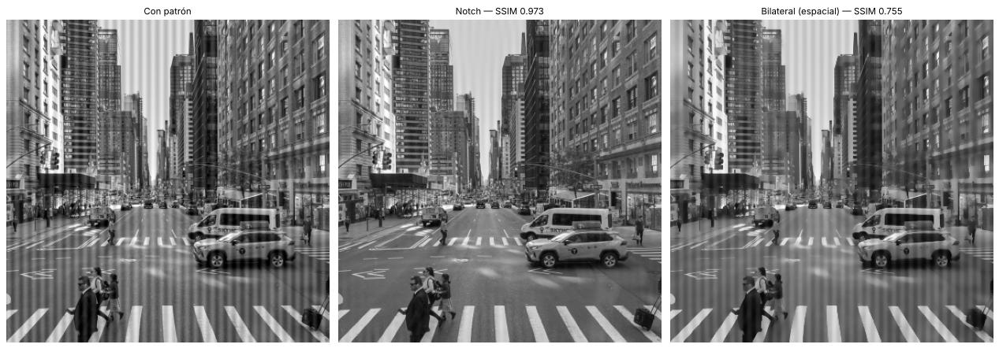

In [ ]:
# Candidatos espaciales (mismos operadores del Módulo A) con varios parámetros
candidatos_D = {
    "Media": [(f"k={k}", lambda x, k=k: cv2.blur(x, (k, k))) for k in (3, 5, 9, 11, 15)],
    "Gaussiano": [(f"σ={s}", lambda x, s=s: cv2.GaussianBlur(x, (0, 0), s)) for s in (1, 2, 3, 4)],
    "Mediana": [(f"k={k}", lambda x, k=k: cv2.medianBlur(x, k)) for k in (3, 5, 7, 9)],
    "Bilateral": [(f"d=9, σc={sc}, σs=75", lambda x, sc=sc: cv2.bilateralFilter(x, 9, sc, 75)) for sc in (25, 50, 75)],
    "Non-Local Means": [(f"h={h}", lambda x, h=h: cv2.fastNlMeansDenoising(x, None, h, 7, 21)) for h in (10, 20)],
}
filas_D3 = [{"método": "Sin filtrar (con patrón)", "parámetros": "-", **calcular_metricas(img_D, ruidosa_u8_D)},
            {"método": "Notch (frecuencia)", "parámetros": "Butterworth n=2, r=4", **calcular_metricas(img_D, res_notch_u8_D)}]
for familia, opciones in candidatos_D.items():
    mejor = None
    for etiqueta, fn in opciones:
        m = calcular_metricas(img_D, fn(ruidosa_u8_D))
        if mejor is None or m["SSIM"] > mejor["SSIM"]:
            mejor = {"método": familia + " (espacial)", "parámetros": etiqueta, **m}
    filas_D3.append(mejor)
tabla_D3 = pd.DataFrame(filas_D3).round(4)
display(tabla_D3)
mejor_espacial_D = tabla_D3.iloc[2:].sort_values("SSIM", ascending=False).iloc[0]
print(f"Mejor filtro espacial: {mejor_espacial_D['método']} {mejor_espacial_D['parámetros']}  (SSIM {mejor_espacial_D['SSIM']:.4f})")

fig, ejes = plt.subplots(1, 3, figsize=(17, 6))
mostrar_imagen(ruidosa_u8_D, "Con patrón", eje=ejes[0])
mostrar_imagen(res_notch_u8_D, f"Notch — SSIM {tabla_D3.loc[1, 'SSIM']:.3f}", eje=ejes[1])
mejor_fn = dict(candidatos_D[mejor_espacial_D["método"].replace(" (espacial)", "")])[mejor_espacial_D["parámetros"]]
mostrar_imagen(mejor_fn(ruidosa_u8_D), f"{mejor_espacial_D['método']} — SSIM {mejor_espacial_D['SSIM']:.3f}", eje=ejes[2])
fig.tight_layout(); plt.show(); plt.close(fig)

### D.4 — Equivalencia espacio–frecuencia
Un filtro Gaussiano paso bajo en frecuencia, $H=\exp(-D^2/2D_0^2)$, equivale a una convolución con un Gaussiano espacial de $\sigma\approx N/(2\pi D_0)$. Como la FFT implica convolución circular, la comparación exacta extiende la imagen de forma periódica (`np.pad(..., mode="wrap")`) antes de `cv2.GaussianBlur`, porque OpenCV no admite `BORDER_WRAP` en ese filtro; con `BORDER_REFLECT` (el modo habitual) se espera diferencia solo cerca de los bordes, de modo que también se mide el error en el interior.

,D0,σ espacial = N/(2πD0),error máx vs convolución circular,error máx vs BORDER_REFLECT (todo),error máx vs BORDER_REFLECT (interior)
0,10,6.048,9.54e-03,5.86e+01,8.63e-03
1,30,2.016,4.76e-03,5.61e+01,4.76e-03
2,60,1.008,1.04e-01,4.41e+01,1.04e-01


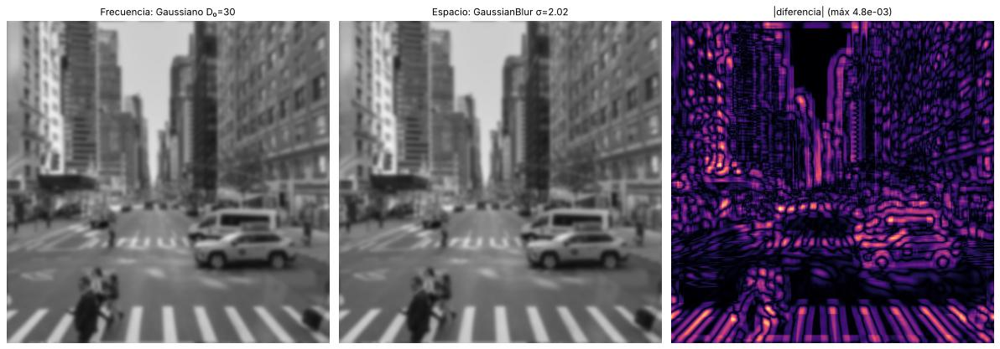

In [ ]:
def gauss_circular_D(gris, sigma):
    """GaussianBlur con condiciones de frontera periódicas (OpenCV no admite BORDER_WRAP en este filtro): se extiende con np.pad(mode='wrap')."""
    p = int(np.ceil(6 * sigma)) + 2
    ext = np.pad(gris.astype(np.float64), p, mode="wrap")
    return cv2.GaussianBlur(ext, (0, 0), sigma)[p:-p, p:-p]


filas_D4 = []
for D0 in D0_lista_D:
    sigma_esp = N_D / (2 * np.pi * D0)
    res_f, _ = filtrar_frecuencia_D(img_D, mascara_pb_D("Gaussiano", D0))
    res_wrap = gauss_circular_D(img_D, sigma_esp)
    res_refl = cv2.GaussianBlur(img_D.astype(np.float64), (0, 0), sigma_esp, borderType=cv2.BORDER_REFLECT)
    m = int(np.ceil(4 * sigma_esp))
    interior = (slice(m, -m), slice(m, -m))
    filas_D4.append({"D0": D0, "σ espacial = N/(2πD0)": sigma_esp,
                     "error máx vs convolución circular": np.abs(res_f - res_wrap).max(),
                     "error máx vs BORDER_REFLECT (todo)": np.abs(res_f - res_refl).max(),
                     "error máx vs BORDER_REFLECT (interior)": np.abs(res_f[interior] - res_refl[interior]).max()})
tabla_D4 = pd.DataFrame(filas_D4)
display(tabla_D4.style.format({"σ espacial = N/(2πD0)": "{:.3f}", "error máx vs convolución circular": "{:.2e}",
                               "error máx vs BORDER_REFLECT (todo)": "{:.2e}", "error máx vs BORDER_REFLECT (interior)": "{:.2e}"}))

fig, ejes = plt.subplots(1, 3, figsize=(16, 5.5))
D0 = 30; sg = N_D / (2 * np.pi * D0)
rf, _ = filtrar_frecuencia_D(img_D, mascara_pb_D("Gaussiano", D0))
re = gauss_circular_D(img_D, sg)
mostrar_imagen(a_uint8_D(rf), f"Frecuencia: Gaussiano D₀={D0}", eje=ejes[0])
mostrar_imagen(a_uint8_D(re), f"Espacio: GaussianBlur σ={sg:.2f}", eje=ejes[1])
ejes[2].imshow(np.abs(rf - re), cmap="magma"); ejes[2].set_title(f"|diferencia| (máx {np.abs(rf - re).max():.1e})"); ejes[2].axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)

### D.5 (extra) — Filtro homomórfico
Modelo de iluminación $f=i\cdot r$: el logaritmo lo vuelve aditivo, la iluminación (variación lenta) vive en bajas frecuencias y la reflectancia (detalle) en altas. Se aplica $H(u,v)=(\gamma_H-\gamma_L)\,[1-e^{-c\,D^2/D_0^2}]+\gamma_L$ con $\gamma_L=0.5$, $\gamma_H=1.8$, $c=1$, $D_0=30$, sobre la imagen natural con un gradiente de iluminación artificial.

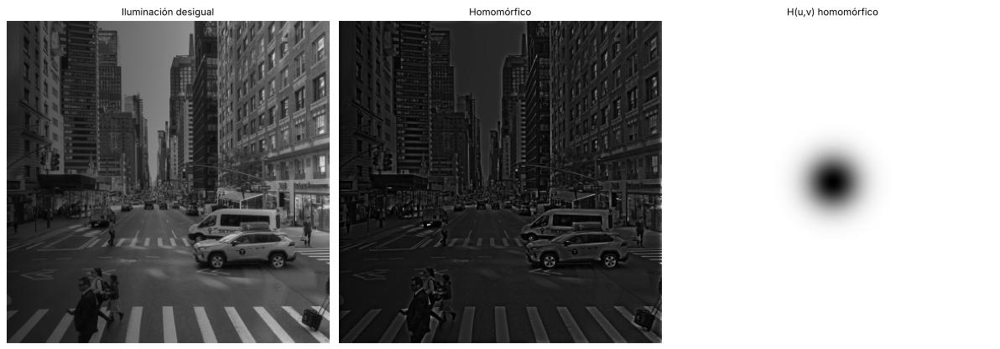

Media del tercio izquierdo / derecho  (diferencia = desigualdad de iluminación)
  original limpia  : [113.4  98.8]
  iluminación desig: [41.7 86.5]
  homomórfico      : [23.6 35.4]


In [ ]:
def homomorfico_D(gris, gamma_l=0.5, gamma_h=1.8, c=1.0, D0=30):
    logf = np.log1p(gris.astype(np.float64))
    H = (gamma_h - gamma_l) * (1 - np.exp(-c * DIST_D ** 2 / D0 ** 2)) + gamma_l
    res, _ = filtrar_frecuencia_D(logf, H)
    return np.expm1(res), H

rampa_D = np.tile(np.linspace(0.25, 1.0, N_D)[None, :], (N_D, 1))   # iluminación desigual (oscuro a la izquierda)
desigual_D = a_uint8_D(img_D.astype(np.float64) * rampa_D)
homo_D, H_homo_D = homomorfico_D(desigual_D)
homo_u8_D = cv2.normalize(homo_D, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, ejes = plt.subplots(1, 3, figsize=(16, 5.5))
mostrar_imagen(desigual_D, "Iluminación desigual", eje=ejes[0])
mostrar_imagen(homo_u8_D, "Homomórfico", eje=ejes[1])
ejes[2].imshow(H_homo_D, cmap="gray"); ejes[2].set_title("H(u,v) homomórfico"); ejes[2].axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)

medias_col = lambda x: np.array([x[:, :N_D // 3].mean(), x[:, 2 * N_D // 3:].mean()])
print("Media del tercio izquierdo / derecho  (diferencia = desigualdad de iluminación)")
print("  original limpia  :", medias_col(img_D).round(1))
print("  iluminación desig:", medias_col(desigual_D).round(1))
print("  homomórfico      :", medias_col(homo_u8_D).round(1))

### Medidas de costo: ¿espacio o frecuencia? (apoyo para la pregunta 1.8)
Se mide el tiempo de filtrar la imagen D con un kernel $k\times k$ en el espacio (`cv2.filter2D`) y en frecuencia (FFT → producto → IFFT, cuyo costo no depende de $k$). Nota: OpenCV ya cambia por dentro a un algoritmo basado en DFT para kernels grandes, así que además se estima el número de multiplicaciones de la convolución directa ($N^2k^2$) frente al de la ruta FFT (≈ $3\cdot N^2\log_2 N^2$ por las tres transformadas).

In [ ]:
import timeit
imagen_t = img_D.astype(np.float32)
filas_T = []
for k in (3, 7, 15, 31, 63, 127):
    kern = np.ones((k, k), np.float32) / (k * k)
    t_esp = min(timeit.repeat(lambda: cv2.filter2D(imagen_t, cv2.CV_32F, kern), number=3, repeat=3)) / 3
    def ruta_fft():
        K = np.zeros((N_D, N_D)); K[:k, :k] = 1 / (k * k)
        return np.real(np.fft.ifft2(np.fft.fft2(imagen_t) * np.fft.fft2(K)))
    t_fft = min(timeit.repeat(ruta_fft, number=3, repeat=3)) / 3
    filas_T.append({"k": k, "t filter2D (ms)": 1000 * t_esp, "t FFT (ms)": 1000 * t_fft,
                    "mult. directas N²k²": N_D ** 2 * k ** 2, "mult. FFT ≈ 3·N²·log₂N²": 3 * N_D ** 2 * np.log2(N_D ** 2)})
tabla_tiempos_D = pd.DataFrame(filas_T)
display(tabla_tiempos_D.style.format({"t filter2D (ms)": "{:.2f}", "t FFT (ms)": "{:.2f}", "mult. directas N²k²": "{:.2e}", "mult. FFT ≈ 3·N²·log₂N²": "{:.2e}"}))

,k,t filter2D (ms),t FFT (ms),mult. directas N²k²,mult. FFT ≈ 3·N²·log₂N²
0,3,0.07,7.02,1.30e+06,7.42e+06
1,7,0.29,6.93,7.08e+06,7.42e+06
2,15,2.20,7.22,3.25e+07,7.42e+06
3,31,2.05,6.73,1.39e+08,7.42e+06
4,63,3.34,6.76,5.73e+08,7.42e+06
5,127,3.14,6.74,2.33e+09,7.42e+06


### Pregunta 1.7 — Ringing
Filtrar en frecuencia equivale a convolucionar con $h=\mathcal{F}^{-1}\{H\}$. La máscara ideal es un disco (en 1D, una ventana rectangular), cuya transformada inversa es una función *jinc*/*sinc*: un lóbulo central y una cola de lóbulos **negativos y positivos** que decaen lentamente. Al convolucionar un borde con esa respuesta aparecen oscilaciones paralelas al borde: el efecto Gibbs. En el escalón de D.2 el sobreimpulso del filtro ideal es de ≈9 % del salto **para los tres D₀**: D₀ solo cambia el espaciado de los anillos, no su amplitud. El corte brusco es la causa. La respuesta al impulso del ideal tiene un mínimo de −0.135 veces su máximo y 12 cruces por cero en la ventana.

El Gaussiano es su propia transformada de Fourier (un Gaussiano): positivo en todas partes, sin lóbulos. $h\geq 0$, así que el resultado es un promedio ponderado positivo de los vecinos y no puede sobrepasar los valores originales: sobreimpulso 0 %, mínimo de $h$ ≈ 0. Butterworth está en medio, y el orden controla la pendiente del corte: n = 1 → 0 % de ringing, n = 2 → 3.4 %, n = 4 → 6.8 %. A mayor n, más se parece al ideal.

### Pregunta 1.8 — ¿Espacio o frecuencia?
Convolucionar en el espacio cuesta ≈ $N^2k^2$ multiplicaciones para un kernel $k\times k$ (o $2N^2k$ si es separable). La ruta de frecuencia cuesta ≈ $3N^2\log_2 N^2$ (dos FFT directas y una inversa) **sin depender de $k$**. Con N = 380, el punto de cruce teórico está en $k\approx7$ para un kernel no separable (tabla anterior: 7.4·10⁶ operaciones de la FFT frente a 1.3·10⁶, 7.1·10⁶ y 3.3·10⁷ de la convolución directa con $k$ = 3, 7 y 15).

Conviene filtrar en **frecuencia** cuando: el kernel es grande y no separable (más de unos 15×15 píxeles); se aplican muchos filtros a la misma imagen (la FFT de la imagen se calcula una vez); el filtro se define de forma natural en frecuencia (notch, rechaza-banda, Butterworth, homomórfico: expresarlo como kernel espacial sería enorme); o hay que analizar o visualizar el espectro. Conviene filtrar en el **espacio** cuando: el kernel es pequeño (3×3, 5×5, que es lo habitual en visión por computador); es separable (Gaussiano: dos pasadas 1D cuestan $2k$ por píxel); el filtro es no lineal (mediana, bilateral, NLM no tienen equivalente $H(u,v)$); o se necesitan los bordes correctamente tratados (la FFT asume imagen periódica y puede introducir artefactos si no se rellena).

Medido aquí, `cv2.filter2D` es más rápido que mi ruta con NumPy en todos los tamaños (≈0.1–4 ms frente a ≈7 ms): OpenCV usa SIMD y, para kernels grandes, ya conmuta internamente a un algoritmo basado en DFT (por eso su tiempo se aplana a partir de k ≈ 15). El resultado práctico es que con OpenCV rara vez hace falta pasar a frecuencia por velocidad: se hace por *capacidad* (filtros que solo existen en frecuencia).

### Conclusión del Módulo D
- La FFT concentra la estructura de la imagen en la **fase**: la reconstrucción solo con fase (correlación 0.38 con la imagen) conserva bordes y formas, mientras que solo con magnitud (0.02) se pierde por completo la estructura.
- Paso bajo con D₀ = 60: el Gaussiano es el mejor (PSNR 25.6 dB, SSIM 0.828), seguido de Butterworth n = 1 (25.3 dB, 0.819), sin ringing en ninguno de los dos. El ideal es el peor en SSIM a igual D₀ por los anillos (0.707 con D₀ = 60 frente a 0.828).
- Ruido periódico: el notch deja PSNR 34.8 dB / SSIM 0.973; el mejor filtro espacial (bilateral con σ_color = 25) solo llega a 26.4 dB / 0.755 y los de promedio o mediana empeoran la imagen respecto a la que tiene el patrón (SSIM 0.724). Un filtro espacial pasa bajo no puede separar un patrón de 10 px de periodo del detalle real de la imagen, mientras que el notch elimina solo dos puntos del espectro.
- Equivalencia: el Gaussiano en frecuencia coincide con `GaussianBlur` (σ = N/(2πD₀)) con error máximo ≤ 0.01 niveles para D₀ = 10 y 30 y 0.10 para D₀ = 60, que se debe a la discretización de un Gaussiano de σ ≈ 1 px. Las diferencias con `BORDER_REFLECT` están solo en el borde (la FFT es circular).

## Módulo E — Filtros direccionales y de textura: Gabor
Un filtro de Gabor es una sinusoide de longitud de onda $\lambda$ y orientación $\theta$ modulada por una envolvente Gaussiana de ancho $\sigma$. Se construye un banco de **4 orientaciones** (0°, 45°, 90°, 135°) × **3 longitudes de onda** (λ = 4, 8, 16 px) = 12 filtros con `cv2.getGaborKernel`, con $\sigma=0.56\,\lambda$ (ancho de banda de ≈ 1 octava), $\gamma=0.5$ y $\psi=0$. A cada kernel se le resta su media (respuesta nula a una región constante) y se normaliza con la norma L1 de sus valores absolutos para que las energías de distintas λ sean comparables.

Texturas de prueba: `imagen_3_ladrillos.jpg` (textura regular, con juntas horizontales y verticales) e `imagen_4_hoja.jpg` (textura orgánica). Se usa un recorte central de 256×256 px de cada una.

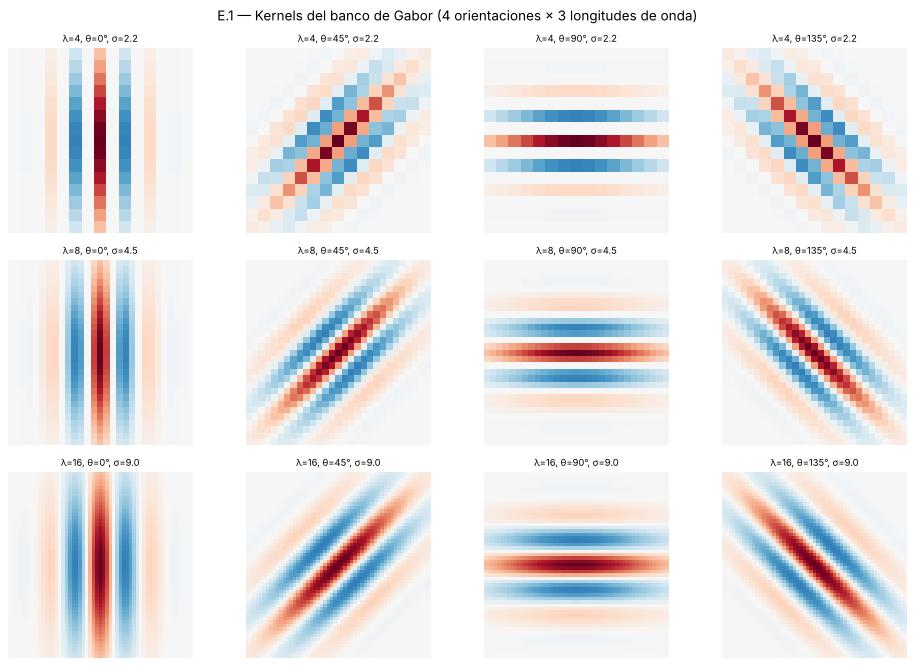

In [ ]:
LAMBDAS_E = (4, 8, 16)
THETAS_E = (0, 45, 90, 135)
GAMMA_E = 0.5


def banco_gabor_E(lambdas=LAMBDAS_E, thetas=THETAS_E, gamma=GAMMA_E):
    banco = []
    for lam in lambdas:
        sigma = 0.56 * lam
        ksize = int(2 * np.ceil(3 * sigma) + 1)
        for th in thetas:
            k = cv2.getGaborKernel((ksize, ksize), sigma, np.deg2rad(th), lam, gamma, 0, ktype=cv2.CV_32F)
            k -= k.mean()
            k /= np.abs(k).sum()
            banco.append({"lambda": lam, "theta": th, "sigma": sigma, "kernel": k})
    return banco


banco_E = banco_gabor_E()
assert len(banco_E) == 12


def recorte_central_E(gris, lado=256):
    f0 = (gris.shape[0] - lado) // 2
    c0 = (gris.shape[1] - lado) // 2
    return gris[f0:f0 + lado, c0:c0 + lado].copy()


texturas_E = {"Ladrillos": recorte_central_E(imagenes["imagen_3_ladrillos.jpg"]["trabajo"]["gris"]),
              "Hoja": recorte_central_E(imagenes["imagen_4_hoja.jpg"]["trabajo"]["gris"])}


def respuestas_gabor_E(gris, banco=banco_E):
    f = gris.astype(np.float32) / 255.0
    return [cv2.filter2D(f, cv2.CV_32F, b["kernel"], borderType=cv2.BORDER_REFLECT) for b in banco]


# E.1 — kernels
fig, ejes = plt.subplots(3, 4, figsize=(13, 9))
for eje, b in zip(ejes.flat, banco_E):
    lim = np.abs(b["kernel"]).max()
    eje.imshow(b["kernel"], cmap="RdBu_r", vmin=-lim, vmax=lim)
    eje.set_title(f"λ={b['lambda']}, θ={b['theta']}°, σ={b['sigma']:.1f}", fontsize=9)
    eje.axis("off")
fig.suptitle("E.1 — Kernels del banco de Gabor (4 orientaciones × 3 longitudes de onda)", fontsize=13)
fig.tight_layout(); plt.show(); plt.close(fig)

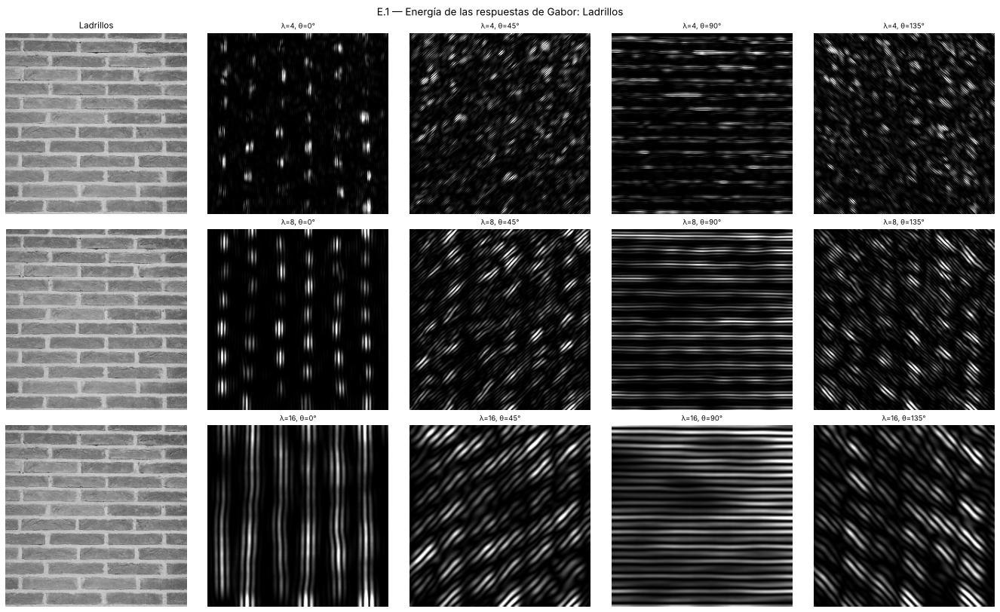

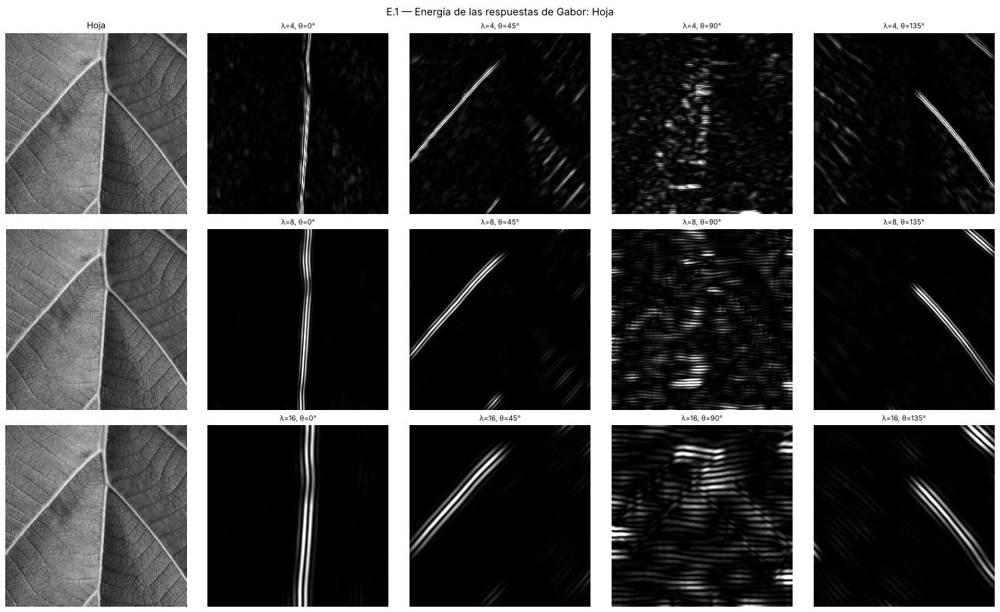

In [ ]:
# E.1 — respuestas (energía = respuesta²) sobre las dos texturas
resp_E = {nombre: respuestas_gabor_E(gris) for nombre, gris in texturas_E.items()}
for nombre, gris in texturas_E.items():
    fig, ejes = plt.subplots(3, 5, figsize=(18, 11))
    for i, lam in enumerate(LAMBDAS_E):
        mostrar_imagen(gris, nombre if i == 0 else "", eje=ejes[i, 0])
        for j, th in enumerate(THETAS_E):
            energia = resp_E[nombre][i * 4 + j] ** 2
            mostrar_magnitud_B(ejes[i, j + 1], energia, f"λ={lam}, θ={th}°", percentil=99.5)
    fig.suptitle(f"E.1 — Energía de las respuestas de Gabor: {nombre}", fontsize=13)
    fig.tight_layout(); plt.show(); plt.close(fig)

### E.2 — Vector de textura de 24 características
Para cada una de las 12 respuestas se calculan la **media** y la **desviación estándar** de su energía $E=r^2$; concatenadas dan un vector de 12 × 2 = 24 características, ordenado por λ, luego θ, y dentro de cada filtro (media, desviación). Se compara el vector de las dos texturas.

,Ladrillos,Hoja
λ4_θ0_media,5.542e-05,2.182e-04
λ4_θ0_std,1.790e-04,8.677e-04
λ4_θ45_media,2.111e-05,1.043e-04
λ4_θ45_std,3.842e-05,3.893e-04
λ4_θ90_media,4.630e-04,5.776e-05
λ4_θ90_std,1.007e-03,1.421e-04
λ4_θ135_media,2.247e-05,1.160e-04
λ4_θ135_std,4.117e-05,4.345e-04
λ8_θ0_media,7.281e-05,3.320e-04
λ8_θ0_std,2.055e-04,1.765e-03


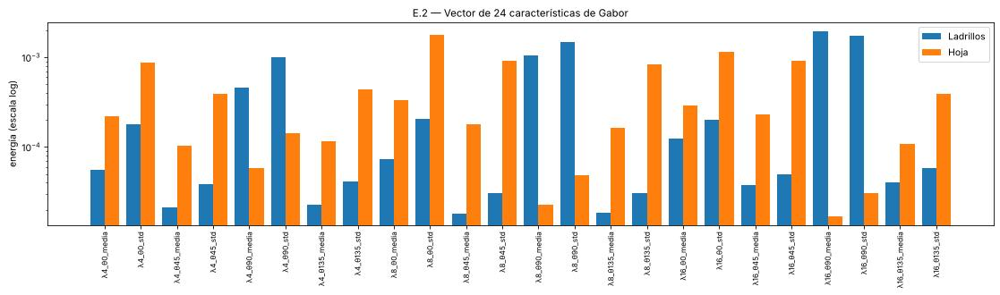

,distancia euclídea (log10),distancia coseno,cociente de energía media ladrillos/hoja (promedio de los 12 filtros)
0,5.379,0.8629,14.1456


Energía media por (λ, θ) — Ladrillos


,0°,45°,90°,135°
λ=4,5.542e-05,2.111e-05,4.630e-04,2.247e-05
λ=8,7.281e-05,1.807e-05,1.045e-03,1.861e-05
λ=16,1.237e-04,3.725e-05,1.942e-03,4.006e-05


Energía media por (λ, θ) — Hoja


,0°,45°,90°,135°
λ=4,2.182e-04,1.043e-04,5.776e-05,1.160e-04
λ=8,3.320e-04,1.785e-04,2.286e-05,1.647e-04
λ=16,2.903e-04,2.284e-04,1.704e-05,1.088e-04


In [ ]:
nombres_caract_E = [f"λ{b['lambda']}_θ{b['theta']}_{est}" for b in banco_E for est in ("media", "std")]


def vector_gabor_E(gris, banco=banco_E):
    v = []
    for r in respuestas_gabor_E(gris, banco):
        e = r.astype(np.float64) ** 2
        v += [e.mean(), e.std()]
    return np.array(v)


vectores_E = {nombre: vector_gabor_E(gris) for nombre, gris in texturas_E.items()}
assert all(v.shape == (24,) for v in vectores_E.values())
tabla_vectores_E = pd.DataFrame(vectores_E, index=nombres_caract_E)
display(tabla_vectores_E.style.format("{:.3e}"))

fig, eje = plt.subplots(figsize=(15, 4.5))
ancho = 0.4
x = np.arange(24)
eje.bar(x - ancho / 2, vectores_E["Ladrillos"], ancho, label="Ladrillos")
eje.bar(x + ancho / 2, vectores_E["Hoja"], ancho, label="Hoja")
eje.set_yscale("log"); eje.set_xticks(x); eje.set_xticklabels(nombres_caract_E, rotation=90, fontsize=8)
eje.set_ylabel("energía (escala log)"); eje.set_title("E.2 — Vector de 24 características de Gabor"); eje.legend()
fig.tight_layout(); plt.show(); plt.close(fig)

a, b = np.log10(vectores_E["Ladrillos"]), np.log10(vectores_E["Hoja"])
comparacion_E = pd.DataFrame([{
    "distancia euclídea (log10)": float(np.linalg.norm(a - b)),
    "distancia coseno": float(1 - np.dot(vectores_E['Ladrillos'], vectores_E['Hoja']) / (np.linalg.norm(vectores_E['Ladrillos']) * np.linalg.norm(vectores_E['Hoja']))),
    "cociente de energía media ladrillos/hoja (promedio de los 12 filtros)": float(np.mean(vectores_E['Ladrillos'][0::2] / vectores_E['Hoja'][0::2])),
}]).round(4)
display(comparacion_E)

# Energía media por orientación y longitud de onda
def matriz_energia_E(gris):
    v = vector_gabor_E(gris)[0::2]
    return pd.DataFrame(v.reshape(len(LAMBDAS_E), len(THETAS_E)), index=[f"λ={l}" for l in LAMBDAS_E], columns=[f"{t}°" for t in THETAS_E])

for nombre, gris in texturas_E.items():
    print(f"Energía media por (λ, θ) — {nombre}")
    display(matriz_energia_E(gris).style.format("{:.3e}"))

### Pregunta 1.9 — apoyo experimental: rotación de 90°
Se rota 90° el recorte de ladrillos (`np.rot90`, sin interpolación) y se recalculan las energías medias. Si el banco se comporta como se espera, el vector rotado debe ser una **permutación** del original: la respuesta del filtro de orientación θ pasa al filtro θ + 90°. Después se construye un descriptor invariante a esa rotación promediando (y tomando la dispersión de) las energías sobre las orientaciones, y se compara con el vector sin invariancia.

In [ ]:
rot_E = np.rot90(texturas_E["Ladrillos"]).copy()
M0 = matriz_energia_E(texturas_E["Ladrillos"])
M90 = matriz_energia_E(rot_E)
display(pd.concat({"original": M0, "rotada 90°": M90}, axis=1).style.format("{:.3e}"))

# ¿Qué permutación explica la rotación? 0↔90 y 45↔135
perm_E = [2, 3, 0, 1]   # índices de θ: 0→90, 45→135, 90→0, 135→45
M0p = M0.values[:, perm_E]
error_perm_E = np.abs(M90.values - M0p) / M0.values
print(f"Error relativo máximo entre la matriz rotada y la original permutada (θ→θ+90°): {error_perm_E.max():.3%}")
print(f"Error relativo máximo SIN permutar: {(np.abs(M90.values - M0.values) / M0.values).max():.1%}")


def descriptor_invariante_E(gris):
    """Por cada λ: media, desviación y máximo de la energía media sobre las 4 orientaciones (invariante a permutaciones de θ)."""
    M = matriz_energia_E(gris).values
    return np.concatenate([M.mean(axis=1), M.std(axis=1), M.max(axis=1)])


def dist_rel_E(u, v):
    return float(np.linalg.norm(np.log10(u) - np.log10(v)))

vec_orig = vector_gabor_E(texturas_E["Ladrillos"]); vec_rot = vector_gabor_E(rot_E); vec_hoja = vector_gabor_E(texturas_E["Hoja"])
inv_orig = descriptor_invariante_E(texturas_E["Ladrillos"]); inv_rot = descriptor_invariante_E(rot_E); inv_hoja = descriptor_invariante_E(texturas_E["Hoja"])
tabla_invarianza_E = pd.DataFrame([
    {"descriptor": "Vector de 24 (no invariante)", "ladrillos vs ladrillos rotados": dist_rel_E(vec_orig, vec_rot), "ladrillos vs hoja": dist_rel_E(vec_orig, vec_hoja)},
    {"descriptor": "Invariante (media/std/máx sobre θ)", "ladrillos vs ladrillos rotados": dist_rel_E(inv_orig, inv_rot), "ladrillos vs hoja": dist_rel_E(inv_orig, inv_hoja)},
]).round(4)
display(tabla_invarianza_E)

Error relativo máximo entre la matriz rotada y la original permutada (θ→θ+90°): 0.000%
Error relativo máximo SIN permutar: 1469.8%


,descriptor,ladrillos vs ladrillos rotados,ladrillos vs hoja
0,Vector de 24 (no invariante),3.4073,5.3790
1,Invariante (media/std/máx sobre θ),0.0000,1.6612


### Pregunta 1.9 — Orientación
Si se rota el objeto 90°, la textura que respondía al filtro de orientación θ pasa a responder al de θ + 90°: la energía **se permuta entre orientaciones** (0° ↔ 90° y 45° ↔ 135°) y las longitudes de onda se conservan. El experimento anterior lo confirma: con la textura de ladrillos, la matriz de energías rotada coincide con la original permutada con error relativo máximo 0.000 %, mientras que sin permutar el error llega al 1 470 %. Para clasificar, esto significa que el vector de 24 características de dos fotos del mismo objeto rotado queda *lejos* (distancia 3.4 en log₁₀, frente a 5.4 entre ladrillos y hoja), y el clasificador lo trataría casi como una clase distinta.

Para construir un descriptor invariante a la rotación:
1. **Agrupar sobre las orientaciones** (lo que se probó): para cada λ, la media, la desviación y el máximo de la energía sobre los θ. Para rotaciones de 90° es exactamente invariante (distancia 0.000), y sigue separando las texturas (1.66 entre ladrillos y hoja); lo que se pierde es la información de *hacia dónde* apunta la textura.
2. **Alinear con la orientación dominante**: rotar circularmente el vector de θ para que el filtro de mayor energía quede primero. Conserva la forma relativa del patrón direccional.
3. **Módulo de la DFT sobre el eje θ**: un desplazamiento circular de θ solo cambia la fase de esa DFT, no su módulo.
4. Para ángulos arbitrarios (no múltiplos de 45°) se necesitan más orientaciones (8–12) y la invariancia es aproximada; otra opción es aumentar los datos con rotaciones aleatorias en entrenamiento.

### Conclusión del Módulo E
- Los dos recortes se separan con claridad en el espacio de Gabor: los ladrillos concentran la energía en θ = 90° (≈1.9·10⁻³ con λ = 16, frente a ≈4·10⁻⁵ en 45°/135°), por las juntas largas en una sola dirección; la hoja reparte la energía entre orientaciones con un pico en 0° (≈3·10⁻⁴) y mucha mayor desviación estándar (≈10⁻³): su textura es más irregular.
- El vector de 24 características se puede reutilizar en la Parte 2 como una de las familias de textura, pero **no es invariante a la rotación**; como en el proyecto los objetos aparecerán rotados, se recomienda su versión agrupada sobre θ (o añadir LBP, que es invariante en su versión uniforme).

## Conclusiones generales de la Parte 1
**Qué filtro usar según el problema (con los datos del taller):**

| Situación | Filtro elegido | Evidencia |
|---|---|---|
| Ruido gaussiano | Non-Local Means (precisión) o Gaussiano pequeño σ ≈ 1 (velocidad) | Módulo A: NLM gana los cuatro casos gaussianos en PSNR/SSIM |
| Ruido sal y pimienta | Mediana 3×3–5×5 | Módulo A: gana todos los casos de sal y pimienta; la media solo difumina (P1.1) |
| Un solo filtro fijo para todo | Mediana 3×3 | Módulo A: `mejor_config_global_A`, PSNR medio 28.5 dB, SSIM medio 0.779 |
| Preservar bordes mientras se suaviza | Bilateral | Módulo A (P1.3) y D.3: el mejor filtro espacial frente al patrón periódico |
| Ruido periódico | Notch en frecuencia | D.3: SSIM 0.973 frente a 0.755 del mejor espacial |
| Exposición incorrecta | Estiramiento 2–98 % o gamma/log | Módulo C: sube σ de 15 a ≈67 (estiramiento) |
| Gradientes para HOG / forma | Sobel o Scharr en `float64` con suavizado previo; no `CV_8U` | Módulo B: con `CV_8U` se pierde el 47 % de las respuestas |
| Textura | Banco de Gabor agrupado sobre θ | Módulo E: separa ladrillos de hoja y es invariante a rotaciones de 90° |

**Para la Parte 2.** Se propone el preprocesamiento: (1) redimensionar con `INTER_AREA`; (2) suavizado con mediana 3×3 (o Gaussiano σ = 1 si el ruido es gaussiano), (3) estiramiento de contraste o CLAHE si la exposición varía, (4) Otsu o HSV para segmentar, y (5) para el HOG, gradientes con Sobel en `float64`. Cada una de estas elecciones se apoya en las tablas de PSNR/SSIM y en las matrices visuales de este notebook, como pide el enunciado.

In [ ]:
# Validación de los Módulos B–E
assert np.abs(laplaciano_B(img_nat_B, k_lap4_B) - cv2.Laplacian(img_nat_B.astype(np.float64), cv2.CV_64F, ksize=1, borderType=cv2.BORDER_REPLICATE)).max() < 1e-9
assert len(gradientes_B) == 8 and all(v[2].dtype == np.float64 for v in gradientes_B.values())
assert tabla_canny_B.shape[0] == 18 and tabla_canny_B["% píxeles borde"].between(0, 100).all()
assert (pd.DataFrame(filas_unsharp_B)["% píxeles saturados (<0 o >255)"].diff().dropna() > 0).all()   # más k → más saturación
assert all(lut.shape == (256,) and lut.dtype == np.uint8 for lut in luts_C.values()) and len(luts_C) == 6
assert tabla_C.shape[0] == 14 and abs(tabla_C.loc[tabla_C.transformación == "Negativo", "desv. estándar"].values - tabla_C.loc[tabla_C.transformación == "Sin corregir", "desv. estándar"].values).max() < 1e-6
assert resumen_espectro_C["% píxeles ≥ 1 % del máx en escala log"].iloc[0] > resumen_espectro_C["% píxeles ≥ 1 % del máx en escala lineal"].iloc[0]
assert tabla_D2.shape[0] == 15
assert tabla_D2.loc[tabla_D2.filtro == "Gaussiano", "ringing: sobreimpulso en escalón (% del salto)"].max() < 0.1
assert tabla_D2.loc[tabla_D2.filtro == "Ideal", "ringing: sobreimpulso en escalón (% del salto)"].min() > 8
assert pico1_D == (0, -int(0.1 * N_D)) or pico1_D == (0, int(0.1 * N_D))
assert tabla_D3.loc[1, "SSIM"] > tabla_D3.iloc[2:]["SSIM"].max()
assert tabla_D4["error máx vs convolución circular"].max() < 0.5 and tabla_D4["error máx vs BORDER_REFLECT (interior)"].max() < 0.5
assert len(banco_E) == 12 and all(v.shape == (24,) for v in vectores_E.values())
assert error_perm_E.max() < 1e-3 and tabla_invarianza_E.iloc[1, 1] < 1e-6
for nombre, ruta_imagen in rutas_imagenes.items():
    assert hashlib.sha256(ruta_imagen.read_bytes()).hexdigest() == hashes_originales[nombre]
print("Validación de los Módulos B–E completa; imágenes originales intactas.")


Validación de los Módulos B–E completa; imágenes originales intactas.
